<a href="https://colab.research.google.com/github/tharini123bandara/my-project/blob/master/Predicting_Credit_Defaulters_Using_Loan_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Import Libraries**

In [335]:
# ============================================================
# 1. Install & Import Required Libraries
# ============================================================

# Install pyspark if not already installed
!pip install pyspark

# Core PySpark imports
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

# MLlib imports for machine learning
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml import Pipeline

# For splitting data
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

# Visualization & plotting
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


starts Spark

In [336]:

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("LoanDefaultAnalysis") \
    .getOrCreate()

print("Spark version:", spark.version)


Spark version: 3.5.1


**Load dataset**

In [337]:
from google.colab import drive
drive.mount('/content/drive')

# File path
file_path = "/content/drive/MyDrive/Untitled folder/loan.csv"

# Load dataset in Spark
df_spark = spark.read.csv(
    file_path,
    header=True,        # First row has column names
    inferSchema=True,   # Let Spark detect column types
    multiLine=True,     # Handles records that span multiple lines
    escape='"'          # Handles quotes properly
)

# Check rows and columns
print("Number of rows (Spark):", df_spark.count())
print("Number of columns (Spark):", len(df_spark.columns))

# Print schema
df_spark.printSchema()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Number of rows (Spark): 887379
Number of columns (Spark): 74
root
 |-- id: integer (nullable = true)
 |-- member_id: integer (nullable = true)
 |-- loan_amnt: double (nullable = true)
 |-- funded_amnt: double (nullable = true)
 |-- funded_amnt_inv: double (nullable = true)
 |-- term: string (nullable = true)
 |-- int_rate: double (nullable = true)
 |-- installment: double (nullable = true)
 |-- grade: string (nullable = true)
 |-- sub_grade: string (nullable = true)
 |-- emp_title: string (nullable = true)
 |-- emp_length: string (nullable = true)
 |-- home_ownership: string (nullable = true)
 |-- annual_inc: double (nullable = true)
 |-- verification_status: string (nullable = true)
 |-- issue_d: string (nullable = true)
 |-- loan_status: string (nullable = true)
 |-- pymnt_plan: string (nullable = true)
 |-- url: string (nullable = true)
 |-- desc: string (

**Basic EDA in PySpark**

In [338]:
# 1. Preview data
df_spark.show(5, truncate=False)

+-------+---------+---------+-----------+---------------+----------+--------+-----------+-----+---------+------------------------+----------+--------------+----------+-------------------+--------+-----------+----------+--------------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------------+--------------------+--------+----------+-----+-----------+----------------+--------------+---------------

In [339]:
# 2. Shape of data
print(f"Rows: {df_spark.count()}, Columns: {len(df_spark.columns)}")


Rows: 887379, Columns: 74


In [340]:
# 3. Column names
print("Columns:", df_spark.columns)

Columns: ['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_il_6m', 'open_il_12m',

In [341]:
# 4. Summary statistics for numeric columns
df_spark.describe(["loan_amnt", "funded_amnt", "annual_inc", "int_rate", "dti"]).show()

+-------+-----------------+------------------+-----------------+------------------+------------------+
|summary|        loan_amnt|       funded_amnt|       annual_inc|          int_rate|               dti|
+-------+-----------------+------------------+-----------------+------------------+------------------+
|  count|           887379|            887379|           887375|            887379|            887379|
|   mean|14755.26460508982|14741.877625005776|75027.58776076681|13.246739679476775|18.157038739929448|
| stddev|8435.455601278538| 8429.897656714602|64698.30014240652| 4.381867414712336|17.190625687941328|
|    min|            500.0|             500.0|              0.0|              5.32|               0.0|
|    max|          35000.0|           35000.0|        9500000.0|             28.99|            9999.0|
+-------+-----------------+------------------+-----------------+------------------+------------------+



Average loan amount ≈ $14.7k  with std dev ≈ $8.4k (quite spread out).

Average interest rate ≈ 13.2% (reasonable, but can go up to 28.99%).

annual_inc has a very wide range (0 to $9.5 million) → clear outliers.

dti (Debt-to-Income) is mostly normal but has extreme values up to 9999, which are invalid.

In [342]:
# 5. Check class distribution for target variable (loan_status)
df_spark.groupBy("loan_status").count().orderBy(F.desc("count")).show()


+--------------------+------+
|         loan_status| count|
+--------------------+------+
|             Current|601779|
|          Fully Paid|207723|
|         Charged Off| 45248|
|  Late (31-120 days)| 11591|
|              Issued|  8460|
|     In Grace Period|  6253|
|   Late (16-30 days)|  2357|
|Does not meet the...|  1988|
|             Default|  1219|
|Does not meet the...|   761|
+--------------------+------+



Highly imbalanced dataset:

“Current” ≈ 68% (601k rows).

“Fully Paid” ≈ 23%.

“Charged Off” ≈ 5%.

“Default” & late categories are very small.

**Filtering Active Loans (`Current` and `Issued`)**

- The `Current` and `Issued` loan statuses represent loans that are still active and have no finalized outcome (e.g., fully paid or defaulted).  
- Including these loans in modeling could introduce noise, as their ultimate repayment status is unknown.  
- Removing these rows ensures the dataset only contains loans with **definitive outcomes**, which improves model reliability and accuracy.  
- Another reason for filtering is **performance**: the dataset contains a very large number of active loans, which slows down Spark operations. Removing them reduces runtime and speeds up subsequent processing.  
- After filtering, the distribution of `loan_status` is checked to confirm the remaining classes and their counts.


In [343]:
from pyspark.sql import functions as F

# Remove 'Current' and 'Issued' rows
df_spark = df_spark.filter(~F.col("loan_status").isin(["Current", "Issued"]))

# Check number of rows and distribution of loan_status
print("Number of rows after filtering:", df_spark.count())
df_spark.groupBy("loan_status").count().orderBy(F.desc("count")).show()


Number of rows after filtering: 277140
+--------------------+------+
|         loan_status| count|
+--------------------+------+
|          Fully Paid|207723|
|         Charged Off| 45248|
|  Late (31-120 days)| 11591|
|     In Grace Period|  6253|
|   Late (16-30 days)|  2357|
|Does not meet the...|  1988|
|             Default|  1219|
|Does not meet the...|   761|
+--------------------+------+



In [344]:
# 6. Missing values count per column
missing_df = df_spark.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_spark.columns])
missing_df.show(vertical=True, truncate=False)

-RECORD 0-----------------------------
 id                          | 0      
 member_id                   | 0      
 loan_amnt                   | 0      
 funded_amnt                 | 0      
 funded_amnt_inv             | 0      
 term                        | 0      
 int_rate                    | 0      
 installment                 | 0      
 grade                       | 0      
 sub_grade                   | 0      
 emp_title                   | 15388  
 emp_length                  | 0      
 home_ownership              | 0      
 annual_inc                  | 4      
 verification_status         | 0      
 issue_d                     | 0      
 loan_status                 | 0      
 pymnt_plan                  | 0      
 url                         | 0      
 desc                        | 184479 
 purpose                     | 0      
 title                       | 14     
 zip_code                    | 0      
 addr_state                  | 0      
 dti                     

annual_inc_joint, dti_joint, verification_status_joint (joint applications).

mths_since_last_record, mths_since_last_major_derog (>70% null).

desc (>85% null).

These are not useful → drop.

Others like emp_title, revol_util, inq_last_6mths have partial missingness → can be imputed (mode/median).

Computes the missing percentage of each column.

Selects only those with >70% missing.

Drops them automatically (no manual typing needed).

In [345]:
from pyspark.sql.functions import col, count, when

# total rows
total_count = df_spark.count()

# calculate missing ratio for each column
missing_ratio = (
    df_spark.select([
        (count(when(col(c).isNull(), c)) / total_count).alias(c)
        for c in df_spark.columns
    ])
    .collect()[0]
    .asDict()
)

# find columns with >70% missing
cols_to_drop = [c for c, ratio in missing_ratio.items() if ratio > 0.7]

print("Columns to drop:", cols_to_drop)

# drop them
df_clean = df_spark.drop(*cols_to_drop)

print("Before:", len(df_spark.columns), "columns")
print("After:", len(df_clean.columns), "columns")


Columns to drop: ['mths_since_last_record', 'next_pymnt_d', 'mths_since_last_major_derog', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m']
Before: 74 columns
After: 54 columns


In the loan dataset there are some columns (like annual_inc_joint, dti_joint, verification_status_joint) which only get filled if two people applied for the loan together.

But in most loans, only one person applied → so those columns are mostly empty (missing values).

In [346]:
# 6. Missing values count per column
missing_df = df_clean.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_clean.columns])
missing_df.show(vertical=True, truncate=False)

-RECORD 0----------------------------
 id                         | 0      
 member_id                  | 0      
 loan_amnt                  | 0      
 funded_amnt                | 0      
 funded_amnt_inv            | 0      
 term                       | 0      
 int_rate                   | 0      
 installment                | 0      
 grade                      | 0      
 sub_grade                  | 0      
 emp_title                  | 15388  
 emp_length                 | 0      
 home_ownership             | 0      
 annual_inc                 | 4      
 verification_status        | 0      
 issue_d                    | 0      
 loan_status                | 0      
 pymnt_plan                 | 0      
 url                        | 0      
 desc                       | 184479 
 purpose                    | 0      
 title                      | 14     
 zip_code                   | 0      
 addr_state                 | 0      
 dti                        | 0      
 delinq_2yrs

Identifiers (not useful):

id

member_id

url

zip_code (too granular + privacy concern)

In [347]:
# List of ID/identifier columns to drop
id_cols = ["id", "member_id", "url", "zip_code"]

# Drop them
df_clean = df_clean.drop(*id_cols)

# Check remaining columns
print("Columns after dropping identifiers:", df_clean.columns)
print("Total columns:", len(df_clean.columns))

Columns after dropping identifiers: ['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'desc', 'purpose', 'title', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'policy_code', 'application_type', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim']
Total columns: 50


check all the data types

In [348]:
# Print schema
df_clean.printSchema()

root
 |-- loan_amnt: double (nullable = true)
 |-- funded_amnt: double (nullable = true)
 |-- funded_amnt_inv: double (nullable = true)
 |-- term: string (nullable = true)
 |-- int_rate: double (nullable = true)
 |-- installment: double (nullable = true)
 |-- grade: string (nullable = true)
 |-- sub_grade: string (nullable = true)
 |-- emp_title: string (nullable = true)
 |-- emp_length: string (nullable = true)
 |-- home_ownership: string (nullable = true)
 |-- annual_inc: double (nullable = true)
 |-- verification_status: string (nullable = true)
 |-- issue_d: string (nullable = true)
 |-- loan_status: string (nullable = true)
 |-- pymnt_plan: string (nullable = true)
 |-- desc: string (nullable = true)
 |-- purpose: string (nullable = true)
 |-- title: string (nullable = true)
 |-- addr_state: string (nullable = true)
 |-- dti: double (nullable = true)
 |-- delinq_2yrs: double (nullable = true)
 |-- earliest_cr_line: string (nullable = true)
 |-- inq_last_6mths: double (nullable = t

In [349]:
# List of columns with their data types
for field in df_clean.schema.fields:
    print(f"{field.name}: {field.dataType}")

loan_amnt: DoubleType()
funded_amnt: DoubleType()
funded_amnt_inv: DoubleType()
term: StringType()
int_rate: DoubleType()
installment: DoubleType()
grade: StringType()
sub_grade: StringType()
emp_title: StringType()
emp_length: StringType()
home_ownership: StringType()
annual_inc: DoubleType()
verification_status: StringType()
issue_d: StringType()
loan_status: StringType()
pymnt_plan: StringType()
desc: StringType()
purpose: StringType()
title: StringType()
addr_state: StringType()
dti: DoubleType()
delinq_2yrs: DoubleType()
earliest_cr_line: StringType()
inq_last_6mths: DoubleType()
mths_since_last_delinq: DoubleType()
open_acc: DoubleType()
pub_rec: DoubleType()
revol_bal: DoubleType()
revol_util: DoubleType()
total_acc: DoubleType()
initial_list_status: StringType()
out_prncp: DoubleType()
out_prncp_inv: DoubleType()
total_pymnt: DoubleType()
total_pymnt_inv: DoubleType()
total_rec_prncp: DoubleType()
total_rec_int: DoubleType()
total_rec_late_fee: DoubleType()
recoveries: DoubleTy

Check unique value counts for categorical columns → see which ones are useful.

1. Data overview

In [350]:
# Shape
print(f"Rows: {df_clean.count()}, Columns: {len(df_clean.columns)}")


Rows: 277140, Columns: 50


In [351]:
# Show first 5 rows
df_clean.show(5, truncate=False)

+---------+-----------+---------------+----------+--------+-----------+-----+---------+--------------------+----------+--------------+----------+-------------------+--------+-----------+----------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------------+-------------------------------------+----------+-----+-----------+----------------+--------------+----------------------+--------+-------+---------+----------+---------+-------------------+-------

convert date columns to date type

Data types

In [354]:
from pyspark.sql.functions import unix_timestamp, to_date, col

# Columns to convert
date_cols = ["issue_d", "earliest_cr_line", "last_pymnt_d", "last_credit_pull_d"]

# Convert safely
for col_name in date_cols:
    if col_name in df_clean.columns:
        df_clean = df_clean.withColumn(
            col_name,
            to_date(unix_timestamp(col_name, 'MMM-yyyy').cast('timestamp'))
        )

df_clean.printSchema()


root
 |-- loan_amnt: double (nullable = true)
 |-- funded_amnt: double (nullable = true)
 |-- funded_amnt_inv: double (nullable = true)
 |-- term: string (nullable = true)
 |-- int_rate: double (nullable = true)
 |-- installment: double (nullable = true)
 |-- grade: string (nullable = true)
 |-- sub_grade: string (nullable = true)
 |-- emp_title: string (nullable = true)
 |-- emp_length: string (nullable = true)
 |-- home_ownership: string (nullable = true)
 |-- annual_inc: double (nullable = true)
 |-- verification_status: string (nullable = true)
 |-- issue_d: date (nullable = true)
 |-- loan_status: string (nullable = true)
 |-- pymnt_plan: string (nullable = true)
 |-- desc: string (nullable = true)
 |-- purpose: string (nullable = true)
 |-- title: string (nullable = true)
 |-- addr_state: string (nullable = true)
 |-- dti: double (nullable = true)
 |-- delinq_2yrs: double (nullable = true)
 |-- earliest_cr_line: date (nullable = true)
 |-- inq_last_6mths: double (nullable = true)

Unique Value counts of the columns

In [355]:
# Loop through all columns and print unique value counts
for col_name in df_clean.columns:
    unique_count = df_clean.select(col_name).distinct().count()
    print(f"{col_name}: {unique_count} unique values")



loan_amnt: 1344 unique values
funded_amnt: 1344 unique values
funded_amnt_inv: 9570 unique values
term: 2 unique values
int_rate: 535 unique values
installment: 48141 unique values
grade: 7 unique values
sub_grade: 35 unique values
emp_title: 141469 unique values
emp_length: 12 unique values
home_ownership: 6 unique values
annual_inc: 20925 unique values
verification_status: 3 unique values
issue_d: 103 unique values
loan_status: 8 unique values
pymnt_plan: 2 unique values
desc: 91911 unique values
purpose: 14 unique values
title: 50184 unique values
addr_state: 51 unique values
dti: 3996 unique values
delinq_2yrs: 25 unique values
earliest_cr_line: 650 unique values
inq_last_6mths: 29 unique values
mths_since_last_delinq: 128 unique values
open_acc: 60 unique values
pub_rec: 16 unique values
revol_bal: 48937 unique values
revol_util: 1231 unique values
total_acc: 111 unique values
initial_list_status: 2 unique values
out_prncp: 19435 unique values
out_prncp_inv: 19634 unique values
to

In [356]:
from pyspark.sql.functions import countDistinct

# Loop through all columns
for c in df_clean.columns:
    unique_count = df_clean.select(countDistinct(c)).collect()[0][0]

    # If unique values < 20, show the actual unique values
    if unique_count < 20:
        print(f"\nColumn: {c} - Unique Values ({unique_count}):")
        df_clean.select(c).distinct().show(truncate=False)



Column: term - Unique Values (2):
+----------+
|term      |
+----------+
| 36 months|
| 60 months|
+----------+


Column: grade - Unique Values (7):
+-----+
|grade|
+-----+
|F    |
|E    |
|B    |
|D    |
|C    |
|A    |
|G    |
+-----+


Column: emp_length - Unique Values (12):
+----------+
|emp_length|
+----------+
|9 years   |
|5 years   |
|1 year    |
|n/a       |
|2 years   |
|7 years   |
|8 years   |
|4 years   |
|6 years   |
|3 years   |
|10+ years |
|< 1 year  |
+----------+


Column: home_ownership - Unique Values (6):
+--------------+
|home_ownership|
+--------------+
|OWN           |
|RENT          |
|MORTGAGE      |
|ANY           |
|OTHER         |
|NONE          |
+--------------+


Column: verification_status - Unique Values (3):
+-------------------+
|verification_status|
+-------------------+
|Verified           |
|Source Verified    |
|Not Verified       |
+-------------------+


Column: loan_status - Unique Values (8):
+----------------------------------------------

addr_state unique values

In [357]:
# Get distinct values of addr_state
unique_states = df_clean.select("addr_state").distinct().orderBy("addr_state")

# Collect them into a Python list
unique_states_list = [row["addr_state"] for row in unique_states.collect()]
# Print each state on a new line
for state in unique_states_list:
    print(state)


AK
AL
AR
AZ
CA
CO
CT
DC
DE
FL
GA
HI
IA
ID
IL
IN
KS
KY
LA
MA
MD
ME
MI
MN
MO
MS
MT
NC
ND
NE
NH
NJ
NM
NV
NY
OH
OK
OR
PA
RI
SC
SD
TN
TX
UT
VA
VT
WA
WI
WV
WY


Since PySpark has limited plotting, we’ll convert to Pandas for visualizations.

## **Borrower Profile Analysis**

# Employment Length Distribution

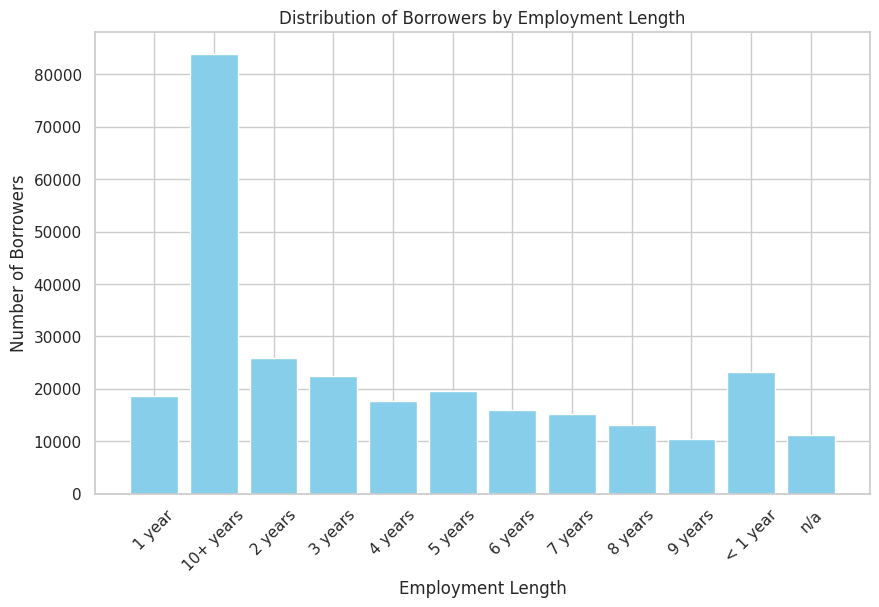

In [358]:
import matplotlib.pyplot as plt
import pandas as pd

# Count of borrowers by employment length
emp_len_counts = df_clean.groupBy("emp_length").count().orderBy("emp_length").toPandas()

# Bar plot
plt.figure(figsize=(10,6))
plt.bar(emp_len_counts['emp_length'], emp_len_counts['count'], color='skyblue')
plt.xticks(rotation=45)
plt.title("Distribution of Borrowers by Employment Length")
plt.xlabel("Employment Length")
plt.ylabel("Number of Borrowers")
plt.show()


Dominant Groups: Borrowers with 10+ years of employment experience represent the largest segment, followed by those with 1 year of experience.



If someone has been employed long-term (e.g., 10+ years) → they are more stable, have a consistent income, and are less likely to default.

If someone has little or no employment history → they might be riskier, since they may not have steady income to pay back the loan.

combination of emp_length and loan_status.

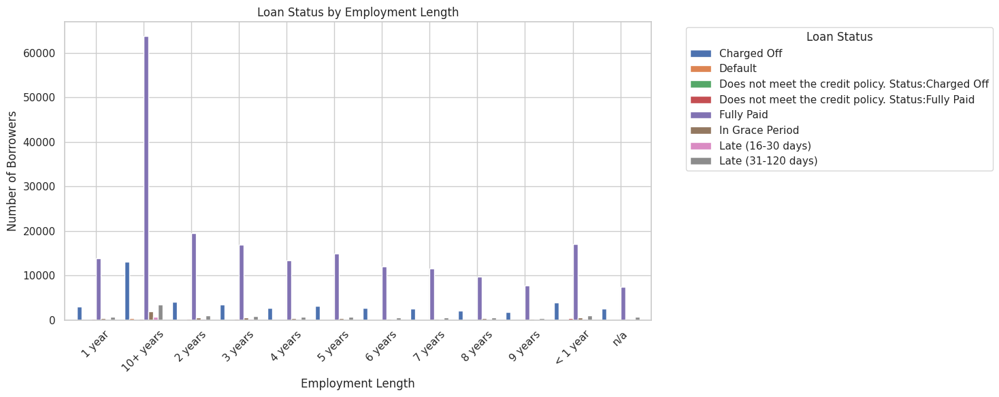

In [359]:
import matplotlib.pyplot as plt
import pandas as pd

# Aggregate counts by emp_length and loan_status
emp_loan_counts = df_clean.groupBy("emp_length", "loan_status").count().orderBy("emp_length").toPandas()

# Pivot the data to have emp_length as index, loan_status as columns
pivot_df = emp_loan_counts.pivot(index="emp_length", columns="loan_status", values="count").fillna(0)

# Plot grouped bar chart
pivot_df.plot(kind='bar', figsize=(15,6), width=0.8)
plt.title("Loan Status by Employment Length")
plt.xlabel("Employment Length")
plt.ylabel("Number of Borrowers")
plt.xticks(rotation=45)
plt.legend(title="Loan Status", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


# Loan Status by Employment Length

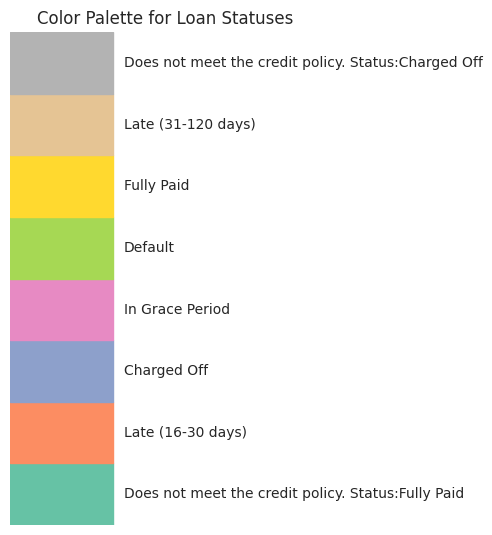

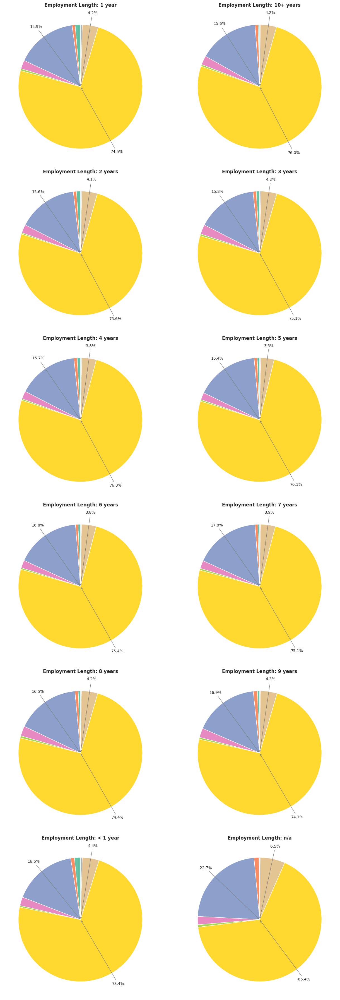

In [360]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Aggregate counts for emp_length × loan_status
emp_loan_counts = df_clean.groupBy("emp_length", "loan_status").count().toPandas()

# Unique loan statuses
loan_statuses = emp_loan_counts["loan_status"].unique()

# Create a nice color palette
palette = sns.color_palette("Set2", n_colors=len(loan_statuses))
color_dict = dict(zip(loan_statuses, palette))

# Display color palette vertically
fig_palette, ax_palette = plt.subplots(figsize=(4, len(loan_statuses)*0.8))
for i, status in enumerate(loan_statuses):
    ax_palette.add_patch(plt.Rectangle((0, i), 1, 1, color=color_dict[status]))
    ax_palette.text(1.1, i + 0.5, status, va='center', fontsize=10)

ax_palette.set_xlim(0, 3)
ax_palette.set_ylim(0, len(loan_statuses))
ax_palette.axis('off')
ax_palette.set_title("Color Palette for Loan Statuses", fontsize=12)
plt.show()


# Pie charts setup (same as before)
emp_lengths = sorted(emp_loan_counts["emp_length"].unique(), key=lambda x: str(x))
n_cols = 2
n_rows = (len(emp_lengths) + 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows*6))
axes = axes.flatten()

for i, emp in enumerate(emp_lengths):
    ax = axes[i]
    emp_df = emp_loan_counts[emp_loan_counts["emp_length"] == emp]

    counts = [emp_df[emp_df["loan_status"] == status]["count"].sum() for status in loan_statuses]
    total = sum(counts)
    if total == 0:
        continue

    wedges, _ = ax.pie(
        counts,
        labels=None,
        startangle=90,
        colors=[color_dict[status] for status in loan_statuses],
        wedgeprops={'edgecolor': 'white'}
    )

    # Top 3 slices with percentages outside
    top_indices = np.argsort(counts)[-3:][::-1]
    for idx in top_indices:
        pct = counts[idx] / total * 100
        wedge = wedges[idx]
        angle = (wedge.theta2 + wedge.theta1) / 2
        x = 1.2 * np.cos(np.deg2rad(angle))
        y = 1.2 * np.sin(np.deg2rad(angle))
        ax.annotate(f"{pct:.1f}%", xy=(0, 0), xytext=(x, y),
                    arrowprops=dict(arrowstyle="->", color="gray"),
                    ha='center', va='center', fontsize=10)

    ax.set_title(f"Employment Length: {emp}", fontsize=12, fontweight='bold')

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


# Loan Amount by Employment Length and Loan Status Analysis

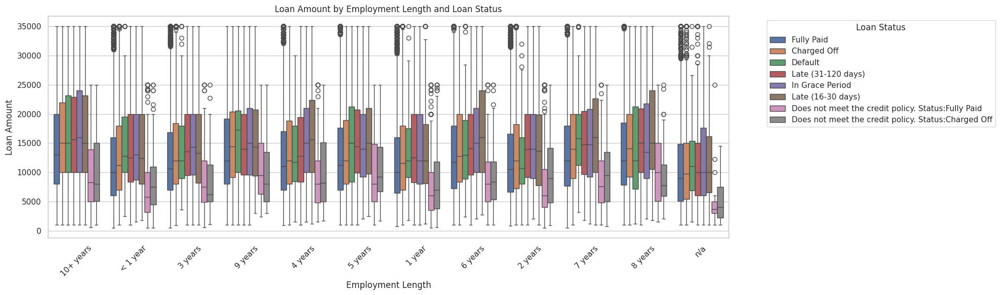

In [361]:
import seaborn as sns
import matplotlib.pyplot as plt

# Convert to Pandas with only relevant columns and drop nulls
emp_loan_df = df_clean.select("emp_length", "loan_amnt", "loan_status").dropna().toPandas()

plt.figure(figsize=(20,6))
sns.boxplot(x="emp_length", y="loan_amnt", hue="loan_status", data=emp_loan_df)
plt.xticks(rotation=45)

plt.title("Loan Amount by Employment Length and Loan Status")
plt.xlabel("Employment Length")
plt.ylabel("Loan Amount")
plt.legend(title="Loan Status", bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()


emp_length × int_rate

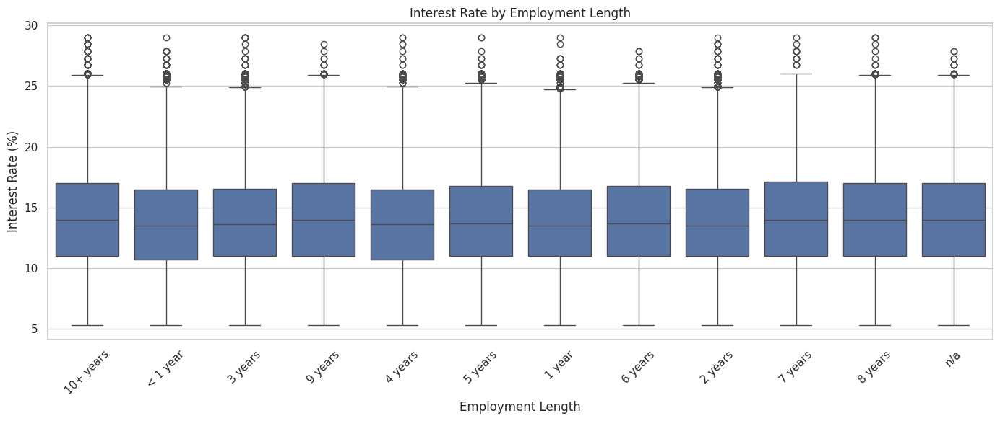

In [362]:
emp_rate_df = df_clean.select("emp_length", "int_rate").dropna().toPandas()

plt.figure(figsize=(14,6))
sns.boxplot(x="emp_length", y="int_rate", data=emp_rate_df)
plt.xticks(rotation=45)
plt.title("Interest Rate by Employment Length")
plt.xlabel("Employment Length")
plt.ylabel("Interest Rate (%)")
plt.tight_layout()
plt.show()



Home Ownership

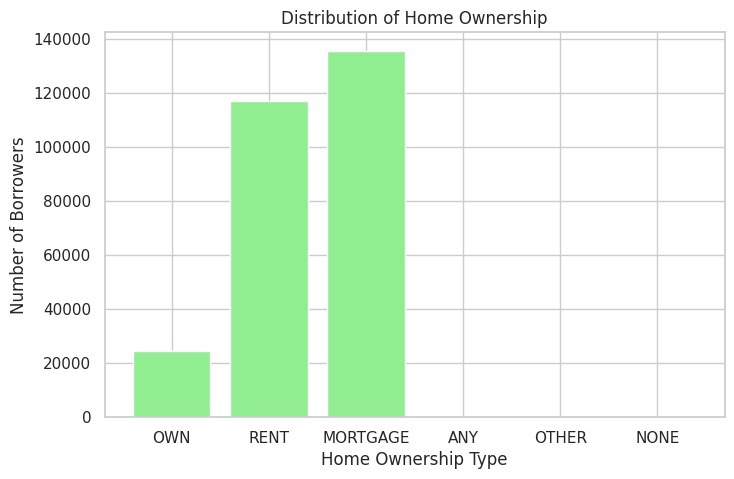

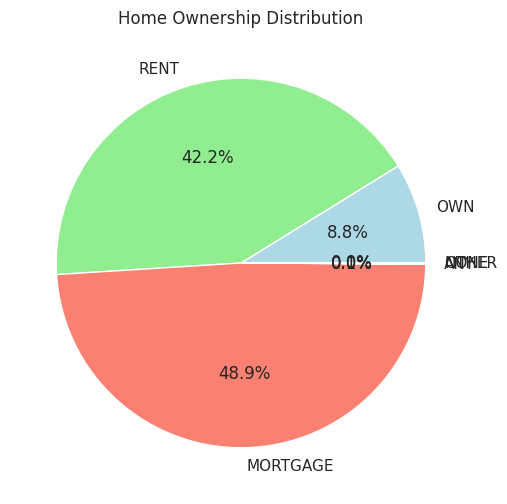

In [363]:
# Count by home ownership
home_counts = df_clean.groupBy("home_ownership").count().toPandas()

# Bar plot
plt.figure(figsize=(8,5))
plt.bar(home_counts['home_ownership'], home_counts['count'], color='lightgreen')
plt.title("Distribution of Home Ownership")
plt.xlabel("Home Ownership Type")
plt.ylabel("Number of Borrowers")
plt.show()

# Pie chart
plt.figure(figsize=(6,6))
plt.pie(home_counts['count'], labels=home_counts['home_ownership'], autopct='%1.1f%%', colors=['lightblue','lightgreen','salmon','gold','violet','grey'])
plt.title("Home Ownership Distribution")
plt.show()


emp_length × home_ownership × loan_status

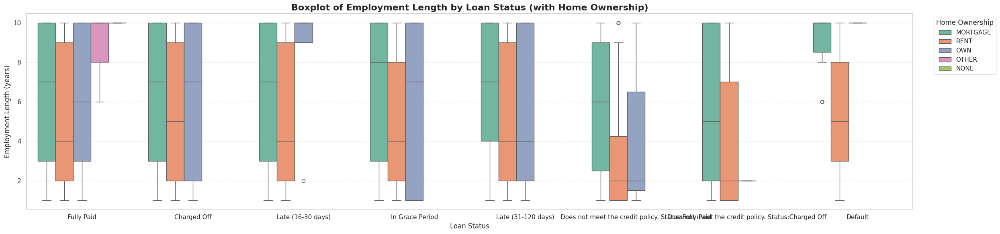

In [364]:
import seaborn as sns
import matplotlib.pyplot as plt

# Sampled dataframe from Spark
df_box = df_clean.sample(False, 0.05, seed=42).toPandas()

# Clean emp_length to numeric if possible
try:
    df_box["emp_length_num"] = df_box["emp_length"].str.extract(r'(\d+)').astype(float)
except:
    df_box["emp_length_num"] = df_box["emp_length"]

plt.figure(figsize=(25,6))
sns.boxplot(
    data=df_box,
    x="loan_status",
    y="emp_length_num",
    hue="home_ownership",
    palette="Set2"
)

plt.title("Boxplot of Employment Length by Loan Status (with Home Ownership)", fontsize=16, fontweight="bold")
plt.xlabel("Loan Status", fontsize=12)
plt.ylabel("Employment Length (years)", fontsize=12)
plt.legend(title="Home Ownership", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In Boxplot it considers all rows in df_clean, including the rare categories like OTHER or NONE. Even if the count is small, they still appear in the plot.

In [365]:
# Check unique values including rare ones and nulls
df_clean.select("home_ownership").distinct().show(10)

# Count missing / rare values
df_clean.groupBy("home_ownership").count().orderBy("count").show()


+--------------+
|home_ownership|
+--------------+
|           OWN|
|          RENT|
|      MORTGAGE|
|           ANY|
|         OTHER|
|          NONE|
+--------------+

+--------------+------+
|home_ownership| count|
+--------------+------+
|           ANY|     1|
|          NONE|    48|
|         OTHER|   179|
|           OWN| 24391|
|          RENT|116948|
|      MORTGAGE|135573|
+--------------+------+



Annual Income

In [366]:
import plotly.express as px
import plotly.graph_objects as go

# Convert to Pandas
annual_inc_pd = df_clean.select("annual_inc").dropna().toPandas()

# Interactive Histogram
fig_hist = px.histogram(
    annual_inc_pd,
    x='annual_inc',
    nbins=100,
    title='Distribution of Annual Income',
    labels={'annual_inc':'Annual Income'},
    color_discrete_sequence=['skyblue']
)
fig_hist.update_layout(
    xaxis=dict(range=[0,500000]),  # zoom into main range
    yaxis_title='Number of Borrowers'
)
fig_hist.show()

# Interactive Box Plot
fig_box = px.box(
    annual_inc_pd,
    x='annual_inc',
    title='Boxplot of Annual Income',
    labels={'annual_inc':'Annual Income'},
    color_discrete_sequence=['orange']
)
fig_box.update_layout(
    xaxis=dict(range=[0,500000])
)
fig_box.show()


Verification Status

verification_status

This column tells how the borrower’s income was verified when applying for the loan.
Verified → Lender verified the borrower’s income (e.g., via pay stubs, tax returns).

Source Verified → Income verified directly from the source (e.g., employer or bank).

Not Verified → Borrower’s income was not verified; based on what they reported.

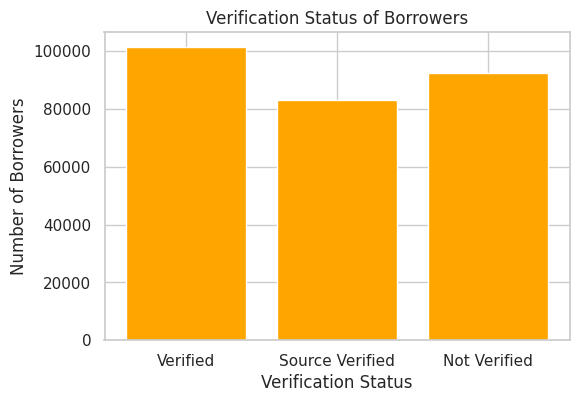

In [367]:
verif_counts = df_clean.groupBy("verification_status").count().toPandas()

plt.figure(figsize=(6,4))
plt.bar(verif_counts['verification_status'], verif_counts['count'], color='orange')
plt.title("Verification Status of Borrowers")
plt.xlabel("Verification Status")
plt.ylabel("Number of Borrowers")
plt.show()


In [368]:
import plotly.express as px

# Filter only verified borrowers
verified_df = df_clean.filter(df_clean.verification_status == "Verified").toPandas()

# Aggregate counts by loan_status
loan_status_counts = verified_df.groupby("loan_status").size().reset_index(name="count")

# Interactive Pie Chart
fig = px.pie(
    loan_status_counts,
    names='loan_status',
    values='count',
    color='loan_status',  # consistent colors
    color_discrete_sequence=px.colors.qualitative.Set2,
    title='Loan Status Distribution — Verified Borrowers',
    hole=0.3  # optional: donut chart style
)

# Show chart
fig.update_traces(
    textposition='outside',
    textinfo='percent+label',
    pull=[0.05 if i==0 else 0 for i in range(len(loan_status_counts))]  # optional: slightly pull first slice
)
fig.show()


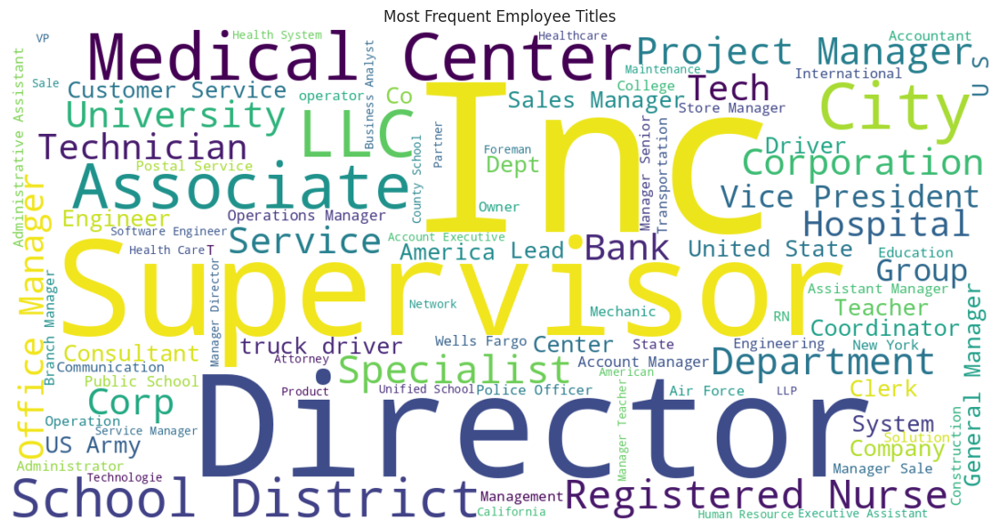

In [369]:
from wordcloud import WordCloud

# Collect employee titles as single string
emp_titles = df_clean.select("emp_title").dropna().rdd.flatMap(lambda x: x).collect()
emp_titles_text = " ".join(emp_titles)

# Generate word cloud
wordcloud = WordCloud(width=1200, height=600, background_color='white', max_words=100).generate(emp_titles_text)

# Plot
plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Employee Titles")
plt.show()


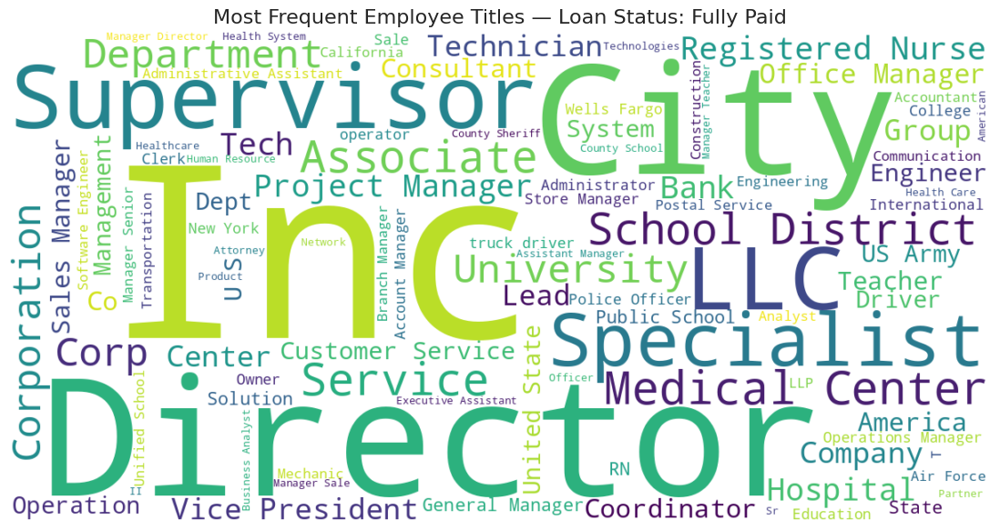

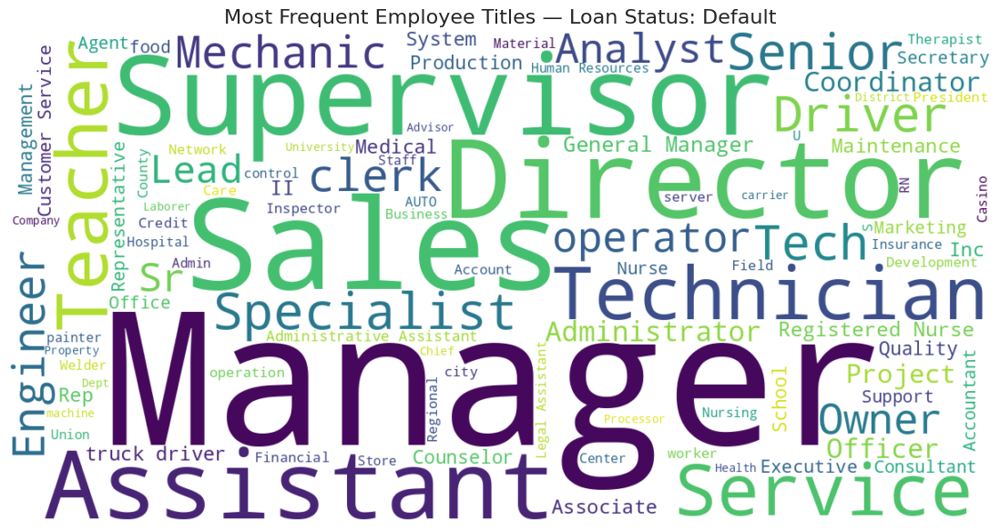

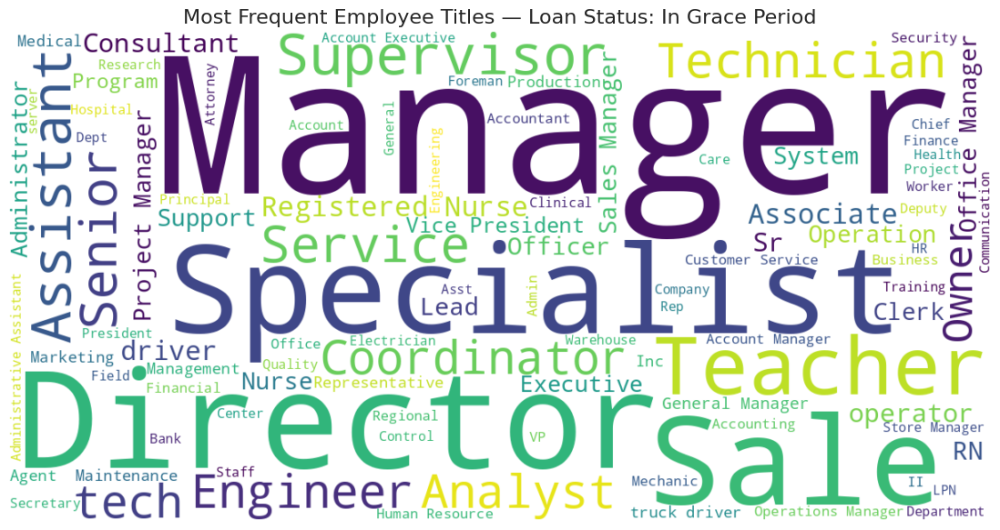

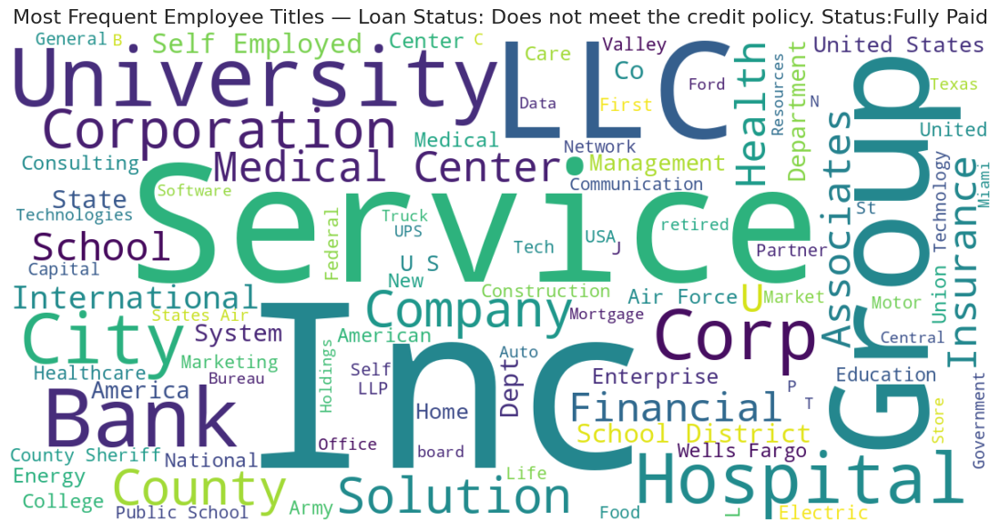

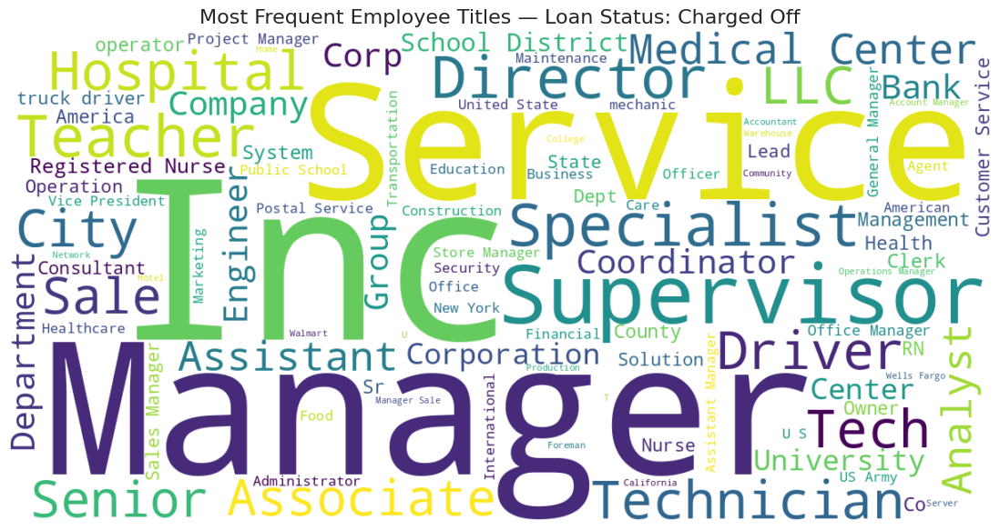

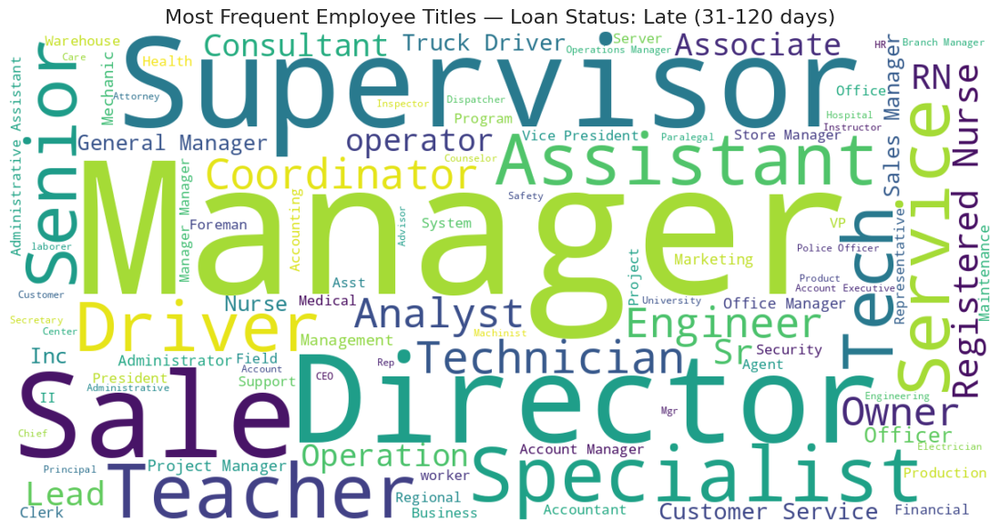

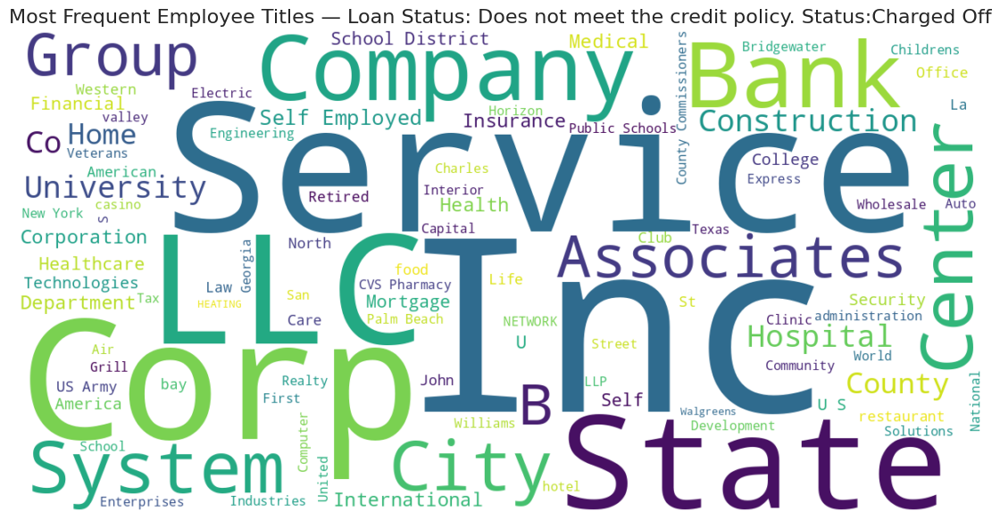

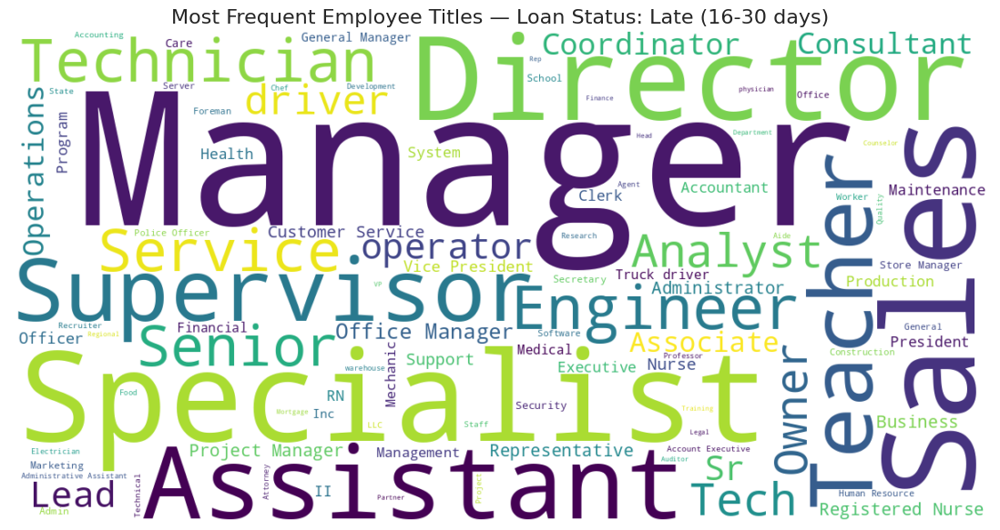

In [370]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Get all unique loan_status values
loan_statuses = [row['loan_status'] for row in df_clean.select("loan_status").distinct().collect()]

for status in loan_statuses:
    # Collect employee titles for this loan_status
    emp_titles = (
        df_clean.filter(df_clean.loan_status == status)
        .select("emp_title")
        .dropna()
        .rdd.flatMap(lambda x: x)
        .collect()
    )

    if not emp_titles:
        continue  # skip if no titles

    emp_titles_text = " ".join(emp_titles)

    # Generate word cloud
    wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color='white',
        max_words=100
    ).generate(emp_titles_text)

    # Plot
    plt.figure(figsize=(15,7))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Most Frequent Employee Titles — Loan Status: {status}", fontsize=16)
    plt.show()


# **Loan Details Analysis**

In [371]:
# ✅ Convert only required columns to Pandas (avoid full df for memory issues)
pdf = df_clean.select(
    "loan_amnt", "funded_amnt", "funded_amnt_inv",
    "term", "int_rate", "installment",
    "grade", "sub_grade", "purpose",
    "initial_list_status", "application_type",
    "loan_status"
).toPandas()

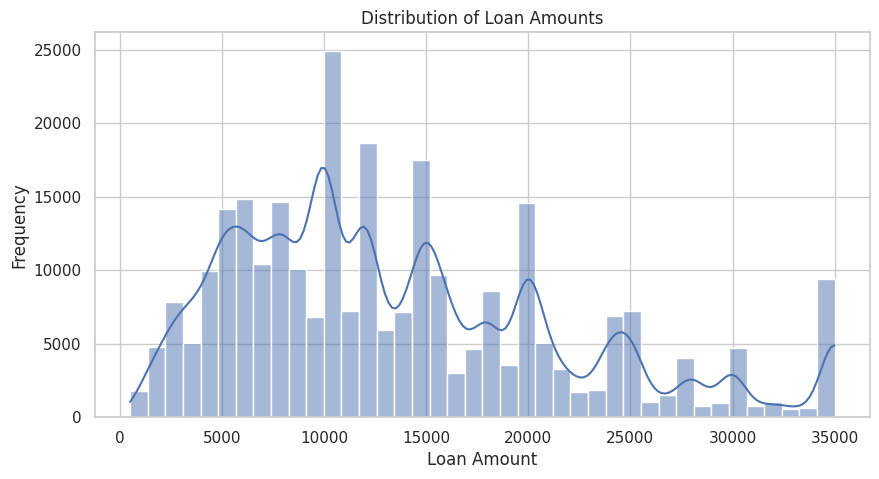

In [372]:
# -------------------------------
# 1. Loan Amount Analysis
# -------------------------------
plt.figure(figsize=(10,5))
sns.histplot(pdf['loan_amnt'], bins=40, kde=True)
plt.title("Distribution of Loan Amounts")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.show()



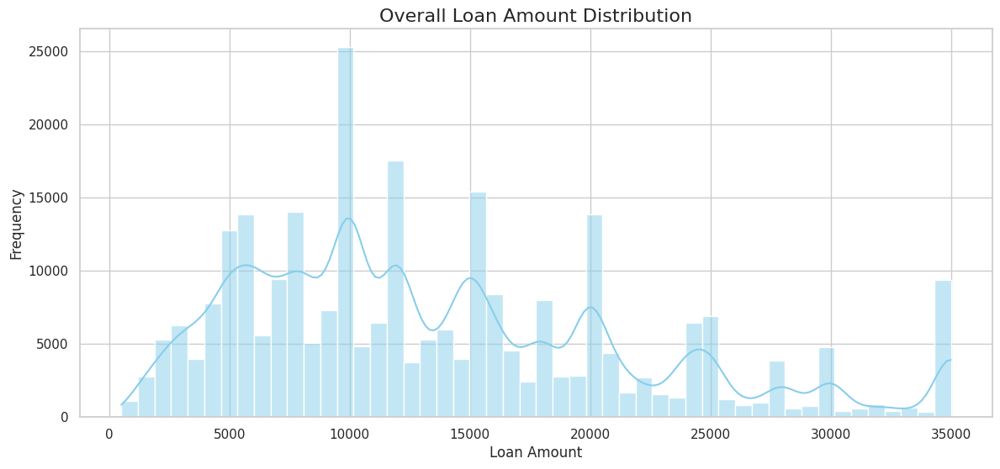

/tmp/ipython-input-2736238114.py:23: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




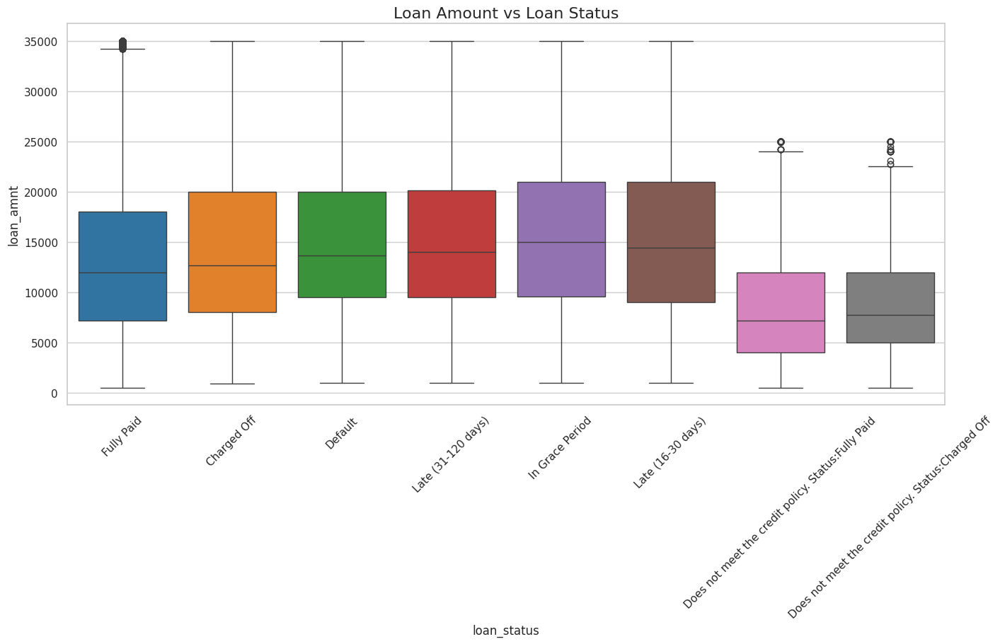

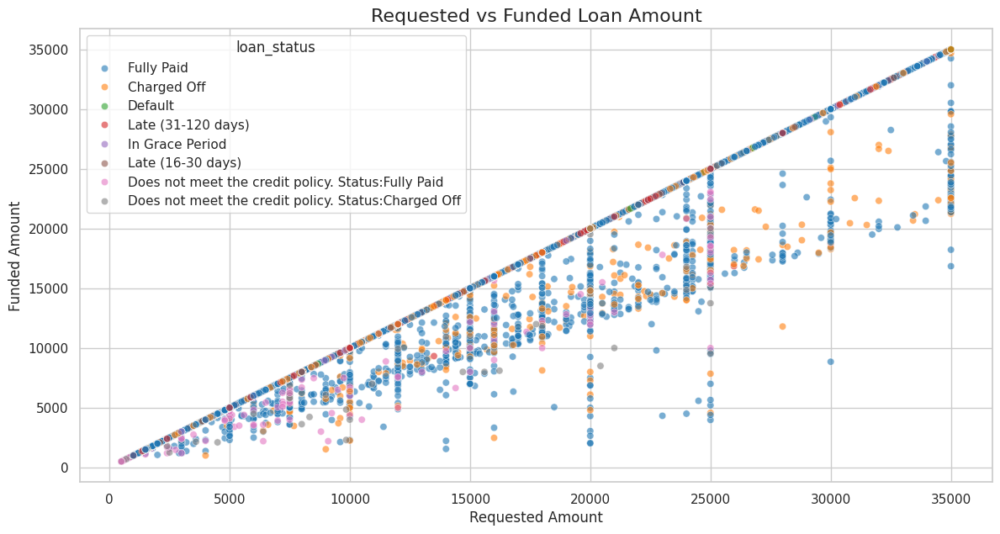

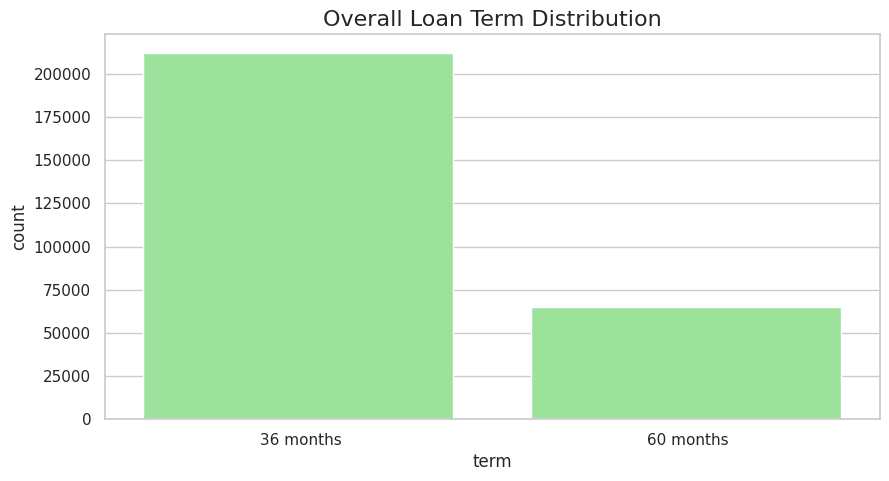

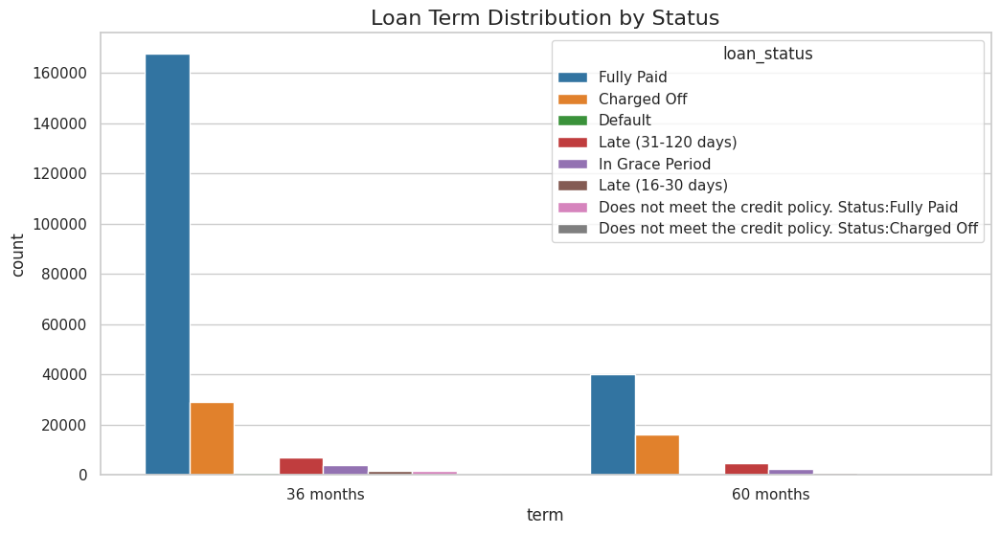

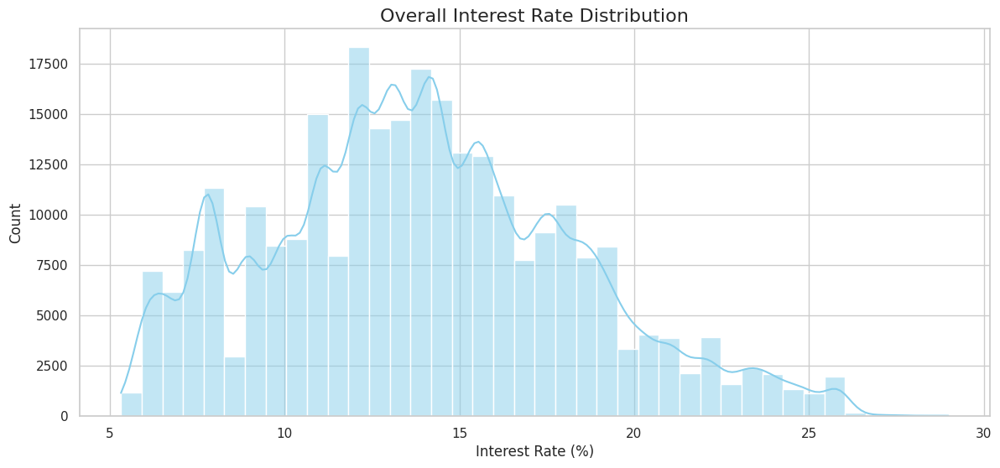

/tmp/ipython-input-2736238114.py:62: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




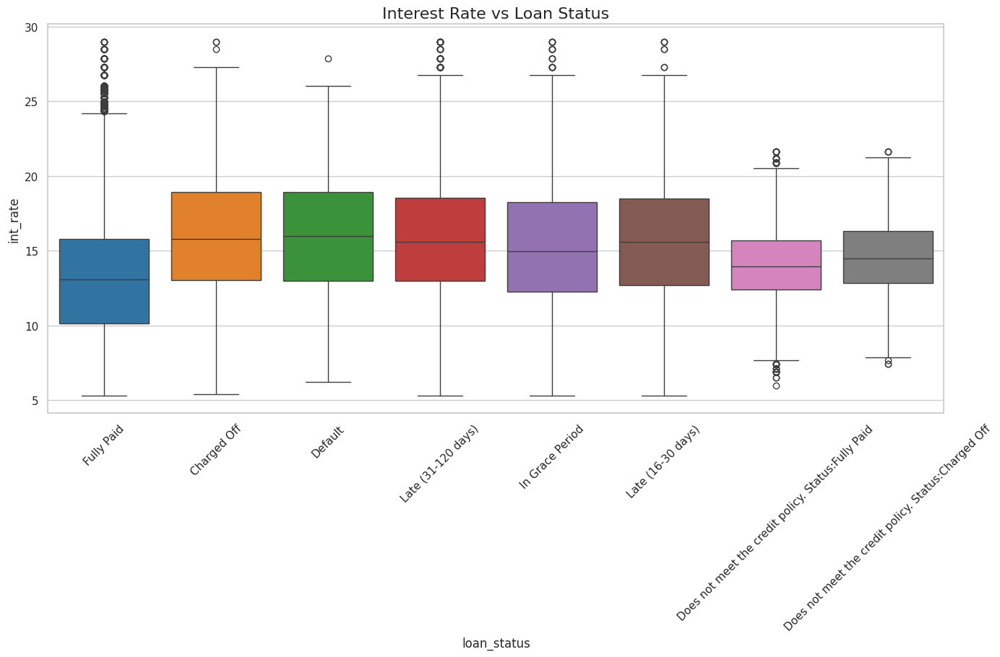

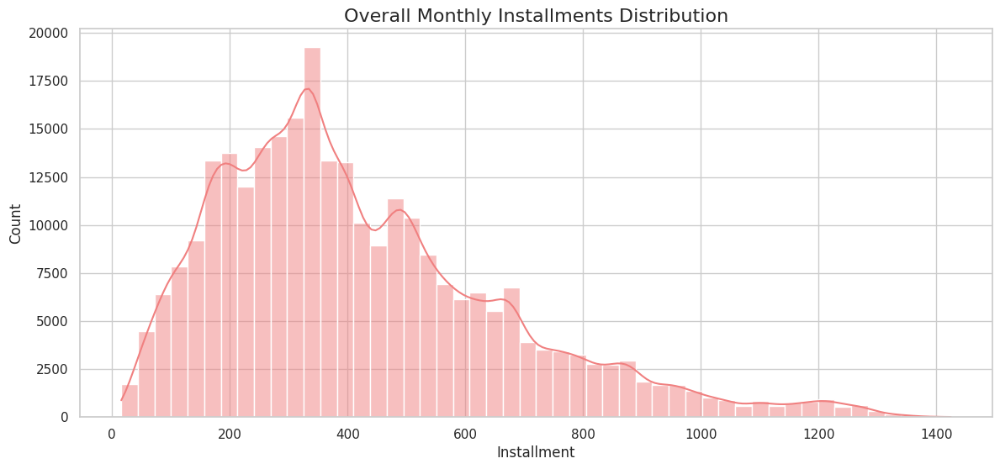

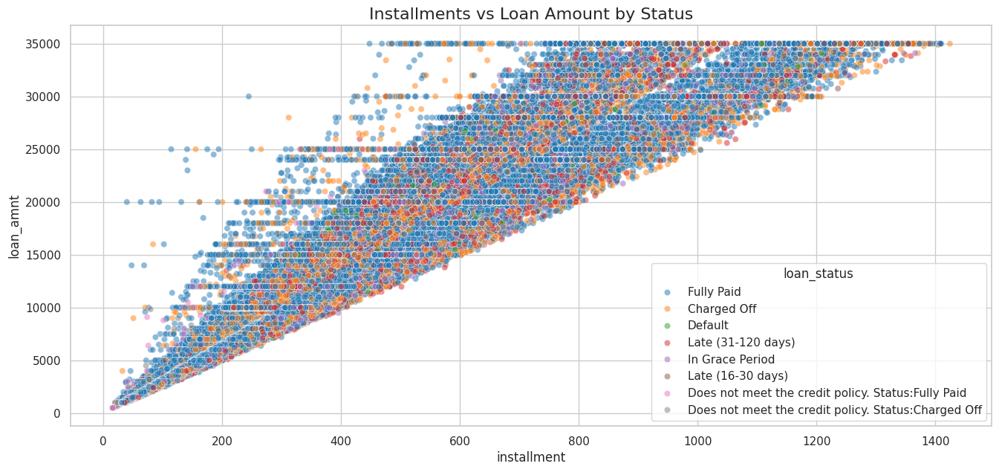

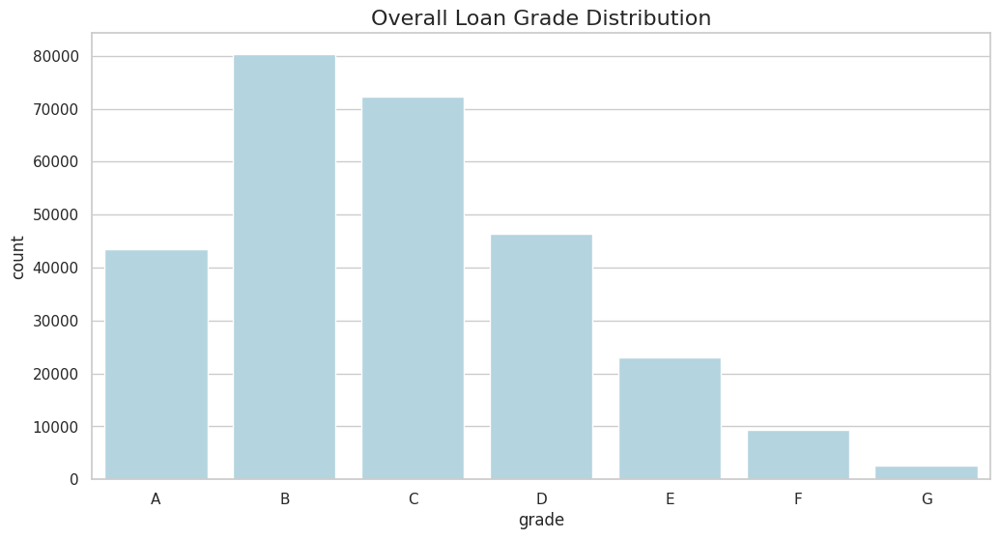

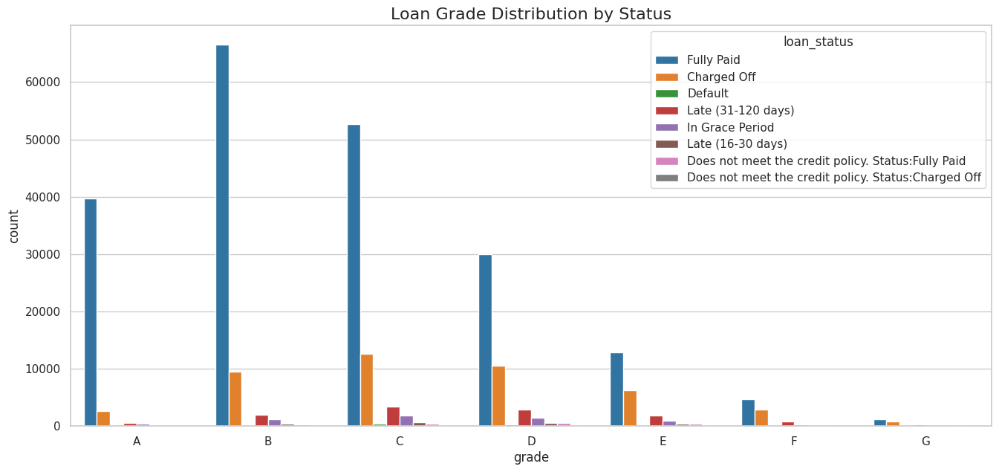

...

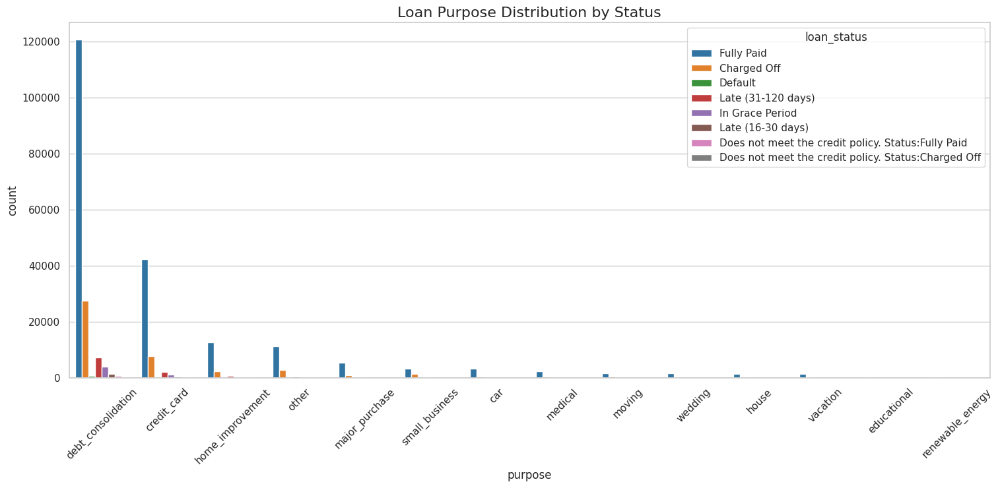

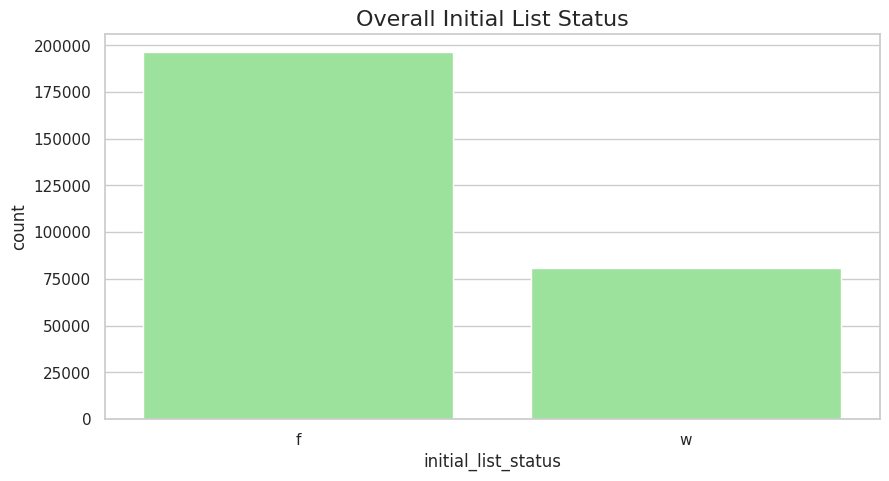

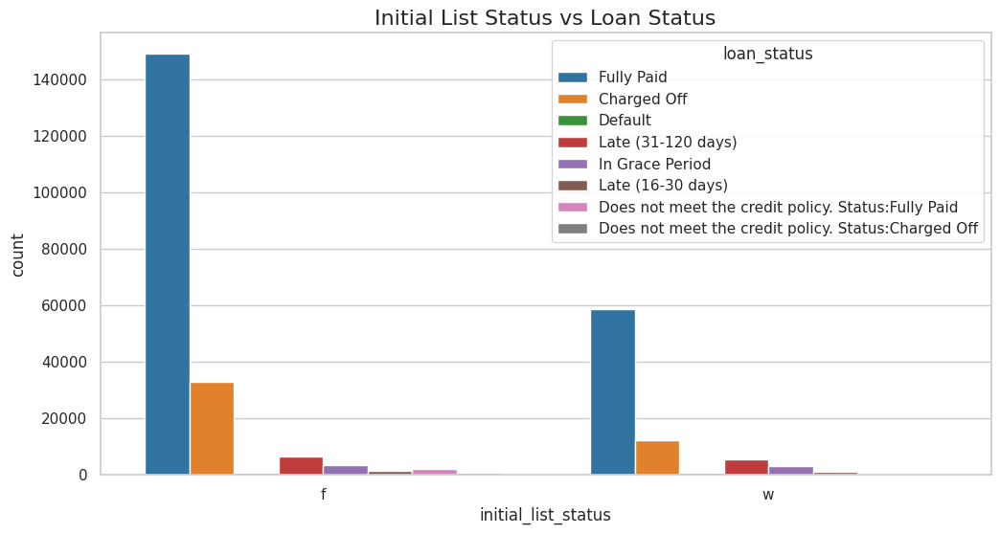

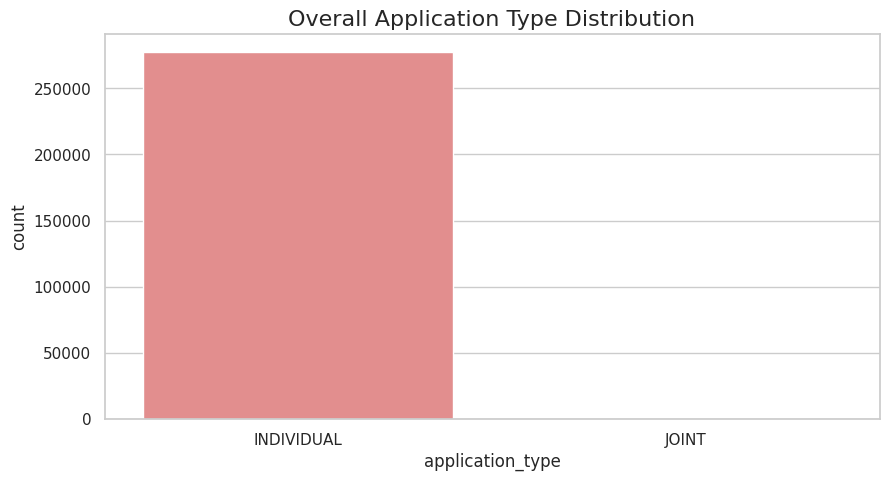

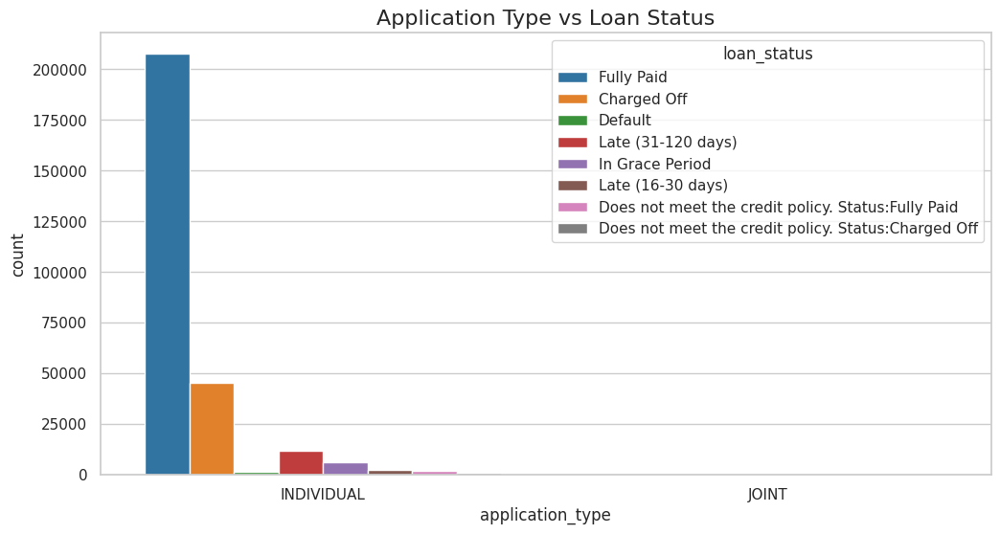

In [377]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# Get unique loan_status values and assign a color palette dynamically
unique_statuses = pdf['loan_status'].unique()
palette_status = sns.color_palette("tab10", len(unique_statuses))
palette_status = dict(zip(unique_statuses, palette_status))

# -------------------------------
# 1️⃣ Loan Amount
# Overall distribution
plt.figure(figsize=(14,6))
sns.histplot(pdf['loan_amnt'], bins=50, kde=True, color='skyblue')
plt.title("Overall Loan Amount Distribution", fontsize=16)
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.show()

# Breakdown by loan status
plt.figure(figsize=(16,7))
sns.boxplot(data=pdf, x='loan_status', y='loan_amnt', palette=palette_status)
plt.title("Loan Amount vs Loan Status", fontsize=16)
plt.xticks(rotation=45)
plt.show()

# -------------------------------
# 2️⃣ Funded Amounts
plt.figure(figsize=(14,7))
sns.scatterplot(data=pdf, x='loan_amnt', y='funded_amnt', hue='loan_status', palette=palette_status, alpha=0.6)
plt.title("Requested vs Funded Loan Amount", fontsize=16)
plt.xlabel("Requested Amount")
plt.ylabel("Funded Amount")
plt.show()

# -------------------------------
# 3️⃣ Loan Term
# Overall
plt.figure(figsize=(10,5))
sns.countplot(data=pdf, x='term', color='lightgreen')
plt.title("Overall Loan Term Distribution", fontsize=16)
plt.show()

# Breakdown by loan status
plt.figure(figsize=(12,6))
sns.countplot(data=pdf, x='term', hue='loan_status', palette=palette_status)
plt.title("Loan Term Distribution by Status", fontsize=16)
plt.show()

# -------------------------------
# 4️⃣ Interest Rate
# Overall
plt.figure(figsize=(14,6))
sns.histplot(pdf['int_rate'], bins=40, kde=True, color='skyblue')
plt.title("Overall Interest Rate Distribution", fontsize=16)
plt.xlabel("Interest Rate (%)")
plt.show()

# Breakdown by loan status
plt.figure(figsize=(16,7))
sns.boxplot(data=pdf, x='loan_status', y='int_rate', palette=palette_status)
plt.title("Interest Rate vs Loan Status", fontsize=16)
plt.xticks(rotation=45)
plt.show()

# -------------------------------
# 5️⃣ Installments
# Overall
plt.figure(figsize=(14,6))
sns.histplot(pdf['installment'], bins=50, kde=True, color='lightcoral')
plt.title("Overall Monthly Installments Distribution", fontsize=16)
plt.xlabel("Installment")
plt.show()

# Breakdown by loan status
plt.figure(figsize=(16,7))
sns.scatterplot(data=pdf, x='installment', y='loan_amnt', hue='loan_status', palette=palette_status, alpha=0.5)
plt.title("Installments vs Loan Amount by Status", fontsize=16)
plt.show()

# -------------------------------
# 6️⃣ Loan Grade / Sub-Grade
# Grade
plt.figure(figsize=(12,6))
sns.countplot(data=pdf, x='grade', order=sorted(pdf['grade'].unique()), color='lightblue')
plt.title("Overall Loan Grade Distribution", fontsize=16)
plt.show()

plt.figure(figsize=(16,7))
sns.countplot(data=pdf, x='grade', order=sorted(pdf['grade'].unique()), hue='loan_status', palette=palette_status)
plt.title("Loan Grade Distribution by Status", fontsize=16)
plt.show()

# Sub-Grade
plt.figure(figsize=(18,7))
sns.countplot(data=pdf, x='sub_grade', order=sorted(pdf['sub_grade'].unique()), color='lightgreen')
plt.title("Overall Loan Sub-Grade Distribution", fontsize=16)
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(20,7))
sns.countplot(data=pdf, x='sub_grade', order=sorted(pdf['sub_grade'].unique()), hue='loan_status', palette=palette_status)
plt.title("Loan Sub-Grade Distribution by Status", fontsize=16)
plt.xticks(rotation=45)
plt.show()

# -------------------------------
# 7️⃣ Loan Purpose
# Overall
plt.figure(figsize=(16,6))
sns.countplot(data=pdf, x='purpose', order=pdf['purpose'].value_counts().index, color='lightblue')
plt.title("Overall Loan Purpose Distribution", fontsize=16)
plt.xticks(rotation=45)
plt.show()

# Breakdown by loan status
plt.figure(figsize=(18,7))
sns.countplot(data=pdf, x='purpose', order=pdf['purpose'].value_counts().index, hue='loan_status', palette=palette_status)
plt.title("Loan Purpose Distribution by Status", fontsize=16)
plt.xticks(rotation=45)
plt.show()

# -------------------------------
# 8️⃣ Initial List Status
# Overall
plt.figure(figsize=(10,5))
sns.countplot(data=pdf, x='initial_list_status', color='lightgreen')
plt.title("Overall Initial List Status", fontsize=16)
plt.show()

# Breakdown
plt.figure(figsize=(12,6))
sns.countplot(data=pdf, x='initial_list_status', hue='loan_status', palette=palette_status)
plt.title("Initial List Status vs Loan Status", fontsize=16)
plt.show()

# -------------------------------
# 9️⃣ Application Type
# Overall
plt.figure(figsize=(10,5))
sns.countplot(data=pdf, x='application_type', color='lightcoral')
plt.title("Overall Application Type Distribution", fontsize=16)
plt.show()

# Breakdown
plt.figure(figsize=(12,6))
sns.countplot(data=pdf, x='application_type', hue='loan_status', palette=palette_status)
plt.title("Application Type vs Loan Status", fontsize=16)
plt.show()


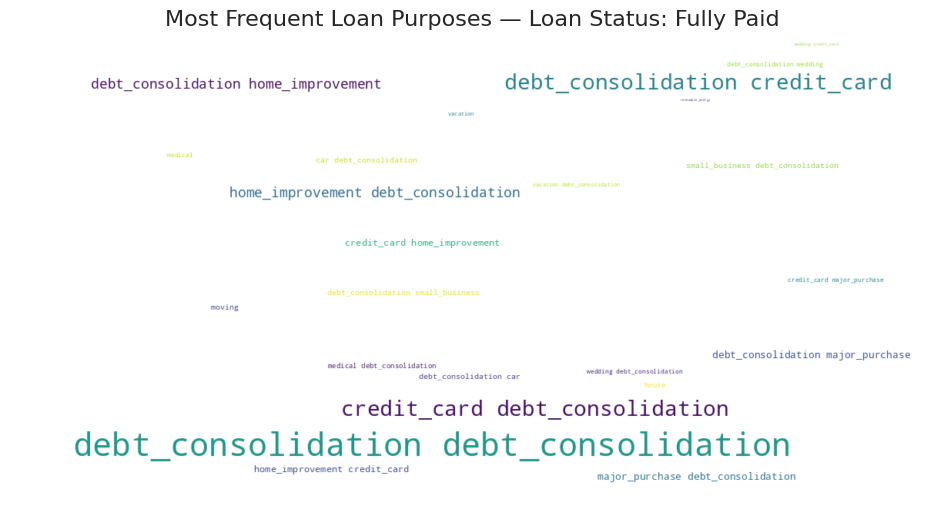

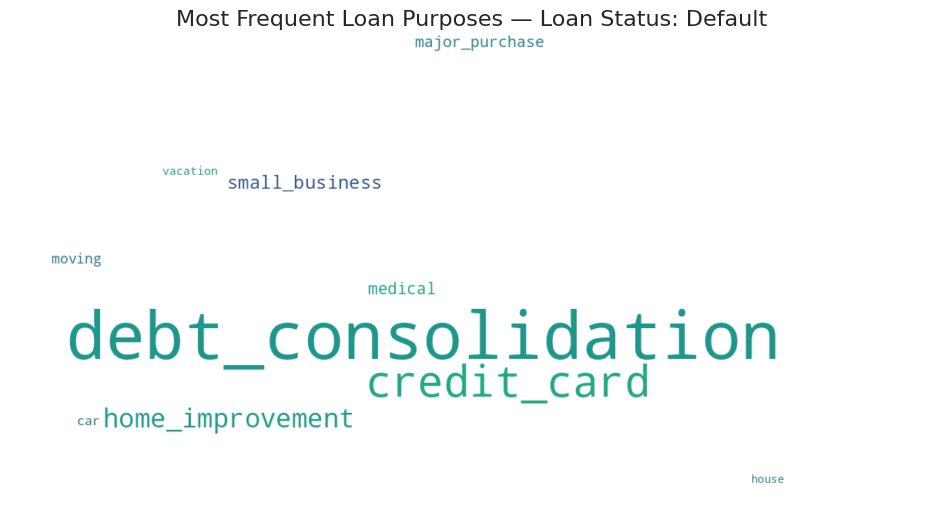

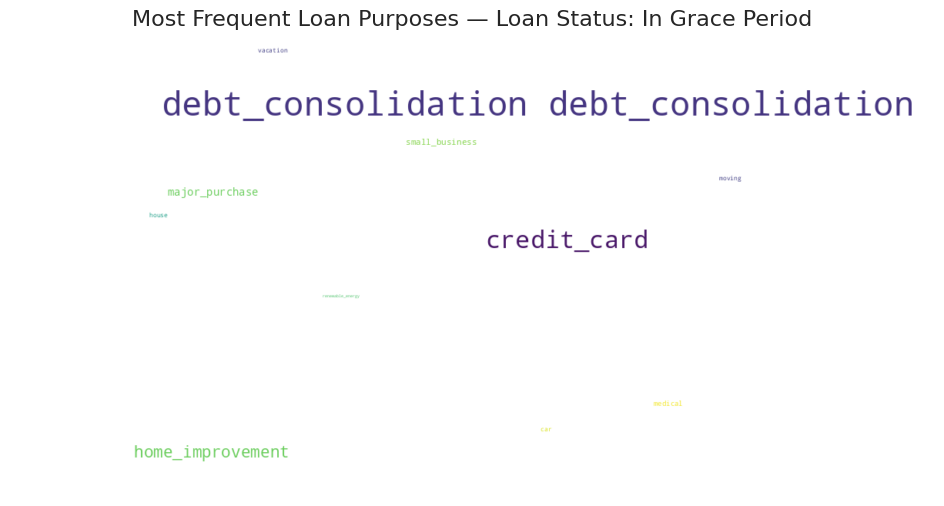

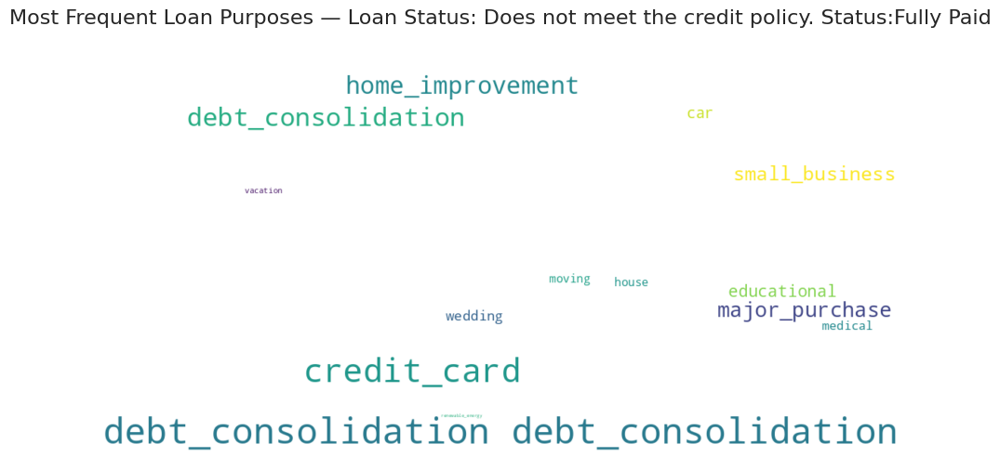

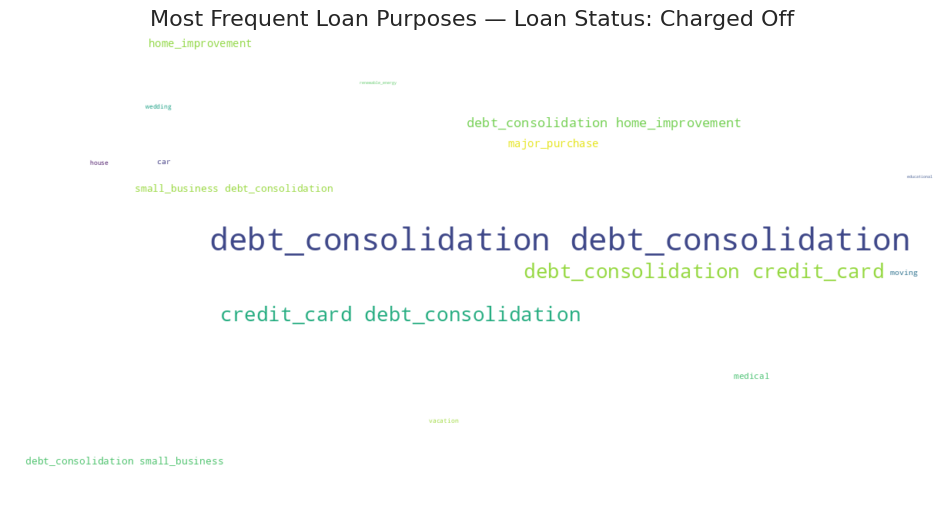

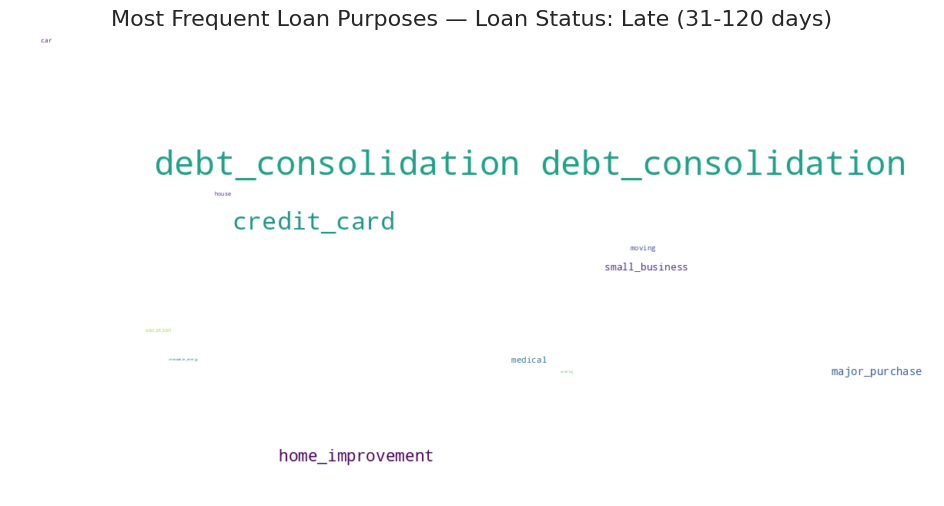

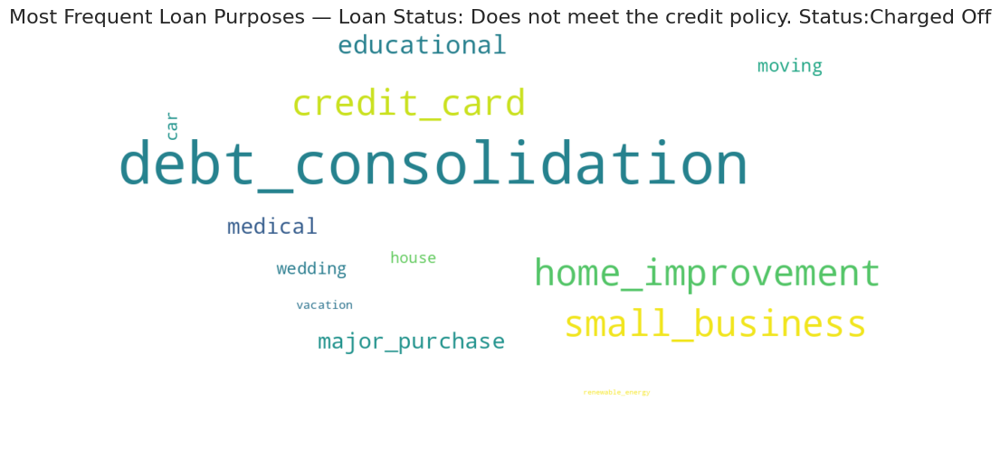

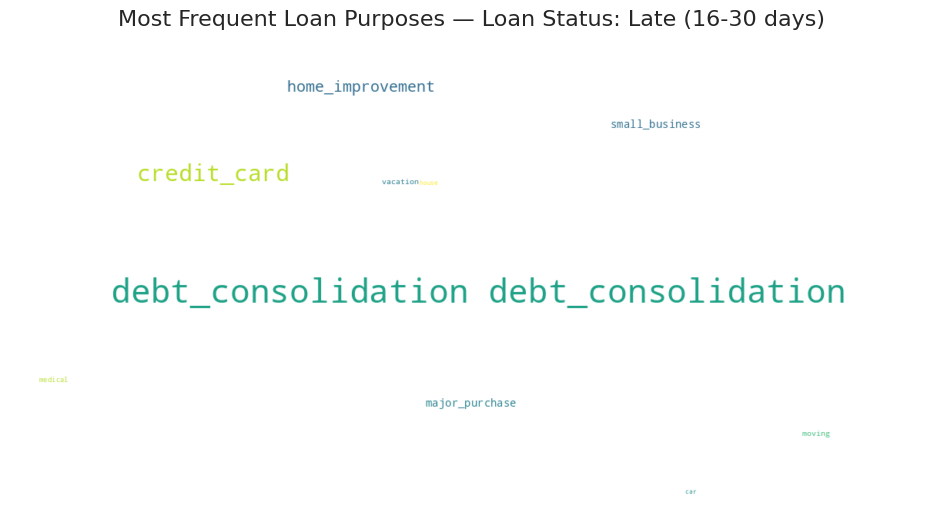

In [378]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Get all unique loan_status values
loan_statuses = [row['loan_status'] for row in df_clean.select("loan_status").distinct().collect()]

for status in loan_statuses:
    # Collect purposes for this loan_status
    purposes = (
        df_clean.filter(df_clean.loan_status == status)
        .select("purpose")
        .dropna()
        .rdd.flatMap(lambda x: x)
        .collect()
    )

    if not purposes:
        continue  # skip if no purposes

    purposes_text = " ".join(purposes)

    # Generate word cloud
    wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color='white',
        max_words=50
    ).generate(purposes_text)

    # Plot
    plt.figure(figsize=(12,6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Most Frequent Loan Purposes — Loan Status: {status}", fontsize=16)
    plt.show()


Correlation Heatmap

For numerical loan variables:

In [379]:
# Selected loan-related columns
loan_cols = [
    "loan_amnt", "funded_amnt", "funded_amnt_inv",
    "int_rate", "installment", "annual_inc", "dti"
]


# Keep only the columns that exist in df_clean
available_cols = [c for c in loan_cols if c in df_clean.columns]

# Convert to Pandas for correlation calculation
loan_df = df_clean.select(available_cols).toPandas()


In [380]:
# Check data types
for col in available_cols:
    dtype = loan_df[col].dtype
    col_type = "numeric" if np.issubdtype(dtype, np.number) else "string"
    print(f"{col}: {col_type} ({dtype})")

loan_amnt: numeric (float64)
funded_amnt: numeric (float64)
funded_amnt_inv: numeric (float64)
int_rate: numeric (float64)
installment: numeric (float64)
annual_inc: numeric (float64)
dti: numeric (float64)


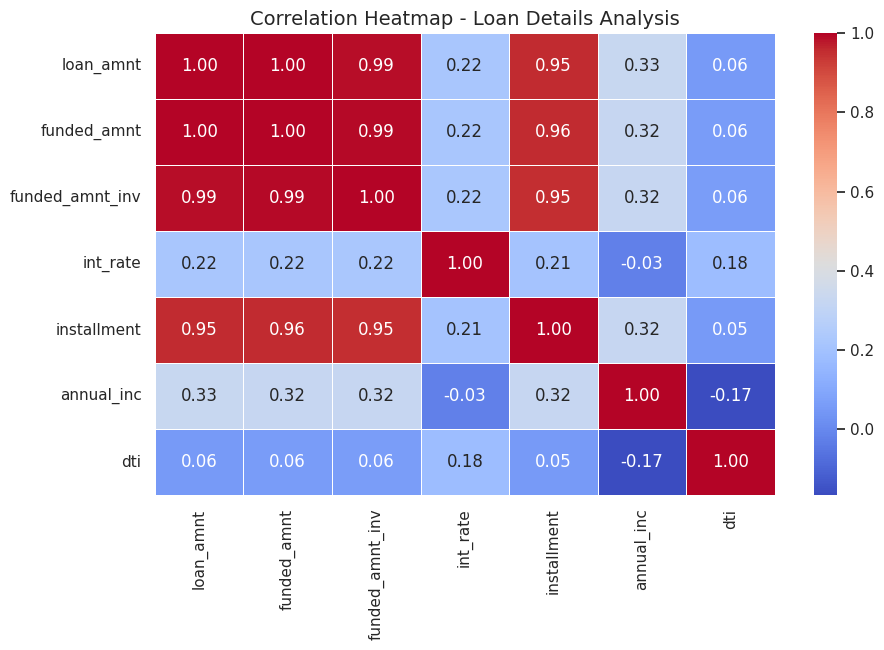

In [381]:



# Compute correlation matrix
corr_matrix = loan_df.corr()

# Plot heatmap
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap - Loan Details Analysis", fontsize=14)
plt.show()

Boxplot of Interest Rate vs Loan Grade

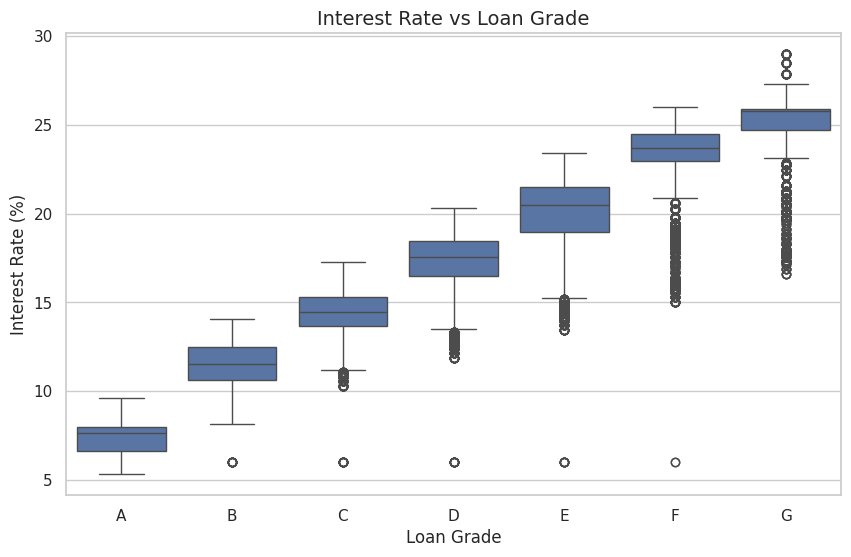

In [382]:
# Convert needed cols to Pandas
df_pd = df_clean.select("int_rate", "grade").toPandas()

plt.figure(figsize=(10,6))
sns.boxplot(x="grade", y="int_rate", data=df_pd, order=sorted(df_pd["grade"].unique()))
plt.title("Interest Rate vs Loan Grade", fontsize=14)
plt.xlabel("Loan Grade")
plt.ylabel("Interest Rate (%)")
plt.show()

Loan Amount vs Default (Boxplot)

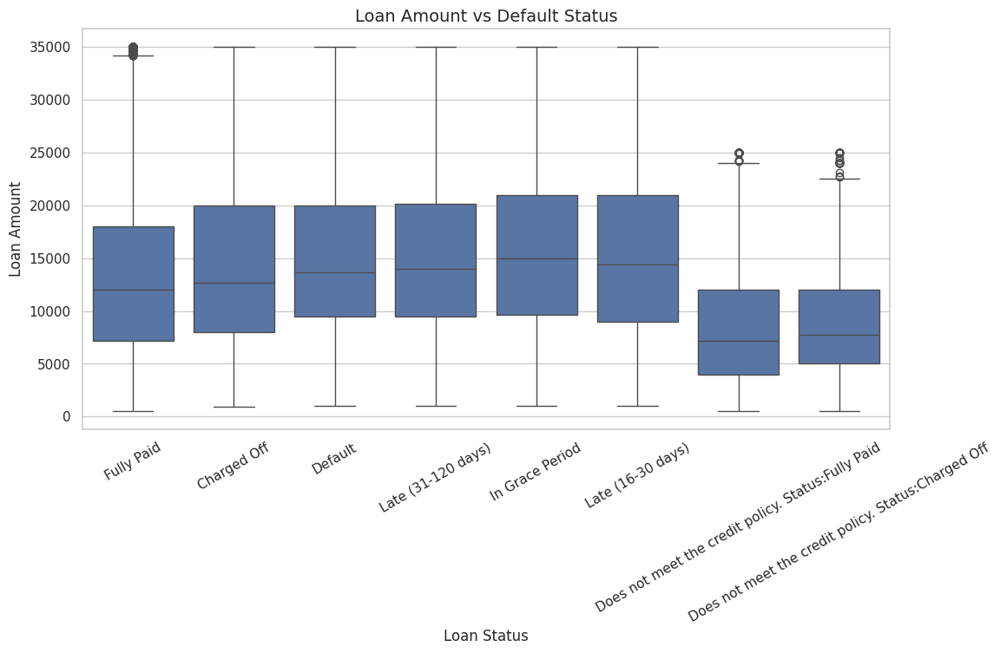

In [383]:
# Keep only loan_amnt + status
df_pd = df_clean.select("loan_amnt", "loan_status").toPandas()

plt.figure(figsize=(12,6))
sns.boxplot(x="loan_status", y="loan_amnt", data=df_pd)
plt.title("Loan Amount vs Default Status", fontsize=14)
plt.xlabel("Loan Status")
plt.ylabel("Loan Amount")
plt.xticks(rotation=30)
plt.show()

Loan Purpose vs Default Rate

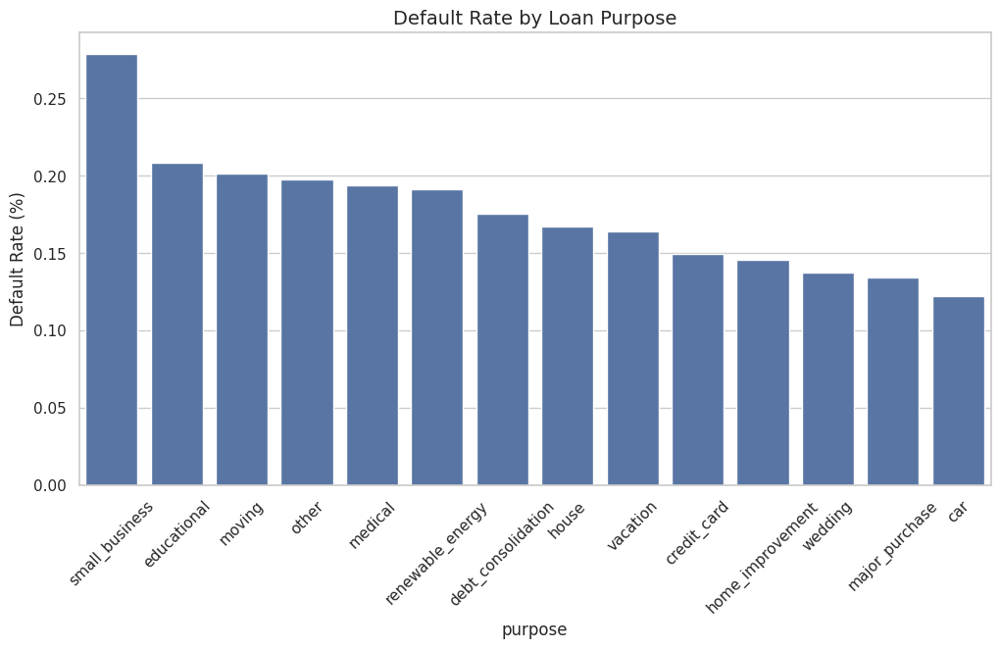

In [384]:
# Convert to Pandas
df_pd = df_clean.select("purpose", "loan_status").toPandas()

# Create binary default flag
df_pd["default_flag"] = df_pd["loan_status"].apply(lambda x: 1 if "Charged Off" in x or "Default" in x else 0)

# Group by purpose
purpose_default = df_pd.groupby("purpose")["default_flag"].mean().sort_values(ascending=False)

# Plot
plt.figure(figsize=(12,6))
sns.barplot(x=purpose_default.index, y=purpose_default.values)
plt.title("Default Rate by Loan Purpose", fontsize=14)
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.show()



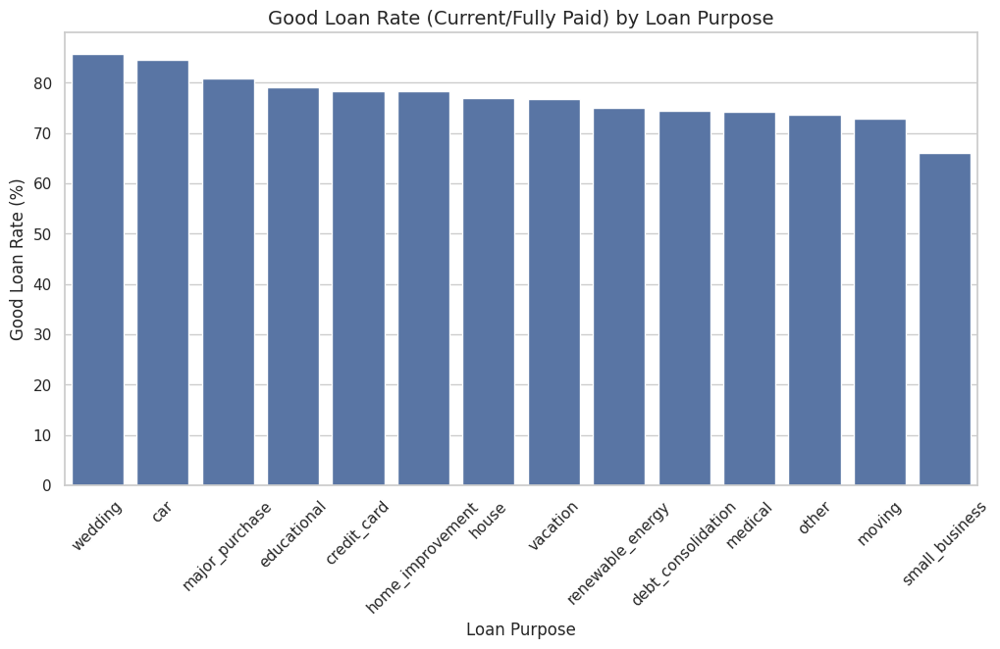

In [385]:
# Convert to Pandas with only relevant columns
df_pd = df_clean.select("purpose", "loan_status").toPandas()

# Create a binary flag for "good loans" (Current or Fully Paid)
df_pd["good_flag"] = df_pd["loan_status"].apply(
    lambda x: 1 if ("Current" in x or "Fully Paid" in x) else 0
)

# Group by loan purpose and calculate the mean good loan rate
purpose_good = df_pd.groupby("purpose")["good_flag"].mean().sort_values(ascending=False)

# Plot
plt.figure(figsize=(12,6))
sns.barplot(x=purpose_good.index, y=purpose_good.values * 100)  # convert to %
plt.title("Good Loan Rate (Current/Fully Paid) by Loan Purpose", fontsize=14)
plt.ylabel("Good Loan Rate (%)")
plt.xlabel("Loan Purpose")
plt.xticks(rotation=45)
plt.show()


Term vs Default

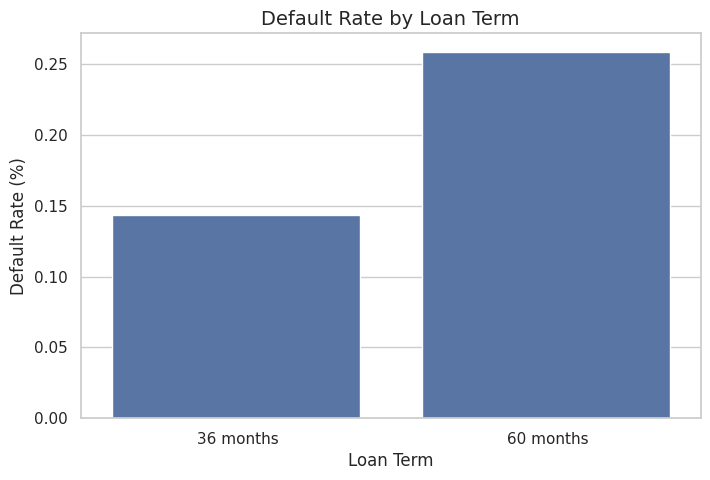

In [386]:
# Convert to Pandas
df_pd = df_clean.select("term", "loan_status").toPandas()

# Default flag
df_pd["default_flag"] = df_pd["loan_status"].apply(lambda x: 1 if "Charged Off" in x or "Default" in x else 0)

# Group by term
term_default = df_pd.groupby("term")["default_flag"].mean()

# Plot
plt.figure(figsize=(8,5))
sns.barplot(x=term_default.index, y=term_default.values)
plt.title("Default Rate by Loan Term", fontsize=14)
plt.ylabel("Default Rate (%)")
plt.xlabel("Loan Term")
plt.show()


36-month loans have a default rate of approximately 5%

60-month loans have a higher default rate of approximately 6%

Longer-term loans (60 months) have a 20% higher default rate than shorter-term loans (36 months)

# **Loan Performance / Repayment Analysis**

In [387]:
# ✅ Convert PySpark DataFrame to Pandas for visualization
df_pd = df_clean.select(
    "loan_status",
    "pymnt_plan",
    "collections_12_mths_ex_med",
    "acc_now_delinq",
    "delinq_2yrs",
    "mths_since_last_delinq",
    "pub_rec"
).toPandas()

# ✅ Create binary repayment flag (1 = default/charged off/late, 0 = fully paid)
df_pd["default_flag"] = df_pd["loan_status"].apply(
    lambda x: 1 if "Charged Off" in x or "Default" in x or "Late" in x else 0
)


In [388]:
# Check value counts in the Spark DataFrame
print("Spark DataFrame - Loan Status Counts:")
df_spark.groupBy("loan_status").count().orderBy(F.desc("count")).show(truncate=False)

# Check value counts in the Pandas DataFrame
print("\nPandas DataFrame - Loan Status Counts:")
print(df_pd["loan_status"].value_counts())

Spark DataFrame - Loan Status Counts:
+---------------------------------------------------+------+
|loan_status                                        |count |
+---------------------------------------------------+------+
|Fully Paid                                         |207723|
|Charged Off                                        |45248 |
|Late (31-120 days)                                 |11591 |
|In Grace Period                                    |6253  |
|Late (16-30 days)                                  |2357  |
|Does not meet the credit policy. Status:Fully Paid |1988  |
|Default                                            |1219  |
|Does not meet the credit policy. Status:Charged Off|761   |
+---------------------------------------------------+------+


Pandas DataFrame - Loan Status Counts:
loan_status
Fully Paid                                             207723
Charged Off                                             45248
Late (31-120 days)                                   

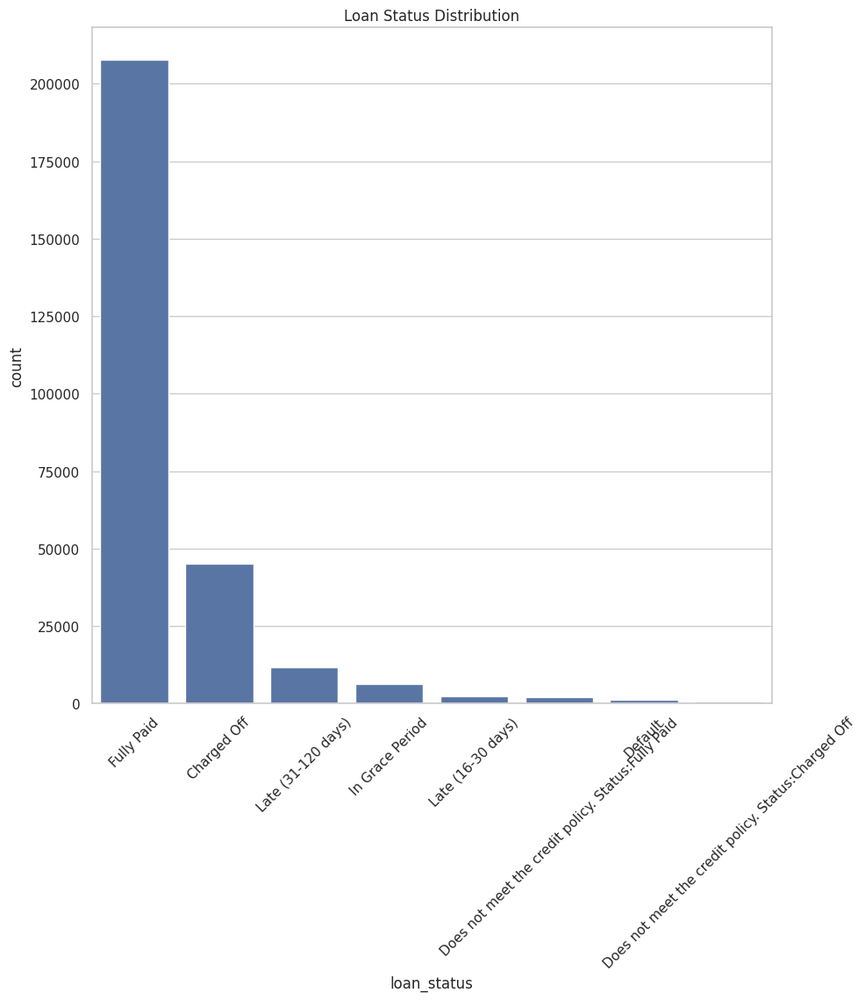

In [389]:

# 1️⃣ Loan Status Distribution (Fully Paid vs Default vs Late)
plt.figure(figsize=(10,10))
sns.countplot(x="loan_status", data=df_pd, order=df_pd["loan_status"].value_counts().index)
plt.title("Loan Status Distribution")
plt.xticks(rotation=45)
plt.show()
# 🔹 Insight: Shows repayment outcome proportions (Fully Paid vs Default vs Late).
# 🔹 You can group statuses if needed into 3 main categories.

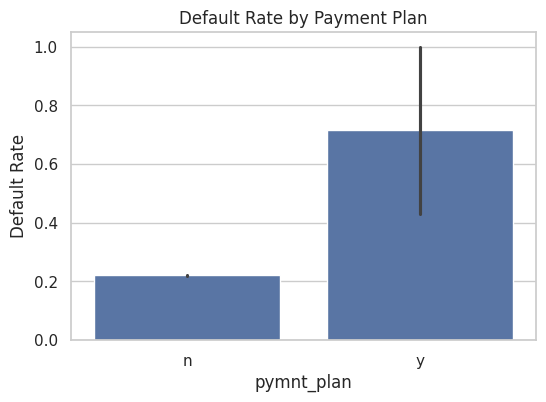

In [390]:
# 2️⃣ Payment Plan Impact (y/n)
plt.figure(figsize=(6,4))
sns.barplot(x="pymnt_plan", y="default_flag", data=df_pd)
plt.title("Default Rate by Payment Plan")
plt.ylabel("Default Rate")
plt.show()
# 🔹 Insight: Compares how often loans with a payment plan go into default.

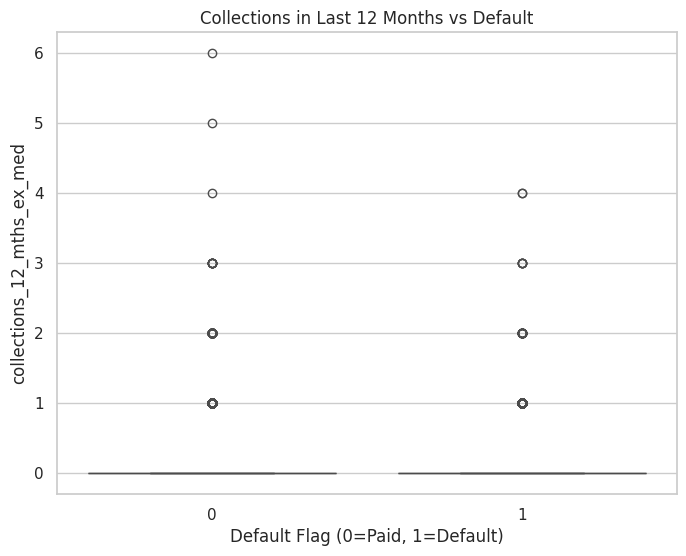

In [391]:
# 3️⃣ Collections in Last 12 Months
plt.figure(figsize=(8,6))
sns.boxplot(x="default_flag", y="collections_12_mths_ex_med", data=df_pd)
plt.title("Collections in Last 12 Months vs Default")
plt.xlabel("Default Flag (0=Paid, 1=Default)")
plt.show()
# 🔹 Insight: Higher collections = more chance of default.

The statement "borrowers who defaulted... have significantly more collections" is based on comparing the median (the typical case) of each group.

Group Default = 1 (Defaulted): The entire box is positioned higher on the y-axis. This means the typical borrower who defaulted had a higher number of collections.

Group Default = 0 (Paid): The entire box is positioned lower on the y-axis. This means the typical borrower who paid their loan had a lower number of collections.

Clear Pattern: Borrowers who defaulted on their loans (default_flag = 1) have significantly more collections in the past 12 months compared to those who paid their loans (default_flag = 0).

Risk Indicator: The number of collections in the past year appears to be a strong predictor of future default risk.

The analysis proves a simple rule: "If a borrower has recent collections, they are much more likely to default on a new loan."

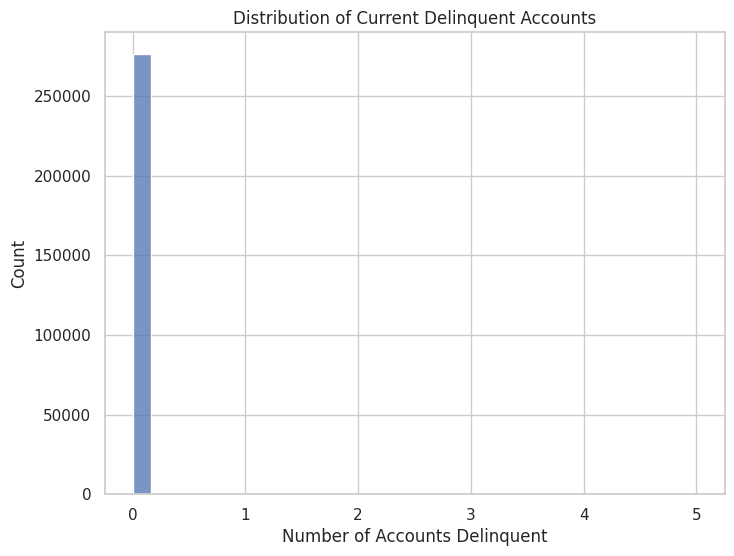

In [392]:

# 4️⃣ Accounts Currently Delinquent
plt.figure(figsize=(8,6))
sns.histplot(df_pd["acc_now_delinq"], bins=30, kde=False)
plt.title("Distribution of Current Delinquent Accounts")
plt.xlabel("Number of Accounts Delinquent")
plt.show()
# 🔹 Insight: Most borrowers have zero delinquent accounts,
# but loans with delinquencies correlate strongly with risk.



The massive bar at 0 shows that most borrowers (∼800,000) have ZERO currently delinquent accounts

This represents the lowest-risk segment of borrowers

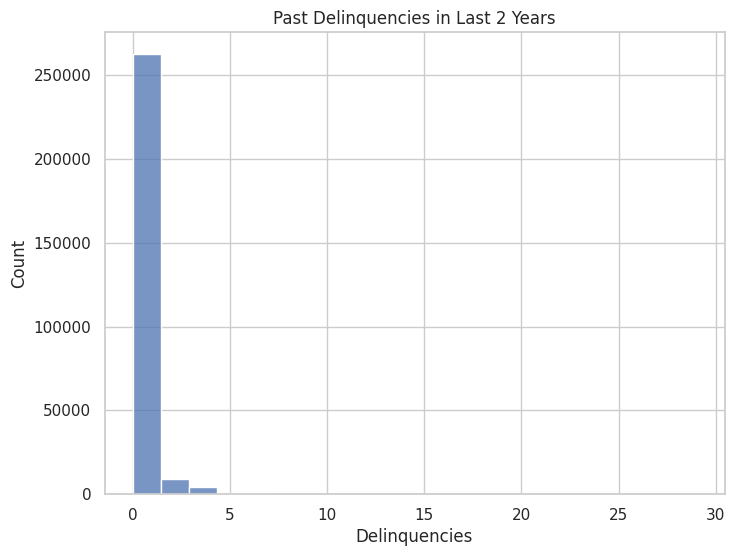

In [393]:

# 5️⃣ Past Delinquencies (Last 2 Years)
plt.figure(figsize=(8,6))
sns.histplot(df_pd["delinq_2yrs"], bins=20, kde=False)
plt.title("Past Delinquencies in Last 2 Years")
plt.xlabel("Delinquencies")
plt.show()
# 🔹 Insight: Helps see how many borrowers had trouble repaying before.



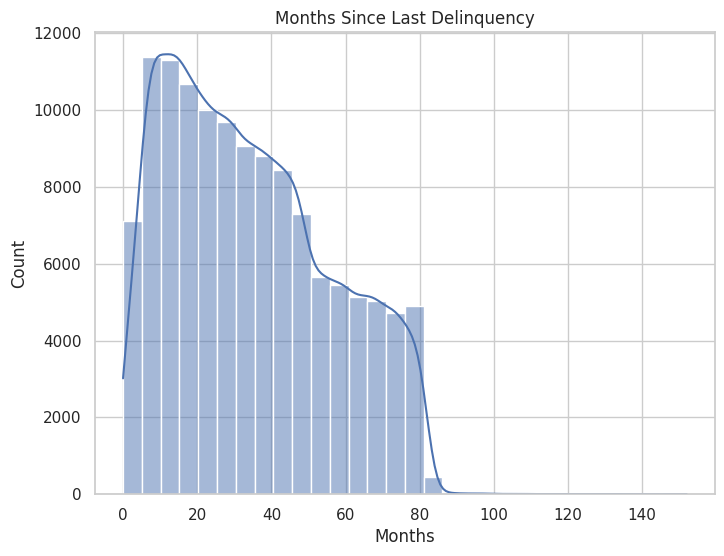

In [394]:
# 6️⃣ Months Since Last Delinquency
plt.figure(figsize=(8,6))
sns.histplot(df_pd["mths_since_last_delinq"], bins=30, kde=True)
plt.title("Months Since Last Delinquency")
plt.xlabel("Months")
plt.show()
# 🔹 Insight: Borrowers with a very recent delinquency are higher risk.


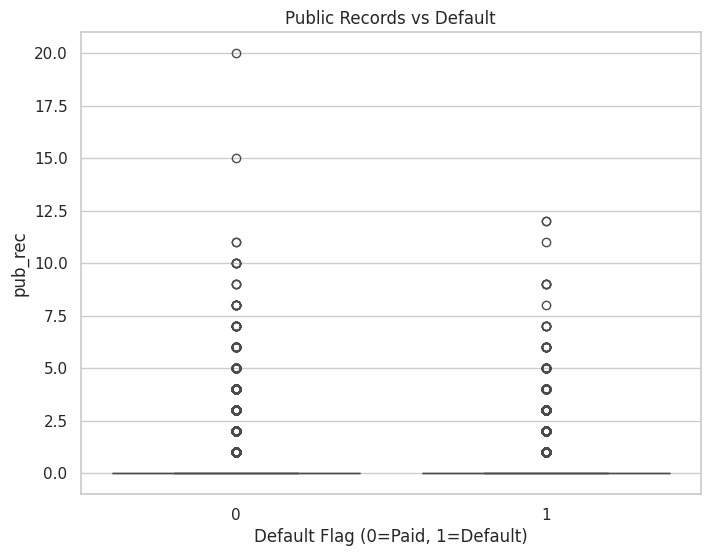

In [395]:


# 7️⃣ Public Records (e.g., Bankruptcy / Judgments)
plt.figure(figsize=(8,6))
sns.boxplot(x="default_flag", y="pub_rec", data=df_pd)
plt.title("Public Records vs Default")
plt.xlabel("Default Flag (0=Paid, 1=Default)")
plt.show()
# 🔹 Insight: More public records (bankruptcy/judgments) = higher default likelihood.

<Figure size 1200x600 with 0 Axes>

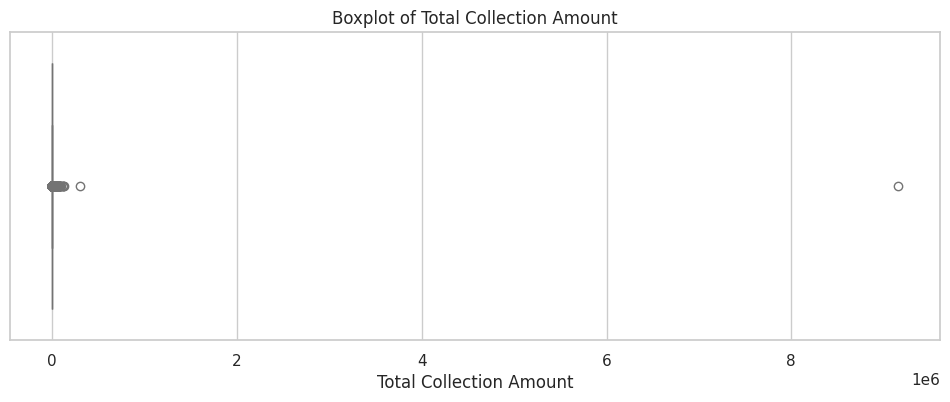

In [396]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Convert to Pandas and drop nulls
tot_coll_df = df_clean.select("tot_coll_amt").dropna().toPandas()

plt.figure(figsize=(12,6))


# Optional: Boxplot for extreme values
plt.figure(figsize=(12,4))
sns.boxplot(x=tot_coll_df["tot_coll_amt"], color="lightgreen")
plt.title("Boxplot of Total Collection Amount")
plt.xlabel("Total Collection Amount")
plt.show()


In [397]:


# Variables to check
columns_to_check = [
    "loan_status", "pymnt_plan", "collections_12_mths_ex_med",
    "acc_now_delinq", "delinq_2yrs", "mths_since_last_delinq", "pub_rec"
]

# Count unique values
unique_counts = df_pd[columns_to_check].nunique()

# Display
for col, count in unique_counts.items():
    print(f"{col}: {count} unique values")


loan_status: 8 unique values
pymnt_plan: 2 unique values
collections_12_mths_ex_med: 7 unique values
acc_now_delinq: 6 unique values
delinq_2yrs: 24 unique values
mths_since_last_delinq: 127 unique values
pub_rec: 15 unique values


In [398]:
# Variables to check
columns_to_check = [
    "loan_status", "pymnt_plan", "collections_12_mths_ex_med",
    "acc_now_delinq", "delinq_2yrs", "mths_since_last_delinq", "pub_rec"
]

# Check data types
for col in columns_to_check:
    dtype = df_pd[col].dtype
    col_type = "numeric" if np.issubdtype(dtype, np.number) else "string"
    print(f"{col}: {col_type} ({dtype})")


loan_status: string (object)
pymnt_plan: string (object)
collections_12_mths_ex_med: numeric (float64)
acc_now_delinq: numeric (float64)
delinq_2yrs: numeric (float64)
mths_since_last_delinq: numeric (float64)
pub_rec: numeric (float64)


In [399]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# Define categorical and numerical variables
cat_vars = ["loan_status", "pymnt_plan"]
num_vars = ["collections_12_mths_ex_med", "acc_now_delinq", "delinq_2yrs", "mths_since_last_delinq", "pub_rec"]

# Function to calculate Cramér's V
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2/n
    r,k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1),(rcorr-1)))

# Build Cramér's V matrix for categorical variables only
cramer_results = pd.DataFrame(index=cat_vars, columns=cat_vars)

for v1 in cat_vars:
    for v2 in cat_vars:
        cramer_results.loc[v1,v2] = cramers_v(df_pd[v1], df_pd[v2])

cramer_results


,loan_status,pymnt_plan
loan_status,1.0,0.014493
pymnt_plan,0.014493,0.928569


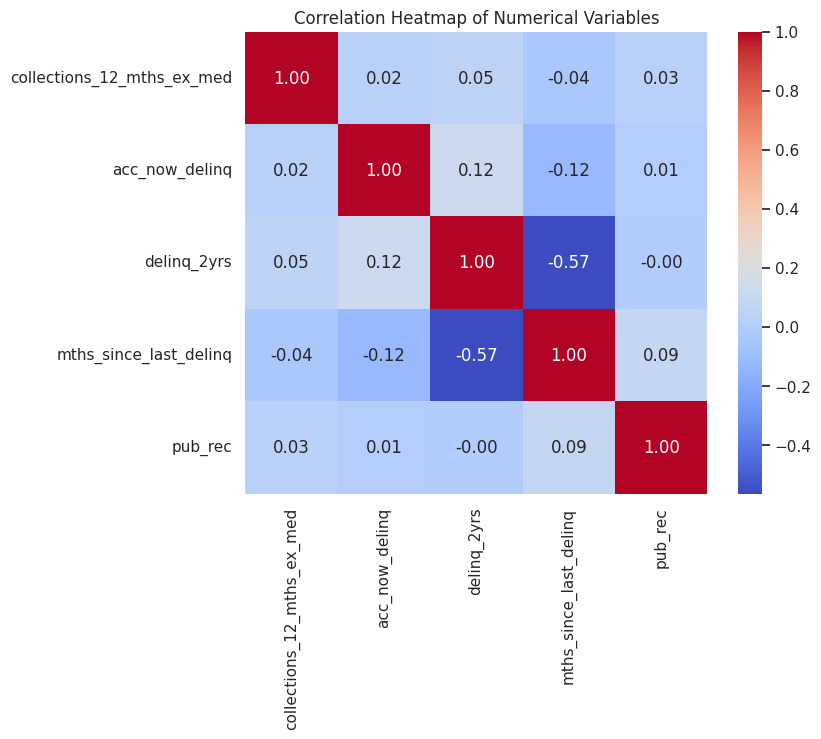

In [400]:
# Compute correlation matrix
corr_matrix = df_pd[num_vars].corr()  # Pearson correlation by default

# Plot heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

# **Credit History / Credit Utilization Analysis**

In [401]:
import numpy as np

# Credit-related columns
credit_cols = [
    "open_acc", "total_acc", "revol_bal", "revol_util",
    "tot_cur_bal", "total_rev_hi_lim", "earliest_cr_line"
]

# Keep only columns that exist in df_clean
available_credit_cols = [c for c in credit_cols if c in df_clean.columns]

# Convert selected columns to Pandas
credit_df = df_clean.select(available_credit_cols).toPandas()

# Check unique values, missing values, and data types
for col in available_credit_cols:
    unique_vals = credit_df[col].nunique()
    missing_vals = credit_df[col].isna().sum()
    dtype = credit_df[col].dtype
    col_type = "numeric" if np.issubdtype(dtype, np.number) else "string"
    print(f"{col}: {unique_vals} unique values, {missing_vals} missing values, type: {col_type} ({dtype})")


open_acc: 59 unique values, 29 missing values, type: numeric (float64)
total_acc: 110 unique values, 29 missing values, type: numeric (float64)
revol_bal: 48937 unique values, 0 missing values, type: numeric (float64)
revol_util: 1230 unique values, 253 missing values, type: numeric (float64)
tot_cur_bal: 144944 unique values, 66689 missing values, type: numeric (float64)
total_rev_hi_lim: 10000 unique values, 66689 missing values, type: numeric (float64)
earliest_cr_line: 649 unique values, 29 missing values, type: string (object)


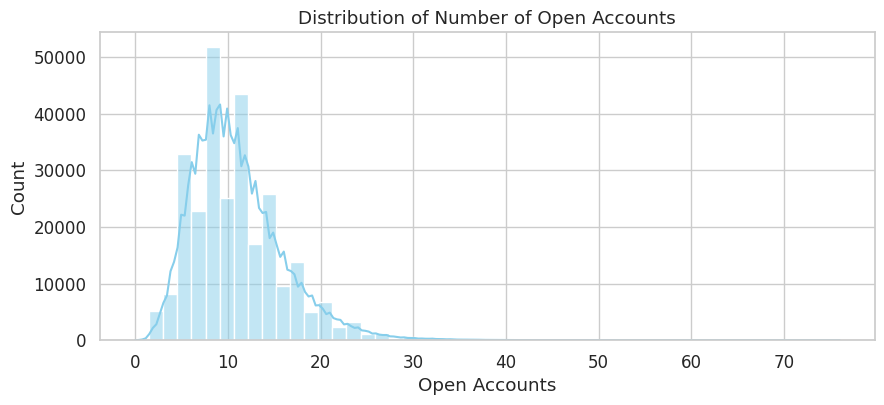

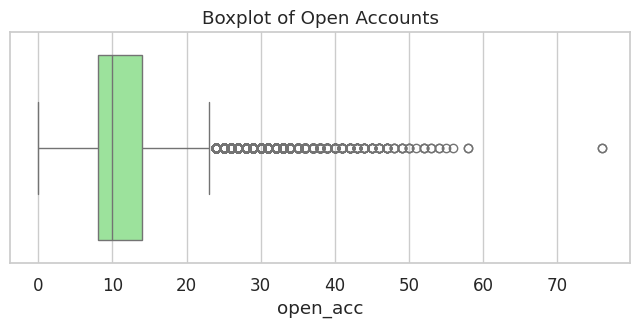

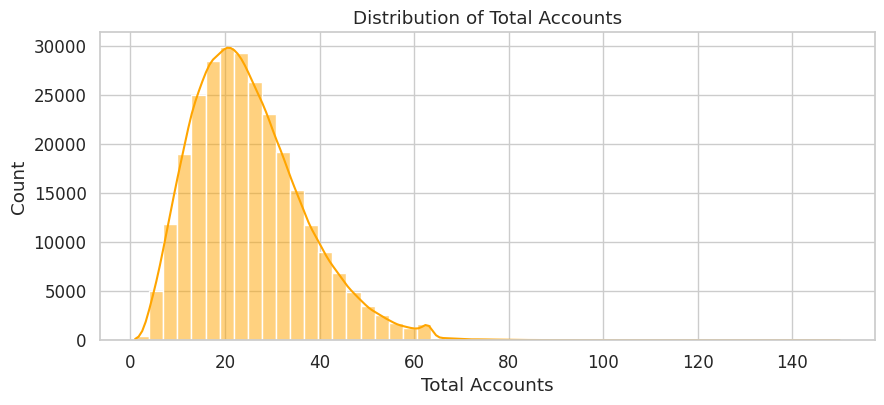

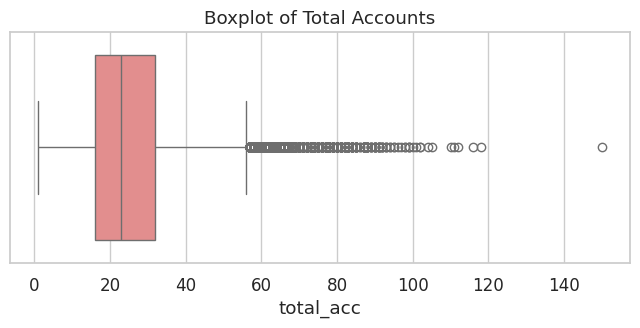

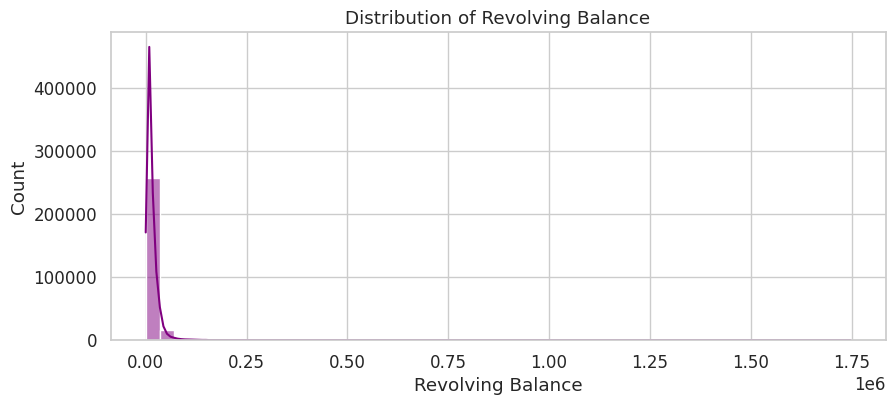

...

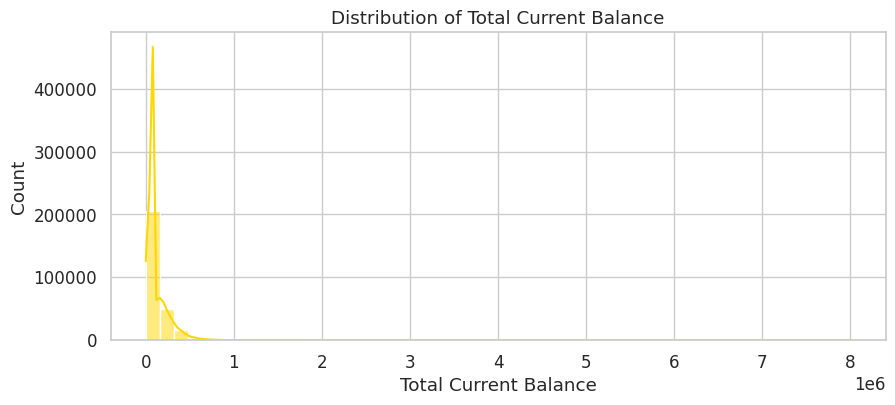

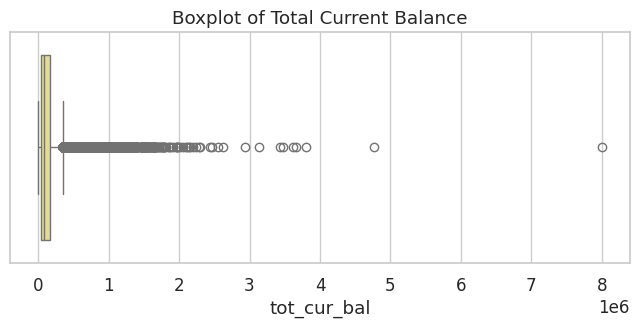

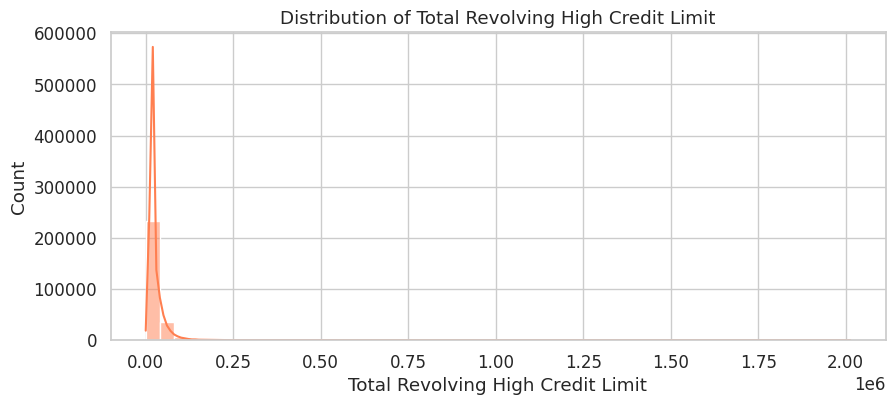

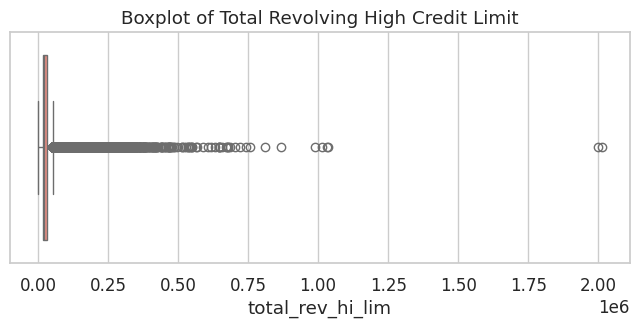

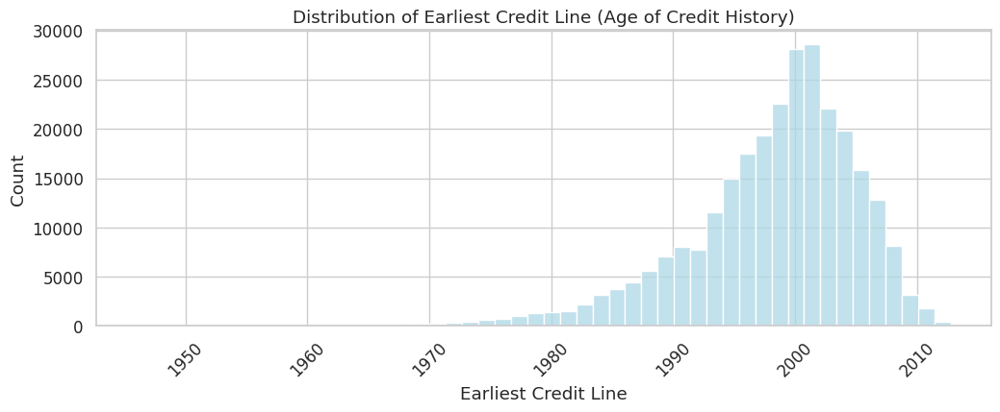

In [402]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set style
sns.set(style="whitegrid", font_scale=1.1)

# Fill missing values for plotting (optional: fill with median for numeric)
credit_df_filled = credit_df.copy()
for col in ["open_acc", "total_acc", "revol_bal", "revol_util", "tot_cur_bal", "total_rev_hi_lim"]:
    credit_df_filled[col] = credit_df_filled[col].fillna(credit_df_filled[col].median())

# 1️⃣ Number of open accounts
plt.figure(figsize=(10,4))
sns.histplot(credit_df_filled["open_acc"], bins=50, kde=True, color="skyblue")
plt.title("Distribution of Number of Open Accounts")
plt.xlabel("Open Accounts")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8,3))
sns.boxplot(x=credit_df_filled["open_acc"], color="lightgreen")
plt.title("Boxplot of Open Accounts")
plt.show()

# 2️⃣ Total accounts
plt.figure(figsize=(10,4))
sns.histplot(credit_df_filled["total_acc"], bins=50, kde=True, color="orange")
plt.title("Distribution of Total Accounts")
plt.xlabel("Total Accounts")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8,3))
sns.boxplot(x=credit_df_filled["total_acc"], color="lightcoral")
plt.title("Boxplot of Total Accounts")
plt.show()

# 3️⃣ Revolving balance
plt.figure(figsize=(10,4))
sns.histplot(credit_df_filled["revol_bal"], bins=50, kde=True, color="purple")
plt.title("Distribution of Revolving Balance")
plt.xlabel("Revolving Balance")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8,3))
sns.boxplot(x=credit_df_filled["revol_bal"], color="violet")
plt.title("Boxplot of Revolving Balance")
plt.show()

# 4️⃣ Revolving credit utilization %
plt.figure(figsize=(10,4))
sns.histplot(credit_df_filled["revol_util"], bins=50, kde=True, color="teal")
plt.title("Distribution of Revolving Credit Utilization (%)")
plt.xlabel("Revolving Utilization (%)")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8,3))
sns.boxplot(x=credit_df_filled["revol_util"], color="lightseagreen")
plt.title("Boxplot of Revolving Credit Utilization (%)")
plt.show()

# 5️⃣ Total current balance
plt.figure(figsize=(10,4))
sns.histplot(credit_df_filled["tot_cur_bal"], bins=50, kde=True, color="gold")
plt.title("Distribution of Total Current Balance")
plt.xlabel("Total Current Balance")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8,3))
sns.boxplot(x=credit_df_filled["tot_cur_bal"], color="khaki")
plt.title("Boxplot of Total Current Balance")
plt.show()

# 6️⃣ Total revolving high credit limit
plt.figure(figsize=(10,4))
sns.histplot(credit_df_filled["total_rev_hi_lim"], bins=50, kde=True, color="coral")
plt.title("Distribution of Total Revolving High Credit Limit")
plt.xlabel("Total Revolving High Credit Limit")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8,3))
sns.boxplot(x=credit_df_filled["total_rev_hi_lim"], color="salmon")
plt.title("Boxplot of Total Revolving High Credit Limit")
plt.show()

# 7️⃣ Age of credit history (earliest_cr_line)
# Convert to datetime
credit_df_filled["earliest_cr_line"] = pd.to_datetime(credit_df_filled["earliest_cr_line"], errors="coerce")

plt.figure(figsize=(12,4))
sns.histplot(credit_df_filled["earliest_cr_line"].dropna(), bins=50, kde=False, color="lightblue")
plt.title("Distribution of Earliest Credit Line (Age of Credit History)")
plt.xlabel("Earliest Credit Line")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()


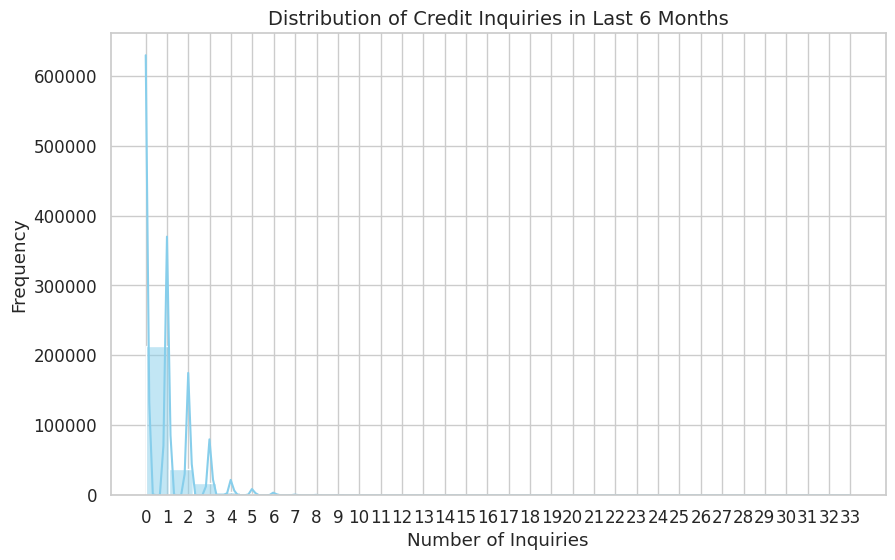

In [403]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert to Pandas with the relevant column and drop nulls
inq_df = df_clean.select("inq_last_6mths").dropna().toPandas()

plt.figure(figsize=(10,6))

# Histogram + KDE
sns.histplot(inq_df["inq_last_6mths"], bins=30, kde=True, color="skyblue")
plt.title("Distribution of Credit Inquiries in Last 6 Months", fontsize=14)
plt.xlabel("Number of Inquiries")
plt.ylabel("Frequency")
plt.xticks(range(int(inq_df["inq_last_6mths"].min()), int(inq_df["inq_last_6mths"].max())+1))
plt.show()


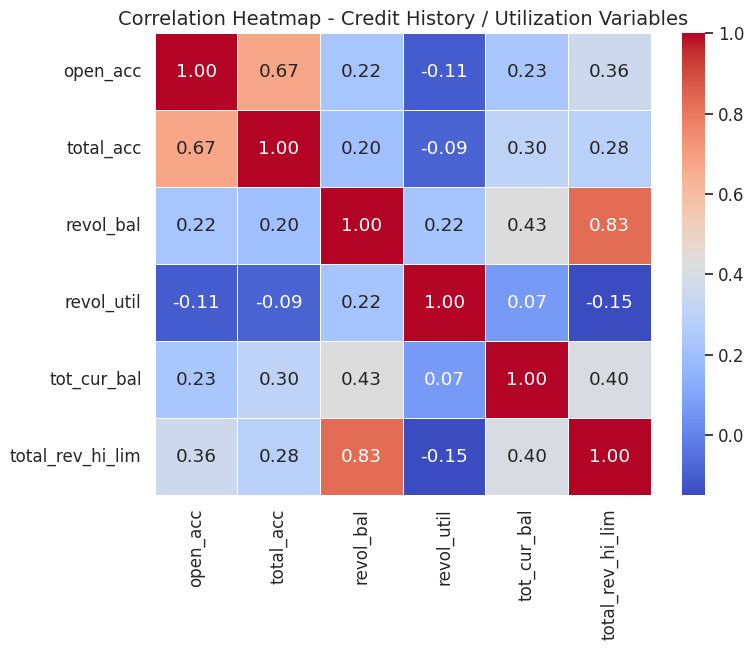

In [404]:
# Select only numeric columns
numeric_cols = credit_df.select_dtypes(include=['float64', 'int64'])

# Correlation matrix
corr_matrix = numeric_cols.corr()

# Plot heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap - Credit History / Utilization Variables", fontsize=14)
plt.show()

# **Payment / Recovery Analysis**

Check column info (dtypes, nulls, uniques)

In [405]:
# List of columns for Payment / Recovery analysis
pay_cols = [
    "total_pymnt", "total_pymnt_inv", "total_rec_prncp",
    "total_rec_int", "total_rec_late_fee", "recoveries",
    "collection_recovery_fee", "last_pymnt_d", "last_pymnt_amnt",
    "next_pymnt_d"
]

# Check data types, missing values, unique counts
for col in pay_cols:
    if col in df_clean.columns:
        print(f"\n--- {col} ---")
        df_clean.select(
            F.countDistinct(col).alias("unique_count"),
            F.count(F.when(F.col(col).isNull(), col)).alias("missing_count")
        ).show()
        print(f"Data type: {dict(df_clean.dtypes)[col]}")


--- total_pymnt ---
+------------+-------------+
|unique_count|missing_count|
+------------+-------------+
|      262627|            0|
+------------+-------------+

Data type: double

--- total_pymnt_inv ---
+------------+-------------+
|unique_count|missing_count|
+------------+-------------+
|      255449|            0|
+------------+-------------+

Data type: double

--- total_rec_prncp ---
+------------+-------------+
|unique_count|missing_count|
+------------+-------------+
|       62832|            0|
+------------+-------------+

Data type: double

--- total_rec_int ---
+------------+-------------+
|unique_count|missing_count|
+------------+-------------+
|      196120|            0|
+------------+-------------+

Data type: double

--- total_rec_late_fee ---
+------------+-------------+
|unique_count|missing_count|
+------------+-------------+
|        5461|            0|
+------------+-------------+

Data type: double

--- recoveries ---
+------------+-------------+
|unique_c

Convert to Pandas (for plotting)

In [408]:
import pandas as pd

# List of columns to convert to Pandas
pay_cols_existing = [c for c in pay_cols if c in df_clean.columns]

# Convert to Pandas
pay_df = df_clean.select(pay_cols_existing).toPandas()

# Convert only the date columns that exist
date_cols_existing = [c for c in ["last_pymnt_d", "next_pymnt_d"] if c in pay_df.columns]
for dc in date_cols_existing:
    pay_df[dc] = pd.to_datetime(pay_df[dc], errors="coerce")


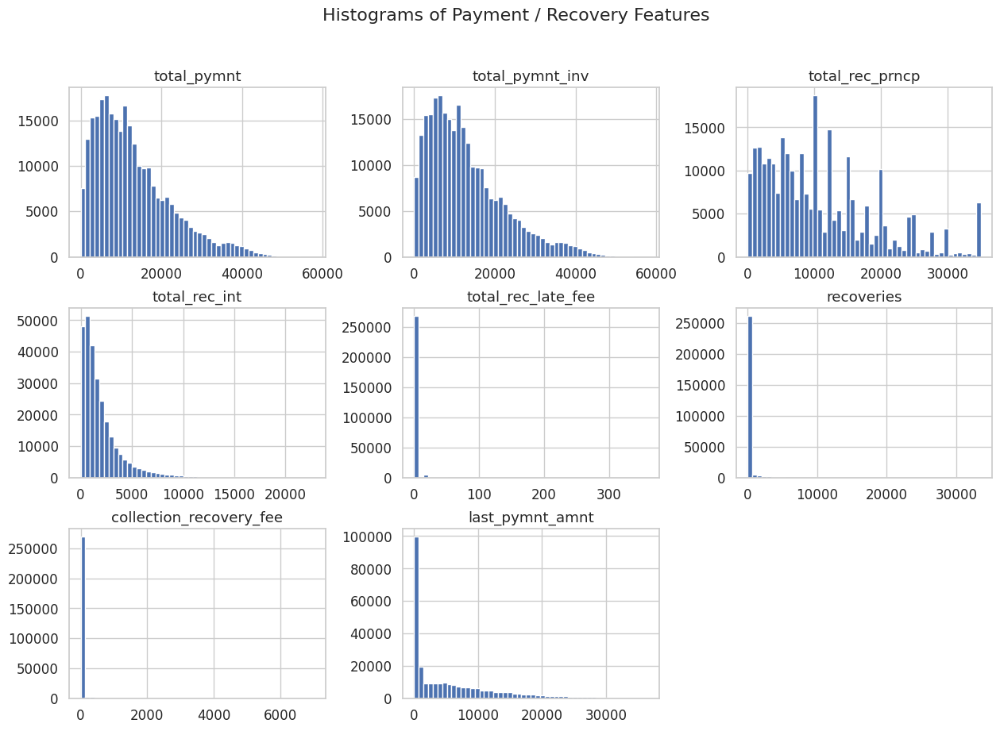

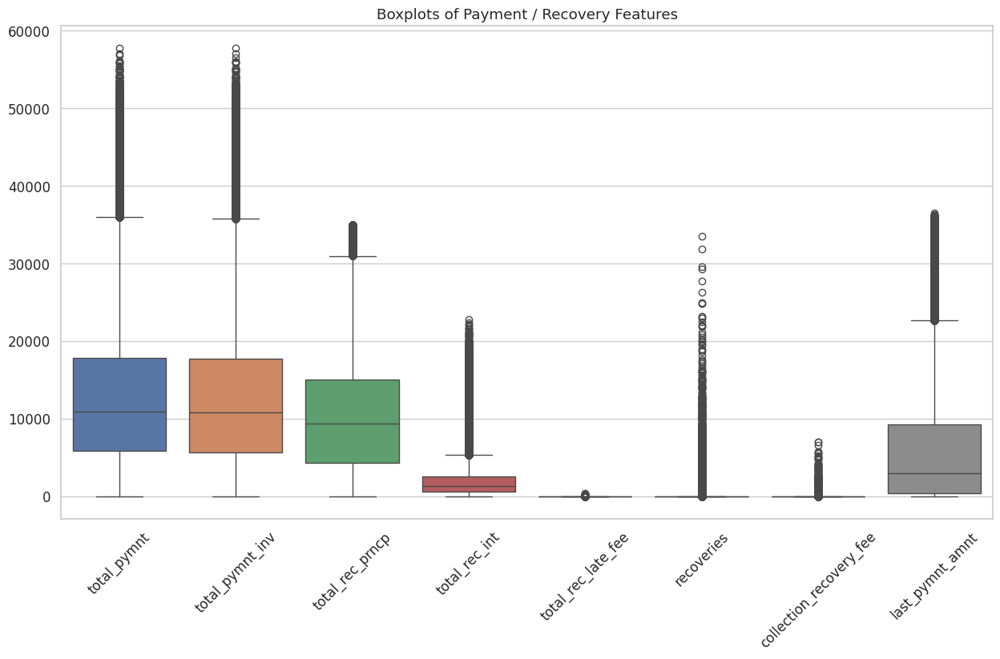

In [409]:
num_cols = [
    "total_pymnt", "total_pymnt_inv", "total_rec_prncp",
    "total_rec_int", "total_rec_late_fee", "recoveries",
    "collection_recovery_fee", "last_pymnt_amnt"
]

# Histograms
pay_df[num_cols].hist(figsize=(15,10), bins=50)
plt.suptitle("Histograms of Payment / Recovery Features", fontsize=16)
plt.show()

# Boxplots
plt.figure(figsize=(15,8))
sns.boxplot(data=pay_df[num_cols])
plt.xticks(rotation=45)
plt.title("Boxplots of Payment / Recovery Features")
plt.show()


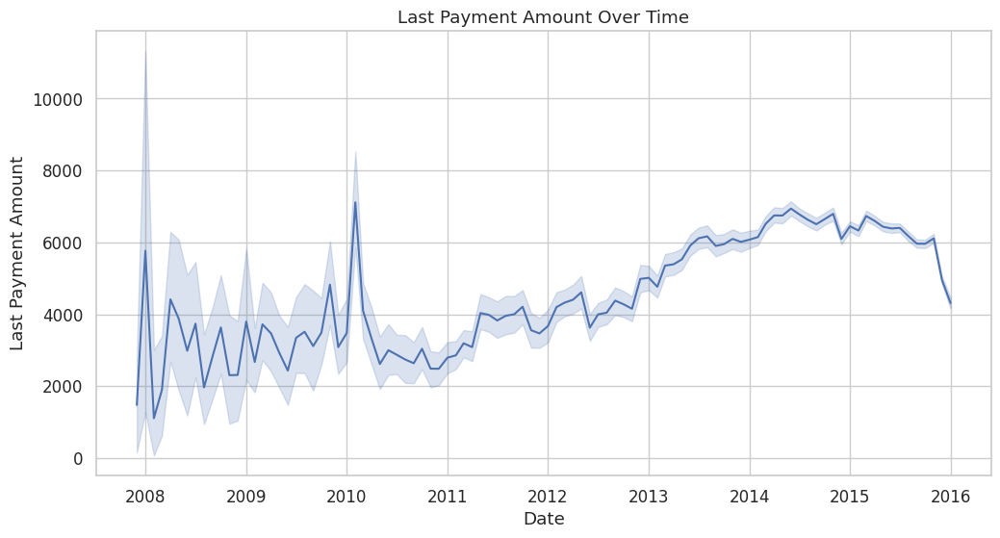

In [410]:
# Last payment amounts over time
plt.figure(figsize=(12,6))
sns.lineplot(x="last_pymnt_d", y="last_pymnt_amnt", data=pay_df)
plt.title("Last Payment Amount Over Time")
plt.xlabel("Date")
plt.ylabel("Last Payment Amount")
plt.show()

# Next scheduled payments (if available)
if "next_pymnt_d" in pay_df.columns:
    plt.figure(figsize=(12,6))
    sns.histplot(pay_df["next_pymnt_d"].dropna(), bins=30, kde=False)
    plt.title("Distribution of Next Payment Dates")
    plt.xlabel("Next Payment Date")
    plt.ylabel("Count of Loans")
    plt.show()


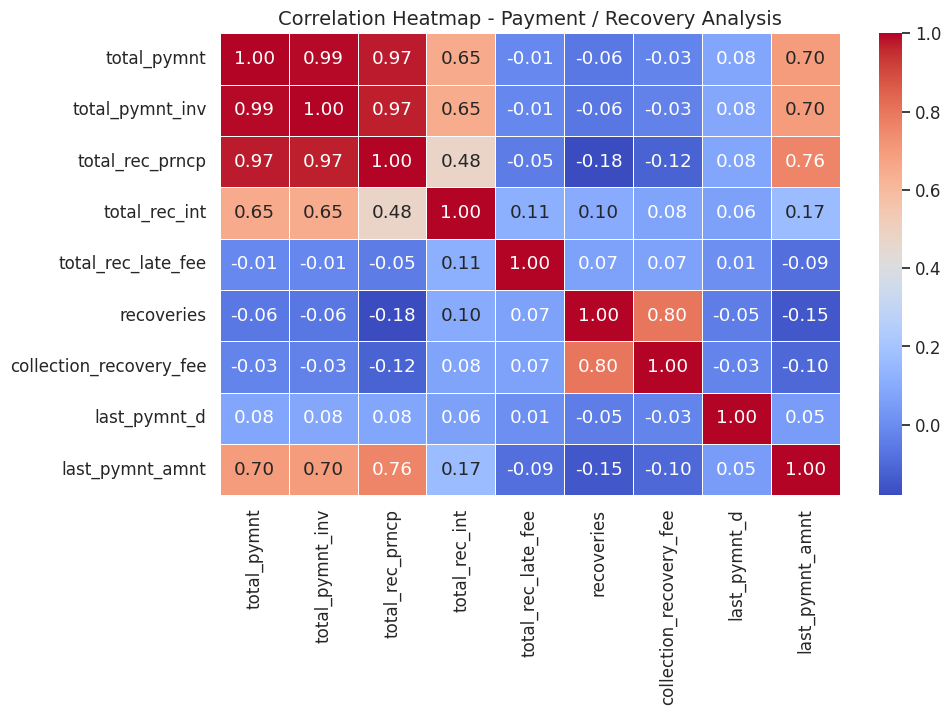

In [411]:
# Compute correlation matrix
corr_matrix = pay_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap - Payment / Recovery Analysis", fontsize=14)
plt.show()

# **Geographic Analysis**

In [412]:
print(df_clean.columns)

['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'desc', 'purpose', 'title', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'policy_code', 'application_type', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim']


In [413]:
from pyspark.sql import functions as F

# Geographic columns
geo_cols = ["addr_state"]

# Data types
print("Schema (data types):")
df_clean.select(geo_cols).printSchema()

# Missing values count
print("\nMissing Values:")
df_clean.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in geo_cols]).show()

# Unique value counts
for col in geo_cols:
    print(f"\nColumn: {col}")
    # Count distinct
    unique_count = df_clean.select(col).distinct().count()
    print(f"Total unique: {unique_count}")

    # Top 20 most frequent values
    df_clean.groupBy(col).count().orderBy(F.desc("count")).show(20, truncate=False)


Schema (data types):
root
 |-- addr_state: string (nullable = true)


Missing Values:
+----------+
|addr_state|
+----------+
|         0|
+----------+


Column: addr_state
Total unique: 51
+----------+-----+
|addr_state|count|
+----------+-----+
|CA        |46519|
|NY        |23694|
|TX        |21193|
|FL        |19329|
|NJ        |10549|
|IL        |10080|
|PA        |9329 |
|GA        |8784 |
|VA        |8734 |
|OH        |8486 |
|NC        |7613 |
|MA        |6715 |
|AZ        |6642 |
|MD        |6637 |
|MI        |6616 |
|WA        |6367 |
|CO        |6068 |
|MN        |4865 |
|MO        |4310 |
|NV        |4192 |
+----------+-----+
only showing top 20 rows



In [414]:
import plotly.express as px

# Aggregate loan counts (and defaults if available)
state_summary = df_clean.groupBy("addr_state") \
    .agg(
        F.count("*").alias("loan_count"),
        F.mean(F.when(F.col("loan_status") == "Default", 1).otherwise(0)).alias("default_rate")
    )

# Convert to Pandas for mapping
state_summary_pd = state_summary.toPandas()

# Plot: Choropleth map of loan count
fig = px.choropleth(
    state_summary_pd,
    locations="addr_state",        # State codes (CA, NY, etc.)
    locationmode="USA-states",     # Tells plotly we’re using US state abbreviations
    color="loan_count",            # Coloring by loan count
    scope="usa",                   # Focus only on USA
    title="Loan Counts by State"
)
fig.show()

# Plot: Choropleth map of default rate
fig2 = px.choropleth(
    state_summary_pd,
    locations="addr_state",
    locationmode="USA-states",
    color="default_rate",
    scope="usa",
    title="Default Rate by State"
)
fig2.show()


In [415]:
import plotly.express as px
import pandas as pd
from pyspark.sql import functions as F

# ===========================================================
# 1️⃣ Aggregate key metrics by state
# ===========================================================
state_summary = df_clean.groupBy("addr_state").agg(
    F.count("*").alias("loan_count"),
    F.mean(F.col("loan_amnt")).alias("avg_loan_amount"),
    F.mean(F.col("funded_amnt")).alias("avg_funded_amount"),
    F.mean(F.when(F.col("loan_status") == "Default", 1).otherwise(0)).alias("default_rate"),
    F.mean(F.col("int_rate")).alias("avg_int_rate")
)

# Convert to Pandas
state_summary_pd = state_summary.toPandas()





In [416]:

# ===========================================================
# 3️⃣ Bubble map to visualize multiple metrics
# ===========================================================
fig2 = px.scatter_geo(
    state_summary_pd,
    locations="addr_state",
    locationmode="USA-states",
    size="loan_count",
    color="default_rate",
    hover_name="addr_state",
    hover_data={
        "avg_loan_amount": ":,.2f",
        "avg_funded_amount": ":,.2f",
        "avg_int_rate": ":.2f"
    },
    color_continuous_scale="reds",
    size_max=50,
    scope="usa",
    title="Loan Counts & Default Rate by State (Bubble Map)"
)
fig2.show()


0.002 = 0.2% of loans in that state are in Default status.

0 = 0% → no loans have defaulted in that state.

In [417]:

# ===========================================================
# 2️⃣ World map approximation (plot by US states, can extend to countries if available)
# ===========================================================
# If you had countries: px.choropleth(state_summary_pd, locations="country", ...)
# Since data is US states:
fig = px.choropleth(
    state_summary_pd,
    locations="addr_state",
    locationmode="USA-states",
    color="loan_count",
    hover_name="addr_state",
    hover_data={
        "avg_loan_amount": ":,.2f",
        "avg_funded_amount": ":,.2f",
        "default_rate": ":.2%",
        "avg_int_rate": ":.2f",
        "loan_count": True
    },
    color_continuous_scale="Viridis",
    scope="usa",
    title="Loan Overview by US State"
)
fig.show()

In [418]:
import plotly.express as px
import pandas as pd

# Add a country column (all loans from the U.S.)
df_pd["country"] = "United States"

# Aggregate by country
country_summary = df_pd.groupby("country").agg(
    loan_count=pd.NamedAgg(column="loan_status", aggfunc="count"),
    default_rate=pd.NamedAgg(column="default_flag", aggfunc="mean")
).reset_index()

# Print country names and loan counts
print(country_summary[["country", "loan_count"]].sort_values(by="loan_count", ascending=False))

# Plot world map
fig = px.choropleth(
    country_summary,
    locations="country",
    locationmode="country names",
    color="loan_count",
    hover_name="country",
    hover_data={
        "loan_count": True,
        "default_rate": True
    },
    color_continuous_scale="Viridis",
    title="Global Loan Overview by Country"
)
fig.show()


         country  loan_count
0  United States      277140


In [419]:
# ===========================================================
# 4️⃣ Optional: Pairwise scatterplots for key variables by state
# ===========================================================
# Convert Spark to Pandas for numeric analysis
loan_vars = ["loan_amnt", "funded_amnt", "funded_amnt_inv", "int_rate", "installment", "annual_inc", "dti"]
available_vars = [v for v in loan_vars if v in df_clean.columns]

loan_df_pd = df_clean.select("addr_state", *available_vars).toPandas()
loan_df_pd = loan_df_pd.dropna(subset=available_vars)

# Scatterplot matrix with larger figure size
fig3 = px.scatter_matrix(
    loan_df_pd,
    dimensions=available_vars,   # numeric columns to plot
    color="addr_state",          # color points by state
    title="Pairwise Relationships: Loan Variables by State",
    hover_name="addr_state",
    width=2000,                  # increase width
    height=2000                  # increase height
)

# Hide diagonal histograms for clarity
fig3.update_traces(diagonal_visible=False)

# Show the enlarged plot
fig3.show()

# **Pre Processing**

# Handling Missing values

In [467]:
# Drop emp_title
df_clean = df_clean.drop("emp_title")
# Drop title
df_clean = df_clean.drop("title")



**Handling `title` Feature**

- `title` is a categorical description of the loan purpose (short text summary).  
- Only 14 missing values, representing a very small proportion of the dataset.  
-removed it bacause it has so many unique values = 50184 unique values

**Handling `desc` Feature**

- The `desc` column contains free-text descriptions of the loan purpose or borrower notes.  
- This feature has **184,478 missing values**, representing a large proportion of the dataset.  
- With such a high level of missingness, the column is unlikely to provide consistent or meaningful information for modeling.  
- **Action:** Drop the `desc` column to reduce noise and simplify the dataset.


In [436]:
df_clean = df_clean.drop("desc")




We carefully handle missing values and transformations for key features to improve model quality:

1. **mths_since_last_delinq (Months since last delinquency)**  
   - Many nulls → indicates *no delinquency*.  
   - Strategy: Create binary flag `has_delinq` (1 if not null, else 0).  
   - For numeric modeling, replace nulls with a large value (e.g., max+1) or median.

2. **annual_inc (Annual Income)**  
   - Only 4 nulls → very few missing.  
   - Strategy: Fill missing with median income.  
   - Strong predictive power: higher income usually means lower default risk.

3. **delinq_2yrs (Delinquencies in past 2 years)**  
   - 29 nulls → likely means no delinquencies.  
   - Strategy: Replace nulls with `0`.  
   - Important predictor: more recent delinquencies = higher risk.

4. **inq_last_6mths (Credit inquiries in last 6 months)**  
   - 29 nulls → treat as `0`.  
   - Strategy: Replace nulls with `0`.  
   - Frequent inquiries often signal higher credit risk.

5. **open_acc (Number of open accounts)**  
   - 29 nulls → very few missing.  
   - Strategy: Fill missing with median value.  
   - Reflects credit usage and profile strength.

6. **pub_rec (Derogatory public records)**  
   - 29 nulls → treat as `0`.  
   - Strategy: Replace nulls with `0`.  
   - Presence of public records increases default risk.

7. **revol_util (Revolving credit utilization, %)**  
   - 502 nulls.  
   - Strategy: Fill with median value.  
   - Higher utilization strongly correlates with higher risk.

8. **tot_cur_bal (Total current balance on all accounts)**  
   - 70,276 nulls (quite large).  
   - Strategy: Fill with median value.  
   - Represents borrower’s total financial exposure.

9. **total_rev_hi_lim (Total revolving credit limit)**  
   - 70,276 nulls.  
   - Strategy: Fill with median value.  
   - Indicates available credit capacity.

10. **collections_12_mths_ex_med (Collections in last 12 months, excl. medical)**  
    - 145 nulls → small number.  
    - Strategy: Replace nulls with `0`.  
    - Active collections = higher risk.

11. **acc_now_delinq (Currently delinquent accounts)**  
    - 29 nulls → treat as `0`.  
    - Strategy: Replace nulls with `0`.  
    - Strong risk indicator.

12. **tot_coll_amt (Total collection amount owed)**  
    - 70,276 nulls.  
    - Strategy: Replace nulls with `0`.  
    - Any outstanding collections increase risk.

12. **total_acc (Total number of credit lines ever opened)**  
    - 29 nulls → very few missing.
    - Strategy: Fill missing with median value
    - Represents overall credit experience: more total accounts usually indicate longer and more established credit history, which can reduce default risk.





.



In [422]:
# -----------------------------
# 2️⃣ Fill numeric columns
# -----------------------------

# annual_inc → median
median_annual_inc = df_clean.approxQuantile("annual_inc", [0.5], 0.01)[0]
df_clean = df_clean.fillna({"annual_inc": median_annual_inc})

# delinq_2yrs → 0
df_clean = df_clean.fillna({"delinq_2yrs": 0})

# inq_last_6mths → 0
df_clean = df_clean.fillna({"inq_last_6mths": 0})

# open_acc → median
median_open_acc = df_clean.approxQuantile("open_acc", [0.5], 0.01)[0]
df_clean = df_clean.fillna({"open_acc": median_open_acc})

# pub_rec → 0
df_clean = df_clean.fillna({"pub_rec": 0})

# revol_util → median
median_revol_util = df_clean.approxQuantile("revol_util", [0.5], 0.01)[0]
df_clean = df_clean.fillna({"revol_util": median_revol_util})

# tot_cur_bal → median
median_tot_cur_bal = df_clean.approxQuantile("tot_cur_bal", [0.5], 0.01)[0]
df_clean = df_clean.fillna({"tot_cur_bal": median_tot_cur_bal})

# total_rev_hi_lim → median
median_total_rev_hi_lim = df_clean.approxQuantile("total_rev_hi_lim", [0.5], 0.01)[0]
df_clean = df_clean.fillna({"total_rev_hi_lim": median_total_rev_hi_lim})

# collections_12_mths_ex_med → 0
df_clean = df_clean.fillna({"collections_12_mths_ex_med": 0})

# acc_now_delinq → 0
df_clean = df_clean.fillna({"acc_now_delinq": 0})

# tot_coll_amt → 0
df_clean = df_clean.fillna({"tot_coll_amt": 0})

# total_acc → median
median_total_acc = df_clean.approxQuantile("total_acc", [0.5], 0.01)[0]
df_clean = df_clean.fillna({"total_acc": median_total_acc})

# -----------------------------
# 3️⃣ Confirm
# -----------------------------
df_clean.select(
    "annual_inc", "delinq_2yrs", "inq_last_6mths", "open_acc",
    "pub_rec", "revol_util", "tot_cur_bal", "total_rev_hi_lim",
    "collections_12_mths_ex_med", "acc_now_delinq", "tot_coll_amt", "total_acc"
).show(5)


+----------+-----------+--------------+--------+-------+----------+-----------+----------------+--------------------------+--------------+------------+---------+
|annual_inc|delinq_2yrs|inq_last_6mths|open_acc|pub_rec|revol_util|tot_cur_bal|total_rev_hi_lim|collections_12_mths_ex_med|acc_now_delinq|tot_coll_amt|total_acc|
+----------+-----------+--------------+--------+-------+----------+-----------+----------------+--------------------------+--------------+------------+---------+
|   24000.0|        0.0|           1.0|     3.0|    0.0|      83.7|    78123.0|         22100.0|                       0.0|           0.0|         0.0|      9.0|
|   30000.0|        0.0|           5.0|     3.0|    0.0|       9.4|    78123.0|         22100.0|                       0.0|           0.0|         0.0|      4.0|
|   12252.0|        0.0|           2.0|     2.0|    0.0|      98.5|    78123.0|         22100.0|                       0.0|           0.0|         0.0|     10.0|
|   49200.0|        0.0|    

In [423]:
# 6. Missing values count per column
missing_df = df_clean.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_clean.columns])
missing_df.show(vertical=True, truncate=False)

-RECORD 0----------------------------
 loan_amnt                  | 0      
 funded_amnt                | 0      
 funded_amnt_inv            | 0      
 term                       | 0      
 int_rate                   | 0      
 installment                | 0      
 grade                      | 0      
 sub_grade                  | 0      
 emp_title                  | 15388  
 emp_length                 | 0      
 home_ownership             | 0      
 annual_inc                 | 0      
 verification_status        | 0      
 issue_d                    | 0      
 loan_status                | 0      
 pymnt_plan                 | 0      
 desc                       | 184479 
 purpose                    | 0      
 title                      | 14     
 addr_state                 | 0      
 dti                        | 0      
 delinq_2yrs                | 0      
 earliest_cr_line           | 29     
 inq_last_6mths             | 0      
 mths_since_last_delinq     | 151930 
 open_acc   

**Inspecting Rows with NULL `earliest_cr_line`**

Before removal, it is useful to check whether these rows contain critical information.  
Key columns to inspect:  

- **loan_status** → Main outcome (default, fully paid, etc.)  
- **loan_amnt** → Loan size, to identify unusual amounts  
- **int_rate** → Risk level of the loan  
- **issue_d** → Date when the loan was issued  
- **addr_state** → Geographical distribution  
- **annual_inc** → Borrower’s income  

👉 Reviewing these 29 rows helps decide:  
- If they look normal, they can be safely dropped.  
- If they appear systematically different (e.g., only very old loans), a different handling approach may be required.  


In [424]:
# Show rows where earliest_cr_line is NULL
df_clean.filter(F.col("earliest_cr_line").isNull()) \
    .select("loan_status", "loan_amnt", "int_rate", "issue_d", "addr_state", "annual_inc") \
    .show(30, truncate=False)

+---------------------------------------------------+---------+--------+----------+----------+----------+
|loan_status                                        |loan_amnt|int_rate|issue_d   |addr_state|annual_inc|
+---------------------------------------------------+---------+--------+----------+----------+----------+
|Does not meet the credit policy. Status:Fully Paid |5000.0   |7.43    |2007-08-01|NY        |62000.0   |
|Does not meet the credit policy. Status:Fully Paid |7000.0   |7.75    |2007-08-01|NY        |62000.0   |
|Does not meet the credit policy. Status:Fully Paid |4350.0   |8.07    |2007-08-01|MA        |120000.0  |
|Does not meet the credit policy. Status:Fully Paid |3900.0   |9.33    |2007-08-01|NY        |98000.0   |
|Does not meet the credit policy. Status:Fully Paid |6700.0   |7.75    |2007-07-01|NY        |62000.0   |
|Does not meet the credit policy. Status:Fully Paid |3200.0   |9.96    |2007-07-01|MA        |150000.0  |
|Does not meet the credit policy. Status:Fully

**Handling Missing Values in `earliest_cr_line`**

- Rows where `earliest_cr_line` was NULL were removed.  
- Only 29 missing values were found out of hundreds of thousands of rows.  
- Rather than imputing or filling these values, filtering them out ensures data consistency.  
- The resulting dataset contains no null values in `earliest_cr_line`.  

In [425]:
df_clean = df_clean.filter(df_clean.earliest_cr_line.isNotNull())

# **Feature Engineering**

## **Drop Columns**

### 1️⃣ `next_pymnt_d` (Next Payment Date)

- **Reason:** This is a **future-looking variable**, not known at the time of loan issuance.  
- Using it in your model would cause **data leakage**, because it contains information about future payments.

---

### 2️⃣ `last_pymnt_d` (Last Payment Date)

- **Reason:** This tells you **when the borrower last paid**, which is also **after the loan started**.  
- Including it would give the model **direct insight into the repayment behavior**, creating **leakage**.

---

### 3️⃣ `last_credit_pull_d` (Last Credit Pull Date)

- **Reason:** This is **external information after loan issuance**.  
- Could leak information about borrower behavior after the loan started.  
- Better to replace with derived features like **days since last credit inquiry before loan issuance** if needed.



In [426]:


drop_cols = [
    "next_pymnt_d",
    "last_pymnt_d",
    "last_credit_pull_d"
]

df = df_clean.drop(*drop_cols)



- **mths_since_last_delinq → has_delinq**  
  Creates a binary flag indicating whether a borrower has had any delinquency.  
  This captures the existence of delinquency without relying on the exact number of months, which may be missing for many borrowers.  

- **tot_coll_amt & collections_12_mths_ex_med → avg_collection_amt**  
  Combines two related features into a single average collection amount per collection instance.  
  - `tot_coll_amt`: Total collection amount in the last 12 months  
  - `collections_12_mths_ex_med`: Number of collections in the last 12 months  
  - `avg_collection_amt`: Represents the typical severity per collection. If no collections exist, set to 0.  

- **revol_bal & total_rev_hi_lim → calculated_revol_util**  
  Creates a more accurate measure of credit utilization:  
  - `revol_bal`: Current revolving balance  
  - `total_rev_hi_lim`: Total revolving credit limit  
  - `calculated_revol_util`: Percentage of available credit being used  
  Using this instead of raw `revol_util` addresses missing or inconsistent values.  

- **Dropping original columns**  
  After creating the engineered features, the original columns are redundant. Dropping them reduces dimensionality and avoids multicollinearity, which can confuse models.


In [427]:
# -----------------------------
# 1️⃣ Convert mths_since_last_delinq into categorical
# -----------------------------
# Create 'has_delinq' flag: 1 if there was a delinquency, 0 if null
df_clean = df_clean.withColumn(
    "has_delinq",
    F.when(F.col("mths_since_last_delinq").isNotNull(), 1).otherwise(0)
)


In [428]:
# ================================
# Create df_clean from df with feature engineering
# ================================
df_clean = (
    df
    # 1. mths_since_last_delinq → has_delinq

    .withColumn("has_delinq", F.when(F.col("mths_since_last_delinq").isNotNull(), 1).otherwise(0))

    # 2. tot_coll_amt & collections_12_mths_ex_med → avg_collection_amt
    .withColumn("avg_collection_amt",
                F.when(F.col("collections_12_mths_ex_med") > 0,
                       F.col("tot_coll_amt") / F.col("collections_12_mths_ex_med"))
                 .otherwise(0))

    # 3. revol_bal & total_rev_hi_lim → calculated_revol_util
    .withColumn("calculated_revol_util",
                F.when(F.col("total_rev_hi_lim") > 0,
                       (F.col("revol_bal") / F.col("total_rev_hi_lim")) * 100)
                 .otherwise(0))



    # 6. Drop original raw columns
    .drop("mths_since_last_delinq",
          "tot_coll_amt",
          "collections_12_mths_ex_med",
          "revol_bal",
          "total_rev_hi_lim")
)

Finding the Earliest and Latest Dates in a Column


*   Understand the time period covered by the dataset (from the first to the last loan issued).


In [429]:

df_clean.select(
    F.min("earliest_cr_line").alias("first_earliest_cr_line"),
    F.max("earliest_cr_line").alias("last_earliest_cr_line")
).show()

+----------------------+---------------------+
|first_earliest_cr_line|last_earliest_cr_line|
+----------------------+---------------------+
|            1946-01-01|           2012-10-01|
+----------------------+---------------------+



In [480]:
from pyspark.sql import functions as F

df_clean.select(
    F.min("issue_d").alias("first_issue_date"),
    F.max("issue_d").alias("last_issue_date")
).show()


+----------------+---------------+
|first_issue_date|last_issue_date|
+----------------+---------------+
|      2007-06-01|     2015-12-01|
+----------------+---------------+



The earliest loan in your dataset was issued in June 2007.

The latest loan was issued in December 2015.

So, the dataset covers a loan issuance time span of about 8 years and 6 months.

**Credit History Length Calculation**

- **earliest_cr_line**: Date of the borrower’s first credit line.  
- **issue_d**: Date when the loan was issued.  

Calculating the difference between `issue_d` and `earliest_cr_line` provides the duration of the borrower’s credit history before taking the loan.  

- **Dividing by 12**: The `months_between` function returns the difference in months. Dividing by 12 converts the value to years, making it easier to interpret.  
- **Casting to double**: Ensures that the new column `credit_history_length` is numeric, allowing its use in modeling or correlation analysis.


In [490]:
from pyspark.sql import functions as F
from pyspark.sql.types import DateType

# 1️⃣ Ensure the columns are DateType
df_clean = df_clean.withColumn("issue_d", F.col("issue_d").cast(DateType()))
df_clean = df_clean.withColumn("earliest_cr_line", F.col("earliest_cr_line").cast(DateType()))

# 2️⃣ Create credit_history_length in months safely
df_clean = df_clean.withColumn(
    "credit_history_length",
    F.when(
        F.col("issue_d").isNotNull() & F.col("earliest_cr_line").isNotNull(),
        F.months_between(F.col("issue_d"), F.col("earliest_cr_line"))
    ).otherwise(None)  # or 0 if you prefer
)

# Optional: convert months to years
# df_clean = df_clean.withColumn("credit_history_length_years", F.col("credit_history_length") / 12)

# 3️⃣ Drop original date columns
df_clean = df_clean.drop("issue_d", "earliest_cr_line")

# 4️⃣ Check schema
df_clean.printSchema()

# 5️⃣ Preview new column
df_clean.select("credit_history_length").show(5)


AnalysisException: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column or function parameter with name `issue_d` cannot be resolved. Did you mean one of the following? [`dti`, `grade`, `term`, `pub_rec`, `sub_grade`].;
'Project [loan_amnt#44392, funded_amnt#44393, funded_amnt_inv#44394, term#44395, int_rate#44396, installment#44397, grade#44398, sub_grade#44399, emp_length#44401, home_ownership#44402, annual_inc#51690, verification_status#44404, loan_status#44406, pymnt_plan#44407, purpose#44410, addr_state#44413, dti#44414, delinq_2yrs#51791, inq_last_6mths#51892, open_acc#52049, pub_rec#52150, revol_util#52307, total_acc#53081, initial_list_status#44425, ... 19 more fields]
+- Project [loan_amnt#44392, funded_amnt#44393, funded_amnt_inv#44394, term#44395, int_rate#44396, installment#44397, grade#44398, sub_grade#44399, emp_length#44401, home_ownership#44402, annual_inc#51690, verification_status#44404, loan_status#44406, pymnt_plan#44407, purpose#44410, addr_state#44413, dti#44414, delinq_2

In [485]:
# Calculate difference in months
df = df.withColumn(
    "credit_history_length",
    (F.months_between(F.col("issue_d"), F.col("earliest_cr_line")) / 12).cast("double")
)

# Check the new column
df.select("issue_d", "earliest_cr_line", "credit_history_length").show(10)

+----------+----------------+---------------------+
|   issue_d|earliest_cr_line|credit_history_length|
+----------+----------------+---------------------+
|2011-12-01|      1985-01-01|   26.916666666666668|
|2011-12-01|      1999-04-01|   12.666666666666666|
|2011-12-01|      2001-11-01|   10.083333333333334|
|2011-12-01|      1996-02-01|   15.833333333333334|
|2011-12-01|      2004-11-01|    7.083333333333333|
|2011-12-01|      2007-01-01|    4.916666666666667|
|2011-12-01|      2004-04-01|    7.666666666666667|
|2011-12-01|      2004-09-01|                 7.25|
|2011-12-01|      1998-01-01|   13.916666666666666|
|2011-12-01|      1989-10-01|   22.166666666666668|
+----------+----------------+---------------------+
only showing top 10 rows



In [489]:
# 6. Missing values count per column
missing_df = df_clean.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_clean.columns])
missing_df.show(vertical=True, truncate=False)

-RECORD 0----------------------
 loan_amnt               | 0   
 funded_amnt             | 0   
 funded_amnt_inv         | 0   
 term                    | 0   
 int_rate                | 0   
 installment             | 0   
 grade                   | 0   
 sub_grade               | 0   
 emp_length              | 0   
 home_ownership          | 0   
 annual_inc              | 0   
 verification_status     | 0   
 loan_status             | 0   
 pymnt_plan              | 0   
 purpose                 | 0   
 addr_state              | 0   
 dti                     | 0   
 delinq_2yrs             | 0   
 inq_last_6mths          | 0   
 open_acc                | 0   
 pub_rec                 | 0   
 revol_util              | 0   
 total_acc               | 0   
 initial_list_status     | 0   
 out_prncp               | 0   
 out_prncp_inv           | 0   
 total_pymnt             | 0   
 total_pymnt_inv         | 0   
 total_rec_prncp         | 0   
 total_rec_int           | 0   
 total_r

In [487]:
# List of columns with their data types
for field in df_clean.schema.fields:
    print(f"{field.name}: {field.dataType}")

loan_amnt: DoubleType()
funded_amnt: DoubleType()
funded_amnt_inv: DoubleType()
term: StringType()
int_rate: DoubleType()
installment: DoubleType()
grade: StringType()
sub_grade: StringType()
emp_length: StringType()
home_ownership: StringType()
annual_inc: DoubleType()
verification_status: StringType()
loan_status: StringType()
pymnt_plan: StringType()
purpose: StringType()
addr_state: StringType()
dti: DoubleType()
delinq_2yrs: DoubleType()
inq_last_6mths: DoubleType()
open_acc: DoubleType()
pub_rec: DoubleType()
revol_util: DoubleType()
total_acc: DoubleType()
initial_list_status: StringType()
out_prncp: DoubleType()
out_prncp_inv: DoubleType()
total_pymnt: DoubleType()
total_pymnt_inv: DoubleType()
total_rec_prncp: DoubleType()
total_rec_int: DoubleType()
total_rec_late_fee: DoubleType()
recoveries: DoubleType()
collection_recovery_fee: DoubleType()
last_pymnt_amnt: DoubleType()
policy_code: DoubleType()
application_type: StringType()
acc_now_delinq: DoubleType()
tot_cur_bal: Doubl

# **Handling outliers**

### **Statistical detection (IQR method)**

In [461]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# List of numeric columns
numeric_cols = [f.name for f in df_clean.schema.fields if f.dataType.simpleString() in ["double", "int", "bigint"]]

# Convert numeric columns to Pandas (sample 10% if dataset is huge)
pdf = df_clean.select(numeric_cols).sample(fraction=0.1, seed=42).toPandas()

# Create subplots: 4 columns per row
cols_per_row = 4
rows = (len(numeric_cols) + cols_per_row - 1) // cols_per_row

fig = make_subplots(rows=rows, cols=cols_per_row,
                    subplot_titles=numeric_cols,
                    horizontal_spacing=0.05, vertical_spacing=0.1)

row = 1
col = 1
for i, c in enumerate(numeric_cols):
    fig.add_trace(go.Box(y=pdf[c], name=c, boxpoints='outliers'), row=row, col=col)
    col += 1
    if col > cols_per_row:
        col = 1
        row += 1

fig.update_layout(height=300*rows, width=1200, title_text="Boxplots of Numeric Columns", showlegend=False)
fig.show()


**Capping and Non-Capping Decisions for Numerical Variables**

✅ **Variables capped and reasons:**

- **annual_inc**: Outliers > 3 million are unrealistic and could bias models toward rare cases.  
- **revol_util**: Values > 100% are not financially reasonable; extreme values (up to 800%) distort the scale.  
- **tot_cur_bal**: Most borrowers have balances under a few hundred thousand, but outliers reach millions.  
- **total_pymnt, total_pymnt_inv, total_rec_prncp, total_rec_int**: Long right tails; few customers dominate, reducing importance of typical loans.  
- **recoveries**: Mostly near zero; extreme outliers would skew the variable.  
- **collection_recovery_fee**: Similar to `recoveries`; extreme spikes distort representation of typical borrowers.  
- **last_pymnt_amnt**: Extreme payments distort normal repayment patterns.  
- **avg_collection_amt**: Majority near zero, but extreme outliers could overly influence the model.  
- **calculated_revol_util**: Some values > 2000; capping ensures a realistic financial range.  

❌ **Variables not capped and reasons:**

- **loan_amnt, funded_amnt, funded_amnt_inv, installment**: Outliers exist but remain within plausible loan ranges (mostly ≤ 35k).  
- **int_rate**: Range ~6%–30%, expected in lending; no unrealistic values.  
- **dti**: A few values > 40 are possible; not extreme enough to justify capping.  
- **out_prncp, out_prncp_inv**: Higher balances reflect actual outstanding loans.  
- **total_rec_late_fee**: Small outliers (tens to hundreds) do not significantly distort.  
- **inq_last_6mths, open_acc, total_acc**: Right-skewed but plausible values; not extreme.  
- **delinq_2yrs, pub_rec, acc_now_delinq**: Small integer counts; no significant outliers.  
- **policy_code, has_delinq**: Constant or binary; no outliers to cap.  


In [464]:
# Columns to cap
outlier_cols = [
    "annual_inc", "revol_util", "tot_cur_bal",
    "total_pymnt", "total_pymnt_inv", "total_rec_prncp",
    "total_rec_int", "recoveries", "collection_recovery_fee",
    "last_pymnt_amnt", "avg_collection_amt", "calculated_revol_util"
]

# Convert selected columns to Pandas (sample if dataset is huge)
pdf_outliers = df_clean.select(outlier_cols).sample(fraction=0.1, seed=42).toPandas()

# Function to cap outliers using IQR
def cap_outliers(df, cols):
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df[col] = df[col].apply(lambda x: upper_bound if x > upper_bound else (lower_bound if x < lower_bound else x))
    return df

# Apply capping
pdf_capped = cap_outliers(pdf_outliers, outlier_cols)

# Plot all capped boxplots in subplots
import plotly.graph_objects as go
from plotly.subplots import make_subplots

cols_per_row = 4
rows = (len(outlier_cols) + cols_per_row - 1) // cols_per_row

fig = make_subplots(rows=rows, cols=cols_per_row, subplot_titles=outlier_cols,
                    horizontal_spacing=0.05, vertical_spacing=0.1)

row = 1
col = 1
for c in outlier_cols:
    fig.add_trace(go.Box(y=pdf_capped[c], name=c, boxpoints='outliers'), row=row, col=col)
    col += 1
    if col > cols_per_row:
        col = 1
        row += 1

fig.update_layout(height=300*rows, width=1200, title_text="Capped Boxplots of Strong Outlier Columns", showlegend=False)
fig.show()


In [488]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder
from pyspark.ml import Pipeline

# ============================
# 1️⃣ Binary / Low-Cardinality Categorical (≤ 10 unique values)
# ============================
low_card_cols = [
    "term", "grade", "home_ownership", "verification_status",
    "initial_list_status", "application_type", "pymnt_plan"
]

# OneHotEncoder requires the column to be indexed first
# So we create StringIndexers for these columns
indexers_low = [StringIndexer(inputCol=col, outputCol=f"{col}_idx", handleInvalid="keep")
                for col in low_card_cols]

# OneHotEncoders
ohe_low = [OneHotEncoder(inputCol=f"{col}_idx", outputCol=f"{col}_ohe")
           for col in low_card_cols]

# ============================
# 2️⃣ Medium-Cardinality Categorical (10–50 unique values)
# ============================
medium_card_cols = ["sub_grade", "purpose", "addr_state", "emp_length"]

# Just use StringIndexer (OneHot optional)
indexers_med = [StringIndexer(inputCol=col, outputCol=f"{col}_idx", handleInvalid="keep")
                for col in medium_card_cols]

# ============================
# 3️⃣ Target variable - loan_status (label encoding)
# ============================
label_indexer = StringIndexer(inputCol="loan_status", outputCol="label", handleInvalid="keep")

# ============================
# 4️⃣ Combine all stages into a Pipeline
# ============================
stages = indexers_low + ohe_low + indexers_med + [label_indexer]

pipeline = Pipeline(stages=stages)

# Fit and transform
df_encoded = pipeline.fit(df_clean).transform(df_clean)

# ============================
# 5️⃣ Drop original string columns if desired
# ============================
string_cols_to_drop = low_card_cols + medium_card_cols + ["loan_status"]
df_encoded = df_encoded.drop(*string_cols_to_drop)

# ============================
# 6️⃣ Check the schema
# ============================
df_encoded.printSchema()


root
 |-- loan_amnt: double (nullable = true)
 |-- funded_amnt: double (nullable = true)
 |-- funded_amnt_inv: double (nullable = true)
 |-- int_rate: double (nullable = true)
 |-- installment: double (nullable = true)
 |-- annual_inc: double (nullable = false)
 |-- dti: double (nullable = true)
 |-- delinq_2yrs: double (nullable = false)
 |-- inq_last_6mths: double (nullable = false)
 |-- open_acc: double (nullable = false)
 |-- pub_rec: double (nullable = false)
 |-- revol_util: double (nullable = false)
 |-- total_acc: double (nullable = false)
 |-- out_prncp: double (nullable = true)
 |-- out_prncp_inv: double (nullable = true)
 |-- total_pymnt: double (nullable = true)
 |-- total_pymnt_inv: double (nullable = true)
 |-- total_rec_prncp: double (nullable = true)
 |-- total_rec_int: double (nullable = true)
 |-- total_rec_late_fee: double (nullable = true)
 |-- recoveries: double (nullable = true)
 |-- collection_recovery_fee: double (nullable = true)
 |-- last_pymnt_amnt: double (n

**Engineered and Encoded Features**

- **credit_history_length**: Calculated as the difference between `issue_d` and `earliest_cr_line` (in months or years) to represent the borrower’s credit history length.  

- **Indexed / Encoded Categorical Columns**: Created during feature encoding for model input:  
  - `term_idx`, `grade_idx`, `home_ownership_idx`, `verification_status_idx`  
  - `initial_list_status_idx`, `application_type_idx`, `pymnt_plan_idx`  
  - `sub_grade_idx`, `purpose_idx`, `addr_state_idx`, `emp_length_idx`  

- **One-Hot Encoded Vectors**: Sparse vector columns for low-cardinality categorical features:  
  - `term_ohe`, `grade_ohe`, `home_ownership_ohe`, `verification_status_ohe`  
  - `initial_list_status_ohe`, `application_type_ohe`, `pymnt_plan_ohe`  

- **label**: Encoded target variable (`loan_status`) as numeric for model training.


In [499]:
# 6. Missing values count per column
missing_df = df_encoded.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_encoded.columns])
missing_df.show(vertical=True, truncate=False)

-RECORD 0----------------------
 loan_amnt               | 0   
 funded_amnt             | 0   
 funded_amnt_inv         | 0   
 int_rate                | 0   
 installment             | 0   
 annual_inc              | 0   
 dti                     | 0   
 delinq_2yrs             | 0   
 inq_last_6mths          | 0   
 open_acc                | 0   
 pub_rec                 | 0   
 revol_util              | 0   
 total_acc               | 0   
 out_prncp               | 0   
 out_prncp_inv           | 0   
 total_pymnt             | 0   
 total_pymnt_inv         | 0   
 total_rec_prncp         | 0   
 total_rec_int           | 0   
 total_rec_late_fee      | 0   
 recoveries              | 0   
 collection_recovery_fee | 0   
 last_pymnt_amnt         | 0   
 policy_code             | 0   
 acc_now_delinq          | 0   
 tot_cur_bal             | 0   
 has_delinq              | 0   
 avg_collection_amt      | 0   
 calculated_revol_util   | 0   
 credit_history_length   | 0   
 term_id

# **1️⃣ Correlation Heatmap (numeric variables)**

In [500]:
import pandas as pd
import plotly.express as px

# Select only numeric columns (exclude vectors if needed)
numeric_cols = [f.name for f in df_encoded.schema.fields
                if f.dataType.simpleString() in ['double', 'int', 'bigint']]

# Convert to Pandas
pdf = df_encoded.select(numeric_cols).toPandas()

# Compute correlation matrix
corr_matrix = pdf.corr()

# Plotly heatmap
fig = px.imshow(
    corr_matrix,
    text_auto=True,
    color_continuous_scale='RdBu_r',
    origin='upper',
    aspect="auto",
    title="Correlation Heatmap of Encoded Dataset"
)

fig.update_layout(width=1200, height=900)
fig.show()


In [501]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1️⃣ Select numeric columns (exclude vectors)
numeric_cols = [f.name for f in df_encoded.schema.fields
                if f.dataType.simpleString() in ['double', 'int', 'bigint']]

# 2️⃣ Convert to Pandas
pdf = df_encoded.select(numeric_cols).toPandas()

# 3️⃣ Prepare DataFrame for VIF calculation
# Optional: drop label if present
X = pdf.drop(columns=['label'], errors='ignore')

# 4️⃣ Calculate VIF for each numeric feature
vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# 5️⃣ Sort by VIF descending
vif_data = vif_data.sort_values(by='VIF', ascending=False).reset_index(drop=True)
print(vif_data)


                    feature           VIF
0               total_pymnt  3.411818e+13
1           total_rec_prncp  2.649176e+13
2             total_rec_int  1.714677e+12
3                recoveries  1.999600e+11
4        total_rec_late_fee  1.537057e+07
5             out_prncp_inv  3.906806e+05
6                 out_prncp  3.906759e+05
7               funded_amnt  7.842378e+02
8           total_pymnt_inv  6.234356e+02
9           funded_amnt_inv  4.944344e+02
10                loan_amnt  2.271526e+02
11              installment  6.244288e+01
12              policy_code  4.244831e+01
13                 term_idx  7.345358e+00
14            sub_grade_idx  6.482518e+00
15                grade_idx  5.922839e+00
16          last_pymnt_amnt  3.780992e+00
17                 int_rate  3.116320e+00
18  collection_recovery_fee  2.841034e+00
19                total_acc  2.209667e+00
20                 open_acc  2.037868e+00
21               revol_util  1.708466e+00
22              tot_cur_bal  1.492

**Multicollinearity Analysis (VIF) and Recommendations**

🔹 **Features with Very High VIF**  
`total_pymnt`, `total_rec_prncp`, `total_rec_int`, `recoveries`, `total_rec_late_fee`, `out_prncp`, `out_prncp_inv`, `funded_amnt`, `total_pymnt_inv`, `funded_amnt_inv`, `loan_amnt`, `installment`, `policy_code`  
- VIFs range from hundreds to trillions (well above the usual threshold of 10).  
- Reason: These variables are highly correlated as they represent overlapping measures of payments, principal, and loan amounts.  

🔹 **Features with Moderate VIF**  
- `term_idx`, `sub_grade_idx`, `grade_idx` (VIF 5–7): correlated due to encoding of similar categorical information.  
- `last_pymnt_amnt`, `int_rate`, `collection_recovery_fee` (VIF 2–4): moderately correlated with loan/payment amounts.  

🔹 **Features with Low VIF**  
- Most remaining features, e.g., `total_acc`, `open_acc`, `revol_util`, `annual_inc`, `dti`, `home_ownership_idx`, have VIF < 2.  
- No significant multicollinearity concerns for these variables.  

⚡ **Recommendations**  
1. **Drop or combine highly correlated payment variables**:  
   - Keep only one representative variable such as `total_pymnt`, `total_rec_prncp`, `total_rec_int`, `installment`, or `loan_amnt`.  
   - Drop `out_prncp`, `out_prncp_inv`, `funded_amnt_inv`, `total_pymnt_inv` as they carry redundant information.  

2. **Keep low VIF variables**:  
   - Features like `annual_inc`, `dti`, `revol_util`, `total_acc`, `home_ownership_idx` can remain.  

3. **Optional**: Use PCA or other dimensionality reduction techniques if retaining all payment-related variables is desired while reducing multicollinearity.  


In [502]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.linalg import Vectors
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# -----------------------------
# 1️⃣ Define features to keep
# -----------------------------
# Keep only one representative from highly correlated payment variables
selected_features = [
    'loan_amnt',        # representative of loan amount
    'installment',      # monthly payment
    'int_rate',         # interest rate
    'annual_inc',
    'dti',
    'revol_util',
    'total_acc',
    'open_acc',
    'home_ownership_idx',
    'term_idx',
    'grade_idx',
    'sub_grade_idx',
    'verification_status_idx',
    'initial_list_status_idx',
    'application_type_idx',
    'purpose_idx',
    'addr_state_idx',
    'emp_length_idx',
    'has_delinq',
    'credit_history_length'
]

# -----------------------------
# 2️⃣ Convert to Pandas for VIF calculation
# -----------------------------
pdf = df_encoded.select(selected_features).toPandas()

# -----------------------------
# 3️⃣ Calculate VIFs
# -----------------------------
X = pdf[selected_features]
X = X.fillna(0)  # fill NaNs if any

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print("Updated VIFs for selected features:")
print(vif_data.sort_values(by="VIF", ascending=False))

# -----------------------------
# 4️⃣ Optional: Remove features with VIF > 10 iteratively
# -----------------------------
high_vif_features = vif_data[vif_data['VIF'] > 10]['feature'].tolist()
print("Features with high VIF to consider removing:", high_vif_features)


Updated VIFs for selected features:
                    feature         VIF
0                 loan_amnt  185.811350
1               installment  170.663463
2                  int_rate   20.710645
11            sub_grade_idx   17.437150
10                grade_idx   12.941393
6                 total_acc   11.771750
7                  open_acc   11.735239
5                revol_util    7.371199
4                       dti    7.091651
9                  term_idx    7.002476
19    credit_history_length    6.079679
3                annual_inc    2.969029
12  verification_status_idx    2.210438
18               has_delinq    2.040597
17           emp_length_idx    1.990378
8        home_ownership_idx    1.927299
16           addr_state_idx    1.898564
13  initial_list_status_idx    1.457915
15              purpose_idx    1.358120
14     application_type_idx    1.000363
Features with high VIF to consider removing: ['loan_amnt', 'installment', 'int_rate', 'total_acc', 'open_acc', 'grade_idx', 

installment is basically loan_amnt × (interest factor). Instead of keeping both, we can keep loan_amnt and drop installment.

In [503]:
# Drop installment to remove redundancy
df_encoded = df_encoded.drop("installment")


Since sub_grade_idx is a finer division of grade_idx, we can keep only sub_grade_idx for modeling

In [504]:
# Drop grade_idx
df_encoded = df_encoded.drop("grade_idx")


These are highly correlated (both count accounts). One approach:

Keep total_acc (overall accounts)

Drop open_acc

In [506]:
df_encoded = df_encoded.drop("open_acc")


In [507]:
# List of numeric features after dropping
features = [f.name for f in df_encoded.schema.fields if f.dataType.simpleString() in ["double", "int"] and f.name not in ["label"]]

# Convert to Pandas
pdf = df_encoded.select(features).toPandas()

from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

vif_data = pd.DataFrame()
vif_data["feature"] = pdf.columns
vif_data["VIF"] = [variance_inflation_factor(pdf.values, i) for i in range(len(pdf.columns))]
vif_data.sort_values(by="VIF", ascending=False)


,feature,VIF
13,total_pymnt,3.411818e+13
15,total_rec_prncp,2.649176e+13
16,total_rec_int,1.714677e+12
18,recoveries,1.999556e+11
17,total_rec_late_fee,1.537002e+07
12,out_prncp_inv,3.906669e+05
11,out_prncp,3.906620e+05
1,funded_amnt,7.171692e+02
14,total_pymnt_inv,6.232435e+02
2,funded_amnt_inv,4.944014e+02


In [512]:
drop_cols = [
    "total_pymnt", "total_rec_prncp", "total_rec_int", "recoveries",
    "total_rec_late_fee", "out_prncp", "out_prncp_inv", "funded_amnt_inv" , "funded_amnt" ,"policy_code"
]

df_encoded = df_encoded.drop(*drop_cols)


In [513]:
# List of numeric features after dropping
features = [f.name for f in df_encoded.schema.fields if f.dataType.simpleString() in ["double", "int"] and f.name not in ["label"]]

# Convert to Pandas
pdf = df_encoded.select(features).toPandas()

from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

vif_data = pd.DataFrame()
vif_data["feature"] = pdf.columns
vif_data["VIF"] = [variance_inflation_factor(pdf.values, i) for i in range(len(pdf.columns))]
vif_data.sort_values(by="VIF", ascending=False)


,feature,VIF
1,int_rate,18.865566
0,loan_amnt,13.207748
9,total_pymnt_inv,11.812794
7,revol_util,9.471112
8,total_acc,7.439702
3,dti,6.686553
17,credit_history_length,6.130516
24,sub_grade_idx,3.730601
11,last_pymnt_amnt,3.686974
16,calculated_revol_util,3.411642


Combine Features

loan_amnt and total_pymnt_inv

In [521]:
df_encoded = df_encoded.withColumn("repayment_ratio", F.col("total_pymnt_inv") / F.col("loan_amnt"))
# Drop the original 'total_pymnt_inv' column
df_encoded.drop("total_pymnt_inv")


AnalysisException: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column or function parameter with name `total_pymnt_inv` cannot be resolved. Did you mean one of the following? [`last_pymnt_amnt`, `loan_amnt`, `total_acc`, `annual_inc`, `has_delinq`].;
'Project [loan_amnt#44392, int_rate#44396, annual_inc#51690, dti#44414, delinq_2yrs#51791, inq_last_6mths#51892, pub_rec#52150, revol_util#52307, total_acc#53081, collection_recovery_fee#44434, last_pymnt_amnt#44436, acc_now_delinq#52823, tot_cur_bal#52464, has_delinq#53885, avg_collection_amt#53935, calculated_revol_util#53986, credit_history_length#76699, term_idx#78311, home_ownership_idx#78412, verification_status_idx#78464, initial_list_status_idx#78517, application_type_idx#78571, pymnt_plan_idx#78626, term_ohe#78683, ... 12 more fields]
+- Project [loan_amnt#44392, int_rate#44396, annual_inc#51690, dti#44414, delinq_2yrs#51791, inq_last_6mths#51892, pub_rec#52150, revol_util#52307, total_acc#53081, collection_recovery_fee#44434, last_pymn

In [523]:
# List of numeric features after dropping
features = [f.name for f in df_encoded.schema.fields if f.dataType.simpleString() in ["double", "int"] and f.name not in ["label"]]

# Convert to Pandas
pdf = df_encoded.select(features).toPandas()

from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

vif_data = pd.DataFrame()
vif_data["feature"] = pdf.columns
vif_data["VIF"] = [variance_inflation_factor(pdf.values, i) for i in range(len(pdf.columns))]
vif_data.sort_values(by="VIF", ascending=False)


,feature,VIF
1,int_rate,20.000870
7,revol_util,9.588876
27,repayment_ratio,8.279658
8,total_acc,7.602488
0,loan_amnt,7.138025
3,dti,6.663176
16,credit_history_length,6.339207
23,sub_grade_idx,3.732250
15,calculated_revol_util,3.408774
2,annual_inc,3.254286


In [527]:
import pandas as pd
import plotly.express as px

# Convert Spark DataFrame to Pandas (only numeric columns)
numeric_cols = [f.name for f in df_encoded.schema.fields if f.dataType.simpleString() in ["double", "int", "bigint"]]
pdf_encoded = df_encoded.select(numeric_cols).toPandas()

# Compute correlation matrix
corr_matrix = pdf_encoded.corr()

# Plot correlation heatmap using Plotly
fig = px.imshow(
    corr_matrix,
    text_auto=True,
    aspect="auto",
    color_continuous_scale='RdBu_r',
    title="Correlation Heatmap of Encoded Features"
)
fig.show()


# **Model Building**

# **Random Forest Classification**

**Building a Random Forest Classifier with PySpark**

This section demonstrates the steps involved in training a Random Forest model:

1. **Selecting Features and Target Label**  
   - Identify the input feature columns and the target variable (`label`) for classification.

2. **Assembling Features**  
   - Use `VectorAssembler` to combine all feature columns into a single feature vector suitable for Spark ML.

3. **Splitting the Dataset**  
   - Divide the data into training and testing sets to evaluate model performance.

4. **Initializing the Random Forest Classifier**  
   - Set up the classifier with desired parameters such as number of trees, max depth, etc.

5. **Creating a Pipeline**  
   - Combine the feature assembler and the Random Forest classifier into a single pipeline for streamlined training.

6. **Training the Model**  
   - Fit the pipeline on the training dataset to learn patterns and build the Random Forest model.


In [529]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml import Pipeline

# 1️⃣ Select features and label
feature_cols = [col for col in df_encoded.columns if col != 'label']  # all except target
label_col = 'label'

# 2️⃣ Assemble features into a single vector
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")

# 3️⃣ Split dataset
train_df, test_df = df_encoded.randomSplit([0.8, 0.2], seed=42)

# 4️⃣ Initialize Random Forest classifier
rf = RandomForestClassifier(
    featuresCol='features',
    labelCol=label_col,
    numTrees=100,
    maxDepth=8,
    maxBins=60,  # Increase from 32 to >52
    seed=42
)


# 5️⃣ Create pipeline
pipeline = Pipeline(stages=[assembler, rf])

# 6️⃣ Train model
rf_model = pipeline.fit(train_df)




### Evaluating Multi-Class Random Forest Model Using PySpark


In [531]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Accuracy
evaluator_acc = MulticlassClassificationEvaluator(
    labelCol='label', predictionCol='prediction', metricName='accuracy'
)
accuracy = evaluator_acc.evaluate(predictions)

# F1-Score
evaluator_f1 = MulticlassClassificationEvaluator(
    labelCol='label', predictionCol='prediction', metricName='f1'
)
f1 = evaluator_f1.evaluate(predictions)

print(f"Accuracy: {accuracy:.4f}")
print(f"F1-Score: {f1:.4f}")


Accuracy: 0.9055
F1-Score: 0.8702


In [532]:
evaluator_prec = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='weightedPrecision')
precision = evaluator_prec.evaluate(predictions)

evaluator_rec = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='weightedRecall')
recall = evaluator_rec.evaluate(predictions)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")


Precision: 0.8503
Recall: 0.9055


### Model Performance Metrics

The trained Random Forest model achieved the following performance on the test set:

- **Accuracy:** 0.9055  
- **Precision:** 0.8503  
- **Recall:** 0.9055  
- **F1-Score:** 0.8702  

**Interpretation:**  
The model demonstrates high overall accuracy, a good balance between correctly identifying positive cases (Recall) and the correctness of positive predictions (Precision), with the F1-Score summarizing the trade-off between Precision and Recall. This indicates that the model performs well in classifying loan statuses effectively.
